# Formula 1 Podium Prediction — Milestone 1

**Goal.** Predict whether a driver finishes on the podium using only information that is available **after qualifying
and before the race starts**.

| Item | Definition |
|---|---|
| Unit of analysis | one driver in one race — `(raceId, driverId)` is unique in the modelling table |
| Target | `podium = 1 if positionOrder <= 3 else 0` |
| Prediction cutoff | after qualifying, before lights out |
| Forbidden as features | anything from the current race: result, position, status, points, laps, fastest lap, pit stops, lap times, post-race standings |

**Notebook map**

| Phase | Content |
|---|---|
| 0 | Setup |
| 1 | Load & audit |
| 2 | EDA before cleaning |
| 3 | Cleaning, with EDA before and after each step |
| 4 | Data-engineering questions |
| 5 | Feature engineering |
| 6 | Time-based split and preprocessing pipelines |
| 7 | Models |
| 8 | Experiments (ablation, preprocessing order) |
| 9 | Explainability (XAI) |
| 10 | Inference function |
| 11 | Summary and limitations |

## 0. Setup

Imports, fixed random seeds (same numbers on every run) and paths: `data/raw` locally, `/kaggle/input/...` on Kaggle.

In [1]:
# imports, seeds, paths (local or Kaggle) and the plotting style used by every figure
import difflib
import html
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import lime                      # not pre-installed on Kaggle (needs Internet ON in the notebook settings)
except ImportError:
    %pip install -q lime
    import lime

warnings.filterwarnings("ignore", category=FutureWarning)

# --- reproducibility -------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# --- paths: local project folder or Kaggle ----------------------------------
ON_KAGGLE = Path("/kaggle/input").exists()
RAW_DIR = next(Path("/kaggle/input").rglob("results.csv")).parent if ON_KAGGLE else Path("data/raw")
WORK_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".")
PROC_DIR = WORK_DIR / "data" / "processed"      # cleaned tables + modelling table
FIG_DIR = WORK_DIR / "figures"                   # figures used in the report
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]
missing_files = [name for name in TABLES if not (RAW_DIR / f"{name}.csv").exists()]
assert not missing_files, f"missing CSVs in {RAW_DIR}: {missing_files}"

SENTINEL = r"\N"              # the literal two-character text the CSVs use for "missing"
NA_TOKENS = [SENTINEL, ""]    # both placeholders found in 1.2
YEAR_MAX = 2024               # the brief's scope: 1950-2024

# --- plotting style: one fixed, colour-blind-checked palette ----------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY = "#8a8985"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def savefig(fig, name):
    """Save a figure to figures/<name>.png (used by the report)."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print(f"running on Kaggle: {ON_KAGGLE} | data folder: {RAW_DIR.resolve()} | all {len(TABLES)} CSVs found")
print("pandas", pd.__version__, "| numpy", np.__version__)

running on Kaggle: False | data folder: C:\Users\Dell\Desktop\F1-podium\data\raw | all 14 CSVs found
pandas 3.0.6 | numpy 2.5.4


## 1. Load & audit

Load the 14 raw CSVs (never modified), turn placeholders into NaN, type dates and durations, and check the keys.
Nothing is removed in this phase.

| Part | What we check |
|---|---|
| 1.1 | Load all tables with `\N` → NaN |
| 1.2 | Where the missing-value placeholders are |
| 1.3 | Semantic typing: dates → datetime, lap-time strings → seconds |
| 1.4 | Primary keys (unique, non-null) and the modelling grain `(raceId, driverId)` |
| 1.5 | Foreign keys (every reference has a parent row) |
| 1.6 | Inconsistent category labels |

### 1.1 Load the raw tables

Each file is read twice: as plain text (for the audit in 1.2) and with `\N` and `""` as NaN (the working copy).

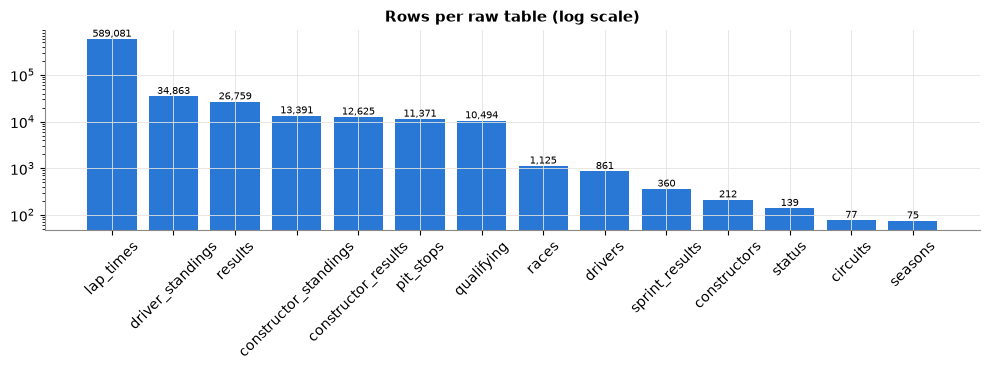

,rows,columns,missing cells,file MB
lap_times,589081,6,0,17.62
driver_standings,34863,7,0,0.88
results,26759,18,122887,1.72
constructor_standings,13391,7,0,0.32
constructor_results,12625,5,12608,0.22
pit_stops,11371,7,0,0.44
qualifying,10494,9,11668,0.47
races,1125,18,11349,0.16
drivers,861,9,1559,0.09
sprint_results,360,16,73,0.02


,read without na_values,read with na_values,contains \N
resultId,int64,int64,False
raceId,int64,int64,False
driverId,int64,int64,False
constructorId,int64,int64,False
number,str,float64,True
grid,int64,int64,False
position,str,float64,True
positionText,str,str,False
positionOrder,int64,int64,False
points,float64,float64,False


In [2]:
# read every CSV as plain text (for the audit) and with the placeholders turned into NaN (to work with)
raw_text = {name: pd.read_csv(RAW_DIR / f"{name}.csv", dtype=str, keep_default_na=False) for name in TABLES}
raw = {name: pd.read_csv(RAW_DIR / f"{name}.csv", na_values=NA_TOKENS, keep_default_na=False) for name in TABLES}

overview = pd.DataFrame({
    "rows": {n: len(df) for n, df in raw.items()},
    "columns": {n: df.shape[1] for n, df in raw.items()},
    "missing cells": {n: int(df.isna().sum().sum()) for n, df in raw.items()},
    "file MB": {n: round((RAW_DIR / f"{n}.csv").stat().st_size / 1e6, 2) for n in TABLES},
}).sort_values("rows", ascending=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(overview.index, overview["rows"], color=PALETTE[0])
ax.set_yscale("log")
for i, n in enumerate(overview["rows"]):
    ax.text(i, n, f"{n:,}", ha="center", va="bottom", fontsize=7)
ax.set_title("Rows per raw table (log scale)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
savefig(fig, "p1_tables_overview")
plt.show()
display(overview)

# what pandas does WITHOUT na_values: every column holding a \N becomes text
naive_results = pd.read_csv(RAW_DIR / "results.csv")
pd.DataFrame({"read without na_values": naive_results.dtypes.astype(str),
              "read with na_values": raw["results"].dtypes.astype(str),
              "contains \\N": raw_text["results"].eq(SENTINEL).any()})

**Hints.** 14 tables, from 75 to ~589,000 rows; `results` (26,759 rows) is the backbone of the modelling table.
Read without `na_values`, every column containing `\N` becomes text (second table).

### 1.2 Where are the missing-value placeholders?

Count `\N`, empty strings and extra spaces per column, and check that all of them became NaN.

every placeholder became NaN: True


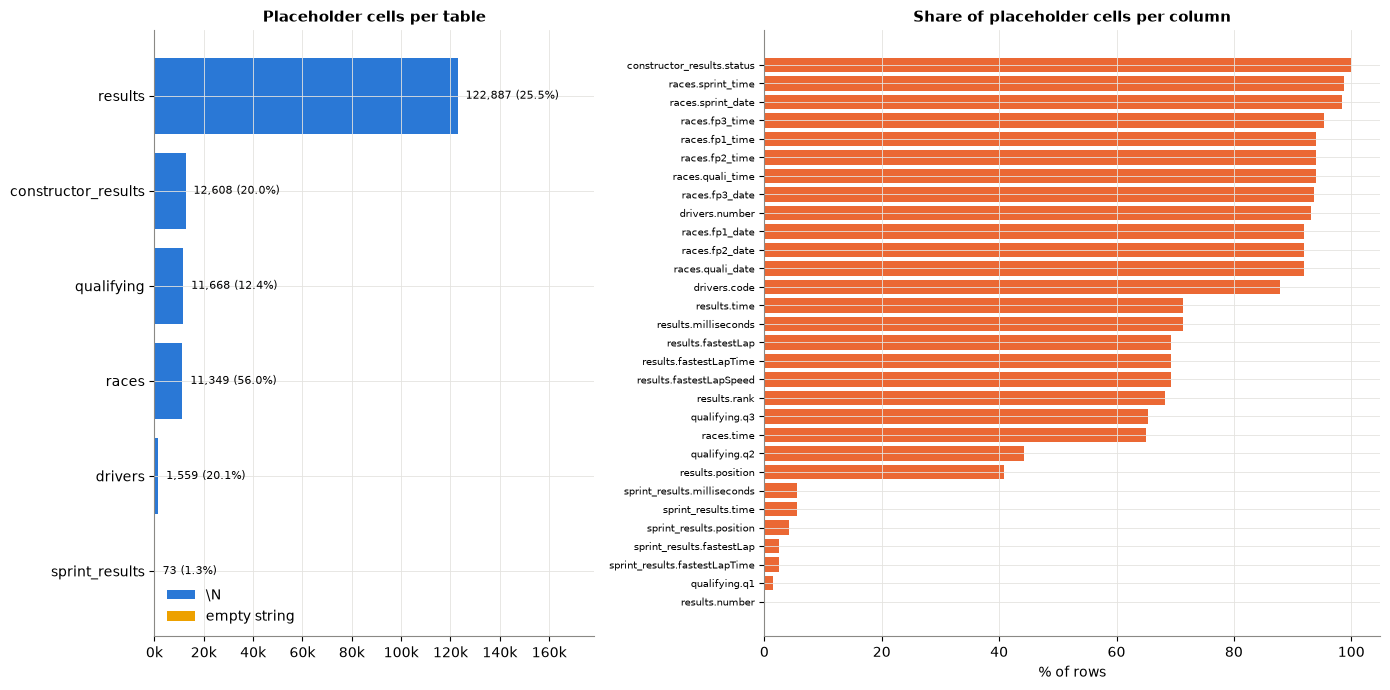

In [3]:
# count the placeholders per table / column on the text copy and check that loading caught all of them
placeholder_rows = []
for name, df in raw_text.items():
    for col in df.columns:
        n_sentinel, n_empty = int(df[col].eq(SENTINEL).sum()), int(df[col].eq("").sum())
        if n_sentinel + n_empty:
            placeholder_rows.append({"table": name, "column": col, r"\N cells": n_sentinel, "empty cells": n_empty,
                                     "NaN after loading": int(raw[name][col].isna().sum()),
                                     "% of rows": round(100 * (n_sentinel + n_empty) / len(df), 1)})
placeholders = pd.DataFrame(placeholder_rows)
caught_all = (placeholders[r"\N cells"] + placeholders["empty cells"] == placeholders["NaN after loading"]).all()
print("every placeholder became NaN:", caught_all)
assert caught_all

per_table = placeholders.groupby("table")[[r"\N cells", "empty cells"]].sum()
per_table["% of cells"] = (100 * per_table.sum(axis=1) / pd.Series({n: raw[n].size for n in per_table.index})).round(1)
per_table = per_table.sort_values(r"\N cells")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(per_table.index, per_table[r"\N cells"], color=PALETTE[0], label=r"\N")
axes[0].barh(per_table.index, per_table["empty cells"], left=per_table[r"\N cells"], color=PALETTE[3], label="empty string")
for y, (n, p) in enumerate(zip(per_table[r"\N cells"] + per_table["empty cells"], per_table["% of cells"])):
    axes[0].text(n, y, f"  {n:,} ({p}%)", va="center", fontsize=8)
axes[0].set_xlim(0, per_table.sum(axis=1).max() * 1.45)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
axes[0].set_title("Placeholder cells per table")
axes[0].legend()
cols = placeholders.sort_values("% of rows")
axes[1].barh(cols["table"] + "." + cols["column"], cols["% of rows"], color=PALETTE[1])
axes[1].set_title("Share of placeholder cells per column")
axes[1].set_xlabel("% of rows")
axes[1].tick_params(axis="y", labelsize=7)
fig.tight_layout()
savefig(fig, "p1_placeholders")
plt.show()

In [4]:
# which rows use the empty string instead of \N, and are there values with extra spaces?
empty_quali = raw_text["qualifying"]["q2"].eq("") | raw_text["qualifying"]["q3"].eq("")
display(raw["qualifying"][empty_quali].merge(raw["races"][["raceId", "year", "name"]], on="raceId")
        .groupby(["year", "name"]).size().rename("qualifying rows with an empty q2/q3").to_frame())
padded = [(n, col, repr(v)) for n, df in raw_text.items() for col in df.columns
          for v in df.loc[df[col].ne(df[col].str.strip()), col].unique()]
pd.DataFrame(padded, columns=["table", "column", "value with extra spaces"])

qualifying rows with an empty q2/q3
year name                                                          
2023 Abu Dhabi Grand Prix                                         9
2024 Azerbaijan Grand Prix                                       10
     Dutch Grand Prix                                             9
     Emilia Romagna Grand Prix                                    9
     Saudi Arabian Grand Prix                                     9

,table,column,value with extra spaces
0,drivers,nationality,'Argentinian '


**Hints.**
* `\N` in 6 tables, mostly structural (post-race columns of non-finishers, `q2`/`q3` of knocked-out drivers).
* A second placeholder: 68 empty strings in 2023–24 qualifying. Both are loaded as NaN; the check passes.
* One label with a trailing space (`'Argentinian '`, see 1.6).

### 1.3 Semantic typing

| Kind | Columns | Conversion |
|---|---|---|
| dates | `races.date`, `races.fp1/fp2/fp3/quali/sprint_date`, `drivers.dob` | → `datetime64` |
| durations | `qualifying.q1/q2/q3`, `lap_times.time`, `pit_stops.duration`, `results.fastestLapTime`, `sprint_results.fastestLapTime` | `"m:ss.sss"` → **seconds** (float) |
| integers that can be missing | `number`, `position`, `milliseconds`, `fastestLap`, `rank` | → nullable integer `Int64` |
| kept as text | `races.*_time`, `pit_stops.time` (clock times of day); `results.time` (mixes the winner's total time with "+gap" strings; the numeric version is `milliseconds`) | — |

`to_seconds` reads durations with 1–3 parts (`"26.898"`, `"1:26.572"`, `"1:02:03.400"`). Typed copies are in `tables`;
`raw` stays as loaded.

In [5]:
# convert dates, durations and nullable integers; check the conversion against the millisecond columns
def to_seconds(series):
    """'1:26.572' -> 86.572, '26.898' -> 26.898, '1:02:03.4' -> 3723.4; NaN stays NaN."""
    def one(value):
        if pd.isna(value):
            return np.nan
        seconds = 0.0
        for part in str(value).split(":"):     # hours, minutes, seconds from left to right
            seconds = seconds * 60 + float(part)
        return seconds
    return series.map(one).astype(float)


DATE_COLUMNS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"], "drivers": ["dob"]}
DURATION_COLUMNS = {"qualifying": ["q1", "q2", "q3"], "lap_times": ["time"], "pit_stops": ["duration"],
                    "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}
NULLABLE_INT_COLUMNS = {"results": ["number", "position", "milliseconds", "fastestLap", "rank"],
                        "sprint_results": ["number", "position", "milliseconds", "fastestLap"],
                        "qualifying": ["number"], "drivers": ["number"]}

tables = {name: df.copy() for name, df in raw.items()}
for name, df in tables.items():
    for col in DATE_COLUMNS.get(name, []):
        df[col] = pd.to_datetime(df[col], format="%Y-%m-%d")    # an explicit format raises an error instead of guessing
    for col in DURATION_COLUMNS.get(name, []):
        df[col] = to_seconds(df[col])
    for col in NULLABLE_INT_COLUMNS.get(name, []):
        df[col] = df[col].astype("Int64")

lap_err = (tables["lap_times"]["time"] * 1000 - tables["lap_times"]["milliseconds"]).abs().max()
pit_err = (tables["pit_stops"]["duration"] * 1000 - tables["pit_stops"]["milliseconds"]).abs().max()
print(f"largest difference to the milliseconds column: lap_times {lap_err:.3f} ms, pit_stops {pit_err:.3f} ms")
assert lap_err < 1 and pit_err < 1
assert all(tables[n].isna().sum().sum() == raw[n].isna().sum().sum() for n in TABLES), "typing must not create NaNs"

# columns whose meaning is a number / date / duration but which pandas stores as text, before and after typing
NATURAL_TEXT = {"circuitRef", "name", "location", "country", "url", "constructorRef", "nationality", "driverRef",
                "code", "forename", "surname", "positionText", "status"}
KEPT_AS_TEXT = {("races", "time"), ("pit_stops", "time"), ("results", "time"), ("sprint_results", "time"),
                ("constructor_results", "status")}


def wrongly_text(df, name):
    return [c for c in df.columns if (pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object)
            and c not in NATURAL_TEXT and not c.endswith("_time") and (name, c) not in KEPT_AS_TEXT]


typing_effect = pd.DataFrame({
    "read without na_values": {n: len(wrongly_text(pd.read_csv(RAW_DIR / f"{n}.csv"), n)) for n in TABLES},
    "after loading + typing": {n: len(wrongly_text(tables[n], n)) for n in TABLES},
}).query("`read without na_values` > 0")
typing_effect

largest difference to the milliseconds column: lap_times 0.000 ms, pit_stops 0.000 ms


,read without na_values,after loading + typing
drivers,2,0
races,6,0
results,7,0
qualifying,3,0
lap_times,1,0
pit_stops,1,0
sprint_results,4,0


**Plausibility check:** a qualifying lap slower than 150% of its session's best lap cannot be a real flying lap
(the 107% rule is the normal limit).

,year,name,surname,session,seconds,ratio_to_session_best
0,1995,Japanese Grand Prix,Blundell,q1,1002.64,10.23
1,2023,Austrian Grand Prix,Pérez,q2,126.69,1.95


laps above 150% of the session best: 2 of 19814; the next slowest lap is 145% of its session best


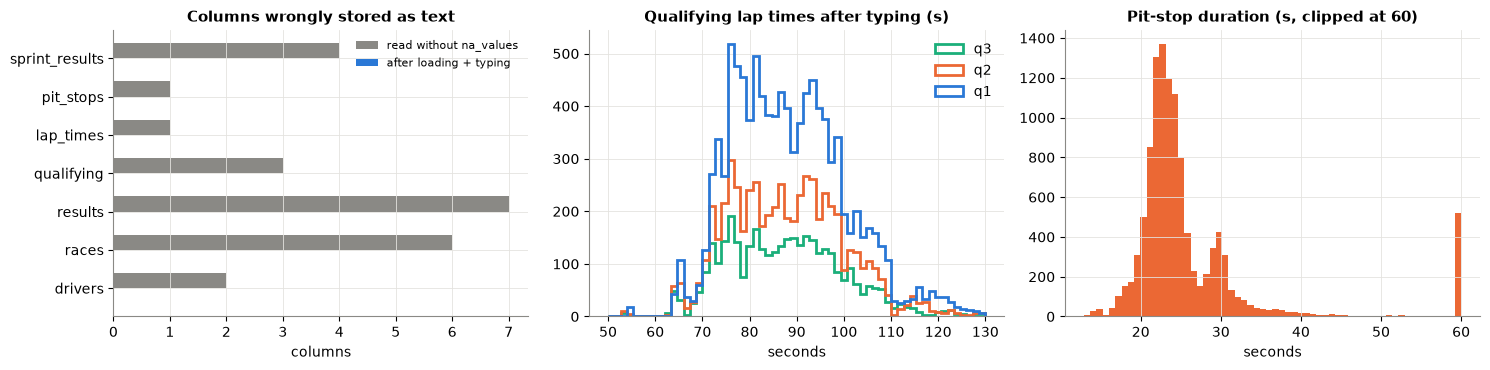

In [6]:
# flag qualifying laps slower than 150% of their session's best lap and set them to missing
q_long = (tables["qualifying"].melt(id_vars=["qualifyId", "raceId", "driverId"], value_vars=["q1", "q2", "q3"],
                                    var_name="session", value_name="seconds").dropna())
q_long["ratio_to_session_best"] = q_long["seconds"] / q_long.groupby(["raceId", "session"])["seconds"].transform("min")
implausible_laps = (q_long[q_long["ratio_to_session_best"] > 1.5]
                    .merge(tables["races"][["raceId", "year", "name"]], on="raceId")
                    .merge(tables["drivers"][["driverId", "surname"]], on="driverId"))
display(implausible_laps[["year", "name", "surname", "session", "seconds", "ratio_to_session_best"]].round(2))
print(f"laps above 150% of the session best: {len(implausible_laps)} of {len(q_long)}; the next slowest lap is "
      f"{q_long.loc[q_long['ratio_to_session_best'] <= 1.5, 'ratio_to_session_best'].max():.0%} of its session best")
for _, lap in implausible_laps.iterrows():
    tables["qualifying"].loc[tables["qualifying"]["qualifyId"] == lap["qualifyId"], lap["session"]] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
t = typing_effect
x = np.arange(len(t))
axes[0].barh(x + 0.2, t.iloc[:, 0], height=0.4, color=GREY, label=t.columns[0])
axes[0].barh(x - 0.2, t.iloc[:, 1], height=0.4, color=PALETTE[0], label=t.columns[1])
axes[0].set_yticks(x, t.index)
axes[0].set_title("Columns wrongly stored as text")
axes[0].set_xlabel("columns")
axes[0].legend(fontsize=8)
q = tables["qualifying"][["q1", "q2", "q3"]]
axes[1].hist([q[c].dropna() for c in q.columns], bins=60, range=(50, 130), color=PALETTE[:3], label=list(q.columns),
             histtype="step", linewidth=2)
axes[1].set_title("Qualifying lap times after typing (s)")
axes[1].set_xlabel("seconds")
axes[1].legend()
axes[2].hist(tables["pit_stops"]["duration"].clip(upper=60), bins=60, color=PALETTE[1])
axes[2].set_title("Pit-stop duration (s, clipped at 60)")
axes[2].set_xlabel("seconds")
fig.tight_layout()
savefig(fig, "p1_typing_effect")
plt.show()

**Hints.**
* No numbers, dates or durations left as text; converted times match the millisecond columns exactly.
* Two impossible laps set to missing: Blundell, 1995 Japan (10× the pole time, a typo) and Pérez, 2023 Austria Q2
  (≈ 2× the session best). Every other lap is within 145% of its session best.

### 1.4 Primary keys and the modelling grain

Primary keys must be unique and non-null; natural keys are checked too. Most important: `(raceId, driverId)` in
`results` = one row per driver per race.

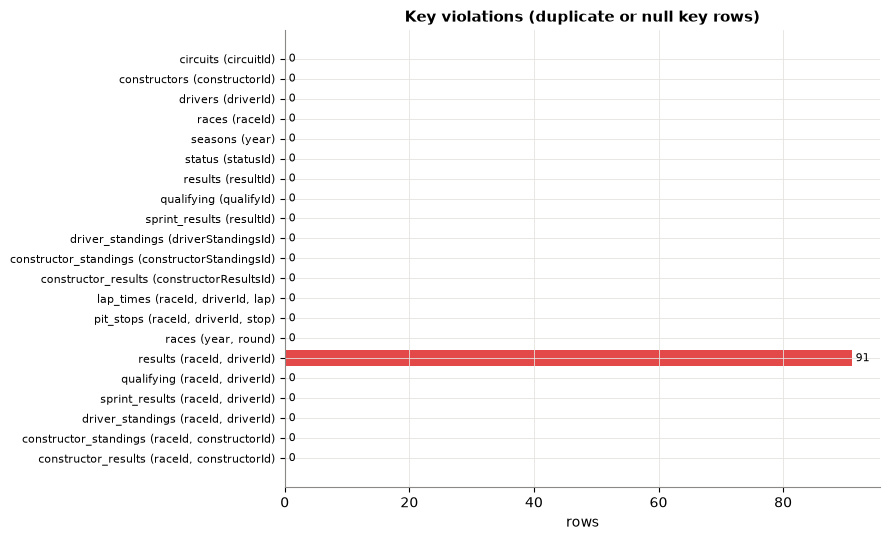

,table,key,kind,rows,null keys,duplicate rows,violations
0,circuits,circuitId,primary,77,0,0,0
1,constructors,constructorId,primary,212,0,0,0
2,drivers,driverId,primary,861,0,0,0
3,races,raceId,primary,1125,0,0,0
4,seasons,year,primary,75,0,0,0
5,status,statusId,primary,139,0,0,0
6,results,resultId,primary,26759,0,0,0
7,qualifying,qualifyId,primary,10494,0,0,0
8,sprint_results,resultId,primary,360,0,0,0
9,driver_standings,driverStandingsId,primary,34863,0,0,0


In [7]:
# check that every primary key and natural key is unique and non-null
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "sprint_results": ["resultId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
NATURAL_KEYS = {
    "races": ["year", "round"], "results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
    "sprint_results": ["raceId", "driverId"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "constructor_results": ["raceId", "constructorId"],
}


def key_audit(tables_, keys, kind):
    rows = []
    for name, cols in keys.items():
        df = tables_[name]
        rows.append({"table": name, "key": ", ".join(cols), "kind": kind, "rows": len(df),
                     "null keys": int(df[cols].isna().any(axis=1).sum()),
                     "duplicate rows": int(df.duplicated(cols).sum())})
    return pd.DataFrame(rows)


pk_report = pd.concat([key_audit(tables, PRIMARY_KEYS, "primary"), key_audit(tables, NATURAL_KEYS, "natural")],
                      ignore_index=True)
pk_report["violations"] = pk_report["null keys"] + pk_report["duplicate rows"]

fig, ax = plt.subplots(figsize=(9, 5.5))
t = pk_report.assign(label=pk_report["table"] + " (" + pk_report["key"] + ")").iloc[::-1]
ax.barh(t["label"], t["violations"], color=[PALETTE[7] if v else GREY for v in t["violations"]])
for y, v in enumerate(t["violations"]):
    ax.text(v, y, f" {v}", va="center", fontsize=8)
ax.set_title("Key violations (duplicate or null key rows)")
ax.set_xlabel("rows")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
savefig(fig, "p1_primary_keys")
plt.show()
pk_report

**Hints.** All primary keys are valid. Only violation: **91 extra `(raceId, driverId)` rows** in `results` = shared
drives (2.7), fixed in 3.5–3.7.

### 1.5 Foreign keys

Every reference must have a parent row. Also checks that qualifying, sprint, lap-time, pit-stop and standings rows
belong to a driver with a `results` row in that race.

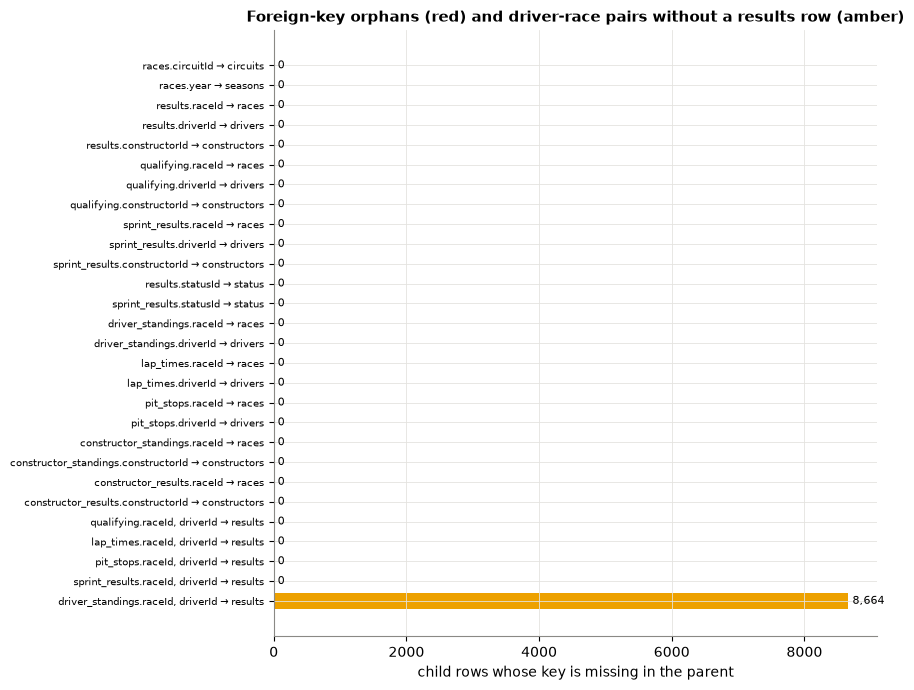

true foreign keys with orphans: 0


In [8]:
# check every foreign key, and the (raceId, driverId) pairs of the other tables against results
FOREIGN_KEYS = [("races", ["circuitId"], "circuits", ["circuitId"]), ("races", ["year"], "seasons", ["year"])]
for child in ["results", "qualifying", "sprint_results"]:
    FOREIGN_KEYS += [(child, ["raceId"], "races", ["raceId"]), (child, ["driverId"], "drivers", ["driverId"]),
                     (child, ["constructorId"], "constructors", ["constructorId"])]
FOREIGN_KEYS += [("results", ["statusId"], "status", ["statusId"]), ("sprint_results", ["statusId"], "status", ["statusId"])]
for child in ["driver_standings", "lap_times", "pit_stops"]:
    FOREIGN_KEYS += [(child, ["raceId"], "races", ["raceId"]), (child, ["driverId"], "drivers", ["driverId"])]
for child in ["constructor_standings", "constructor_results"]:
    FOREIGN_KEYS += [(child, ["raceId"], "races", ["raceId"]), (child, ["constructorId"], "constructors", ["constructorId"])]
for child in ["qualifying", "lap_times", "pit_stops", "sprint_results", "driver_standings"]:   # driver-race pairs
    FOREIGN_KEYS.append((child, ["raceId", "driverId"], "results", ["raceId", "driverId"]))


def fk_audit(tables_, fks):
    rows = []
    for child, ccols, parent, pcols in fks:
        child_keys = tables_[child][ccols].drop_duplicates()
        parent_keys = tables_[parent][pcols].drop_duplicates().set_axis(ccols, axis=1)
        merged = child_keys.merge(parent_keys, how="left", on=ccols, indicator=True)
        orphan_keys = merged.loc[merged["_merge"] == "left_only", ccols]
        rows.append({"child": child, "fk": ", ".join(ccols), "parent": parent,
                     "orphan rows": tables_[child].merge(orphan_keys, on=ccols).shape[0]})
    return pd.DataFrame(rows)


fk_report = fk_audit(tables, FOREIGN_KEYS)
fig, ax = plt.subplots(figsize=(9, 7))
t = fk_report.assign(label=fk_report["child"] + "." + fk_report["fk"] + " → " + fk_report["parent"]).iloc[::-1]
ax.barh(t["label"], t["orphan rows"], color=[GREY if v == 0 else (PALETTE[3] if p == "results" else PALETTE[7])
                                             for v, p in zip(t["orphan rows"], t["parent"])])
for y, v in enumerate(t["orphan rows"]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set_title("Foreign-key orphans (red) and driver-race pairs without a results row (amber)")
ax.set_xlabel("child rows whose key is missing in the parent")
ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
savefig(fig, "p1_foreign_keys")
plt.show()
print("true foreign keys with orphans:", int((fk_report.loc[fk_report["parent"] != "results", "orphan rows"] > 0).sum()))

**Hints.** 0 orphan foreign keys, so joins on IDs are safe. `driver_standings` has 8,664 pairs without a `results`
row: not an error (standings list every driver of the season, including drivers who missed that round).

### 1.6 Category labels

Checked by code: whitespace, near-duplicates (`difflib` similarity ≥ 0.75), abbreviations (`USA` vs `United States`)
and HTML codes (`&amp;`). Flags are only candidates (Austria ≠ Australia).

,column,check,label,similar to,rows
0,circuits.country,abbreviation,'USA','United States',11
1,circuits.country,near-duplicate,'Australia','Austria',2
2,circuits.country,near-duplicate,'Austria','Australia',2
3,drivers.nationality,near-duplicate,'Argentine','Argentinian',24
4,drivers.nationality,near-duplicate,'Australian','Austrian',19
5,drivers.nationality,near-duplicate,'Spanish','Danish',15
6,drivers.nationality,near-duplicate,'Austrian','Australian',15
7,drivers.nationality,near-duplicate,'Danish','Spanish',5
8,drivers.nationality,near-duplicate,'Indian','Indonesian',2
9,drivers.nationality,near-duplicate,'Argentine-Italian','Argentinian',1


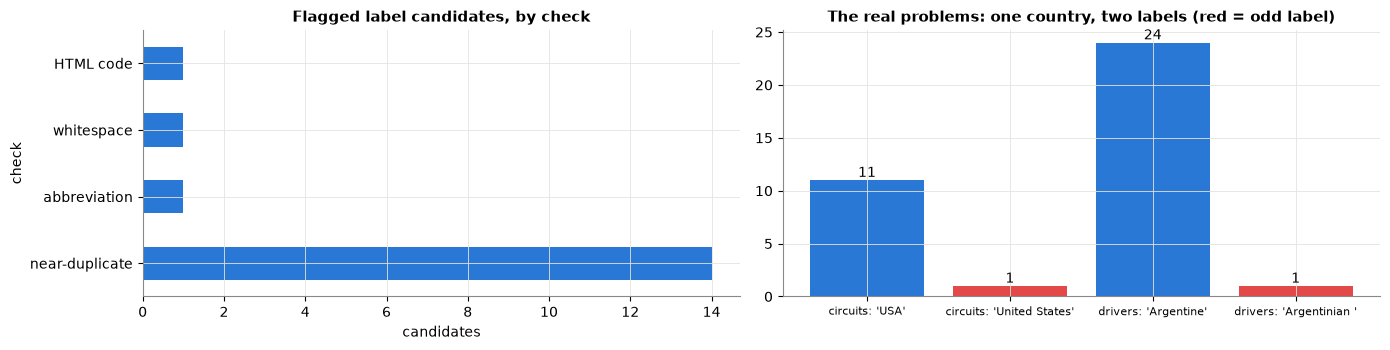

In [9]:
# flag label candidates (spaces, near-duplicates, abbreviations, HTML codes) and plot the real problems
def initials(label):
    return "".join(word[0] for word in label.split())


label_issues = []
for table, col in [("circuits", "country"), ("drivers", "nationality"), ("constructors", "nationality")]:
    counts = tables[table][col].value_counts()
    labels = list(counts.index)
    for label in labels:
        others = [o for o in labels if o != label]
        if label != label.strip():
            label_issues.append({"column": f"{table}.{col}", "check": "whitespace", "label": repr(label),
                                 "similar to": repr(label.strip()), "rows": counts[label]})
        for match in difflib.get_close_matches(label.strip(), [o.strip() for o in others], n=3, cutoff=0.75):
            label_issues.append({"column": f"{table}.{col}", "check": "near-duplicate", "label": repr(label),
                                 "similar to": repr(match), "rows": counts[label]})
        if label.isupper():
            for other in others:
                if " " in other and label.startswith(initials(other)):
                    label_issues.append({"column": f"{table}.{col}", "check": "abbreviation", "label": repr(label),
                                         "similar to": repr(other), "rows": counts[label]})
for name, df in raw_text.items():
    for col in df.columns:
        for value in df.loc[df[col].str.contains("&amp;|&lt;|&gt;|&quot;", regex=True), col].unique():
            label_issues.append({"column": f"{name}.{col}", "check": "HTML code", "label": repr(value),
                                 "similar to": repr(html.unescape(value)), "rows": int(df[col].eq(value).sum())})
label_issues = pd.DataFrame(label_issues)
display(label_issues)

real_problems = pd.Series({
    "circuits: 'USA'": int(tables["circuits"]["country"].eq("USA").sum()),
    "circuits: 'United States'": int(tables["circuits"]["country"].eq("United States").sum()),
    "drivers: 'Argentine'": int(tables["drivers"]["nationality"].eq("Argentine").sum()),
    "drivers: 'Argentinian '": int(tables["drivers"]["nationality"].eq("Argentinian ").sum()),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
label_issues["check"].value_counts().plot(kind="barh", ax=axes[0], color=PALETTE[0])
axes[0].set_title("Flagged label candidates, by check")
axes[0].set_xlabel("candidates")
axes[1].bar(real_problems.index, real_problems.values, color=[PALETTE[0], PALETTE[7], PALETTE[0], PALETTE[7]])
for i, v in enumerate(real_problems.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")
axes[1].set_title("The real problems: one country, two labels (red = odd label)")
axes[1].tick_params(axis="x", labelsize=8)
fig.tight_layout()
savefig(fig, "p1_labels")
plt.show()

**Hints.** Three real inconsistencies: Las Vegas Strip is `United States` (the 11 other US circuits are `USA`);
Colapinto is `'Argentinian '` (the 24 other drivers are `Argentine`); `Lotus-Pratt &amp; Whitney`. The other flagged
pairs are genuinely different, and `Argentine-Italian` is a real dual nationality. Fixed in 3.1.

### Phase 1 summary

| Finding | Section | Handling |
|---|---|---|
| `\N` placeholders, plus 68 empty strings in 2023–24 qualifying | 1.1, 1.2 | both loaded as NaN |
| dates and lap times stored as text; two impossible qualifying laps | 1.3 | typed; the two laps set to missing |
| all primary keys valid, all foreign keys reconcile | 1.4, 1.5 | joins on IDs are safe |
| 91 extra `(raceId, driverId)` rows | 1.4 | shared drives, fixed in 3.5–3.7 |
| `United States` / `USA`, `'Argentinian '` / `Argentine`, `&amp;` | 1.6 | labels normalised in 3.1 |

## 2. EDA before cleaning

The data as loaded (typed, nothing removed). Each part shows a problem that is fixed in Phase 3.

| Part | Evidence | Fixed / used in |
|---|---|---|
| 2.1 | Races, field size and podium rate per season, scope check, value of a top-3 grid slot by era | scope, metric choice, modelling window |
| 2.2 | Qualifying coverage per season | modelling window (2003+), qualifying features |
| 2.3 | Missing values per column, pre-race vs post-race | placeholder handling, feature choice |
| 2.4 | The Indianapolis 500 | 3.2 |
| 2.5 | Who never started: `grid == 0`, 0-lap rows by classification, the non-starter rule, status check | 3.3 |
| 2.6 | Average finish by grid slot, with pit-lane starters | 3.4 |
| 2.7 | Shared drives: drivers / places with several rows, who started each car | 3.5–3.7 |

`eda` = one row per raw result with its race, status, driver and team. `top3 = positionOrder <= 3` is only a plotting
helper; the target is defined in 3.9.

In [10]:
# one analysis table: every result row with race, status, driver and team attached; nothing removed
eda = (tables["results"]
       .merge(tables["races"][["raceId", "year", "round", "date", "name", "circuitId"]], on="raceId", how="left")
       .merge(tables["status"], on="statusId", how="left")
       .merge(tables["drivers"][["driverId", "surname", "nationality"]], on="driverId", how="left")
       .merge(tables["constructors"][["constructorId", "name"]].rename(columns={"name": "team"}), on="constructorId", how="left"))
assert len(eda) == len(tables["results"]), "a merge must not add or drop rows"
eda["top3"] = (eda["positionOrder"] <= 3).astype(int)
eda["is_indy500"] = eda["name"].eq("Indianapolis 500")
eda["decade"] = eda["year"] // 10 * 10
print(f"{len(eda):,} result rows | {eda['raceId'].nunique():,} races | {eda['year'].min()}–{eda['year'].max()} | "
      f"top-3 rate {eda['top3'].mean():.1%}")

26,759 result rows | 1,125 races | 1950–2024 | top-3 rate 12.7%


### 2.1 Races, field size and podium rate per season

3 podium places per race, so the podium share depends on the field size. Also checks that every season is within
1950–2024.

rows outside 1950-2024: 0


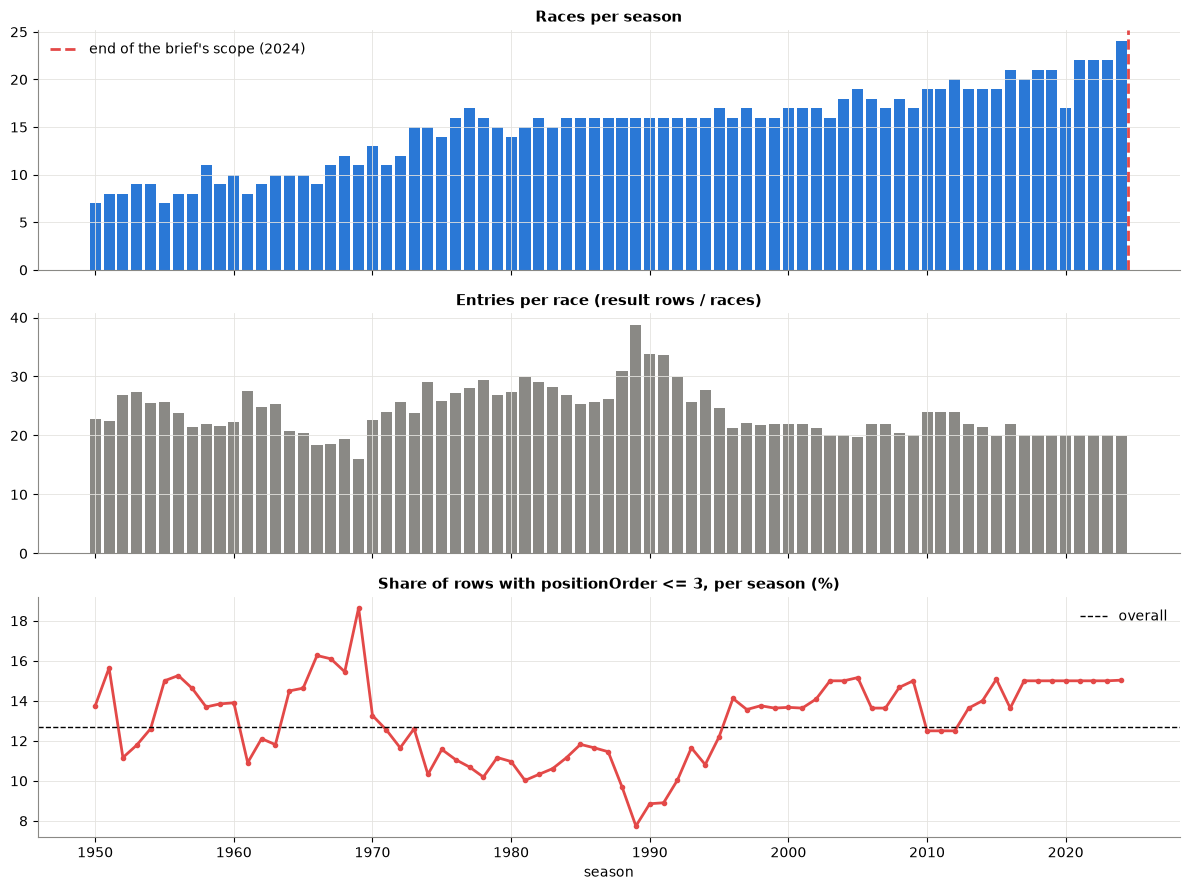

most entries per race: 1989 38.8 | lowest top-3 rate: 1989 7.7%
races by number of rows with positionOrder <= 3: {3: 1107, 4: 16, 5: 1, 7: 1}
seasons of the races with more than 3: [1950, 1951, 1953, 1954, 1955, 1956, 1957, 1960]


In [11]:
# scope check, then races / entries / top-3 rate per season
season = eda.groupby("year").agg(races=("raceId", "nunique"), rows=("raceId", "size"), top3_rate=("top3", "mean"))
season["entries_per_race"] = season["rows"] / season["races"]
outside = int((~eda["year"].between(1950, YEAR_MAX)).sum())
print(f"rows outside 1950-{YEAR_MAX}: {outside}")
assert outside == 0, "seasons outside the brief's scope -> filter them (D1)"

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].bar(season.index, season["races"], color=PALETTE[0])
axes[0].axvline(YEAR_MAX + 0.5, color=PALETTE[7], linestyle="--", label=f"end of the brief's scope ({YEAR_MAX})")
axes[0].set_title("Races per season")
axes[0].legend(loc="upper left")
axes[1].bar(season.index, season["entries_per_race"], color=GREY)
axes[1].set_title("Entries per race (result rows / races)")
axes[2].plot(season.index, season["top3_rate"] * 100, marker="o", markersize=3, color=PALETTE[7])
axes[2].axhline(eda["top3"].mean() * 100, linestyle="--", color="black", linewidth=1, label="overall")
axes[2].set_title("Share of rows with positionOrder <= 3, per season (%)")
axes[2].set_xlabel("season")
axes[2].legend()
fig.tight_layout()
savefig(fig, "p2_season_overview")
plt.show()
print("most entries per race:", season["entries_per_race"].idxmax(), round(season["entries_per_race"].max(), 1),
      "| lowest top-3 rate:", season["top3_rate"].idxmin(), f"{season['top3_rate'].min():.1%}")

top3_rows_per_race = eda.groupby("raceId")["top3"].sum()
print("races by number of rows with positionOrder <= 3:", top3_rows_per_race.value_counts().sort_index().to_dict())
print("seasons of the races with more than 3:",
      sorted(int(y) for y in eda.loc[eda["raceId"].isin(top3_rows_per_race[top3_rows_per_race > 3].index), "year"].unique()))

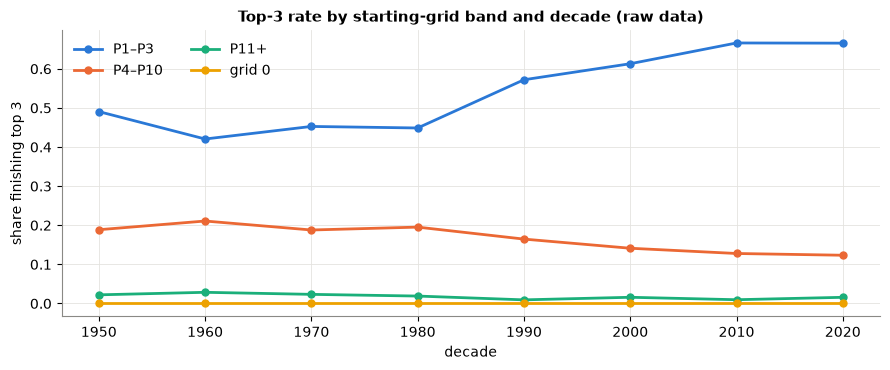

grid,grid 0,P1–P3,P4–P10,P11+
decade,,,,
1950,0.0,0.491,0.189,0.022
1960,0.0,0.421,0.211,0.029
1970,0.0,0.453,0.188,0.023
1980,0.0,0.449,0.195,0.019
1990,0.0,0.572,0.165,0.009
2000,0.0,0.613,0.141,0.016
2010,0.0,0.666,0.128,0.010
2020,0.0,0.666,0.123,0.016


In [12]:
# the value of a top-3 grid slot by era: podium rate per grid band and decade
grid_band = pd.cut(eda["grid"], [-1, 0, 3, 10, 100], labels=["grid 0", "P1–P3", "P4–P10", "P11+"])
by_band = eda.groupby(["decade", grid_band], observed=True)["top3"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, band in enumerate(["P1–P3", "P4–P10", "P11+", "grid 0"]):
    ax.plot(by_band.index, by_band[band], marker="o", markersize=5, color=PALETTE[i], label=band)
ax.set_title("Top-3 rate by starting-grid band and decade (raw data)")
ax.set_xlabel("decade")
ax.set_ylabel("share finishing top 3")
ax.legend(ncol=2)
fig.tight_layout()
savefig(fig, "p2_grid_band_by_era")
plt.show()
by_band.round(3)

**Hints.**
* Scope: no row outside 1950–2024 (the assert would catch a newer copy with 2025 races).
* Up to ~39 entries per race (1989) vs ~20 today, so the top-3 rate changes by era (lowest 7.7% in 1989, ~15% now).
* 18 races (1950–60) have more than 3 rows with `positionOrder <= 3`: shared drives (2.7).
* A P1–P3 start converted ~45% of the time in the 1960s–80s vs ~67% since 2010 → train on seasons similar to the
  test seasons.

### 2.2 Qualifying coverage per season

Share of result rows with a qualifying row, and the share of q1 / q2 / q3 times filled.

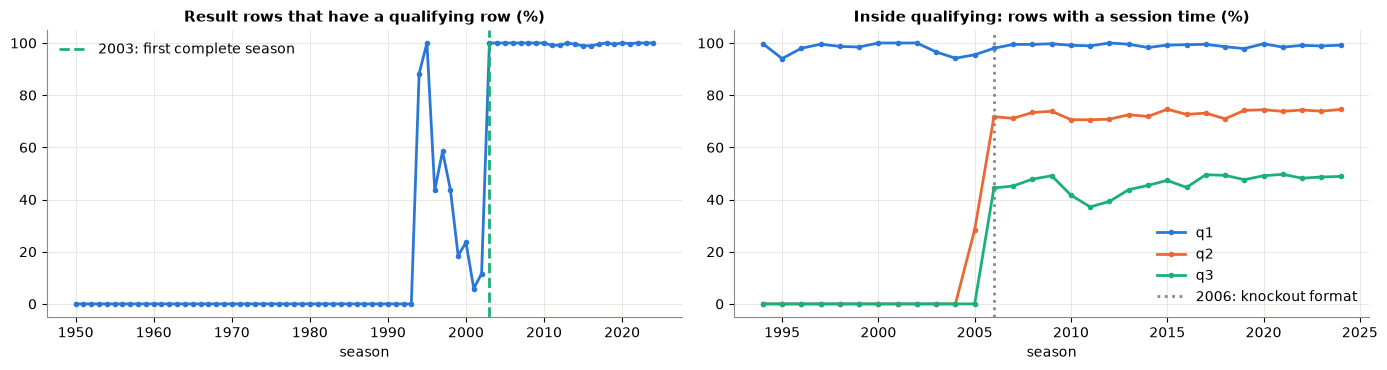

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
share with qualifying,0.0,0.88,1.0,0.44,0.59,0.44,0.18,0.24,0.06,0.12,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,0.99,1.0,1.0,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [13]:
# share of result rows with a qualifying row, and inside qualifying the share with each session time
quali_pairs = tables["qualifying"][["raceId", "driverId"]].assign(has_qualifying=True)
coverage = (eda.merge(quali_pairs, on=["raceId", "driverId"], how="left")
            .assign(has_qualifying=lambda d: d["has_qualifying"].fillna(False).astype(bool))
            .groupby("year")["has_qualifying"].mean())
quali_by_year = tables["qualifying"].merge(tables["races"][["raceId", "year"]], on="raceId")
session_filled = quali_by_year.groupby("year")[["q1", "q2", "q3"]].apply(lambda d: d.notna().mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(coverage.index, coverage * 100, marker="o", markersize=3, color=PALETTE[0])
axes[0].axvline(2003, color=PALETTE[2], linestyle="--", label="2003: first complete season")
axes[0].set_title("Result rows that have a qualifying row (%)")
axes[0].set_xlabel("season")
axes[0].legend()
for i, col in enumerate(["q1", "q2", "q3"]):
    axes[1].plot(session_filled.index, session_filled[col] * 100, marker="o", markersize=3, color=PALETTE[i], label=col)
axes[1].axvline(2006, color=GREY, linestyle=":", label="2006: knockout format")
axes[1].set_title("Inside qualifying: rows with a session time (%)")
axes[1].set_xlabel("season")
axes[1].legend()
fig.tight_layout()
savefig(fig, "p2_qualifying_coverage")
plt.show()
coverage[coverage.index >= 1993].round(2).to_frame("share with qualifying").T

**Hints.**
* No qualifying data before 1994, patchy 1994–2002, complete from **2003** → the modelling window starts in 2003.
* `q1` is almost always filled; from 2006 `q2`/`q3` exist only for drivers who reached them → qualifying pace uses
  **q1**; a missing `q3` means "knocked out".

### 2.3 Missing values per column: pre-race vs post-race

Missing share per column, coloured by known before / after the race (the prediction cutoff).

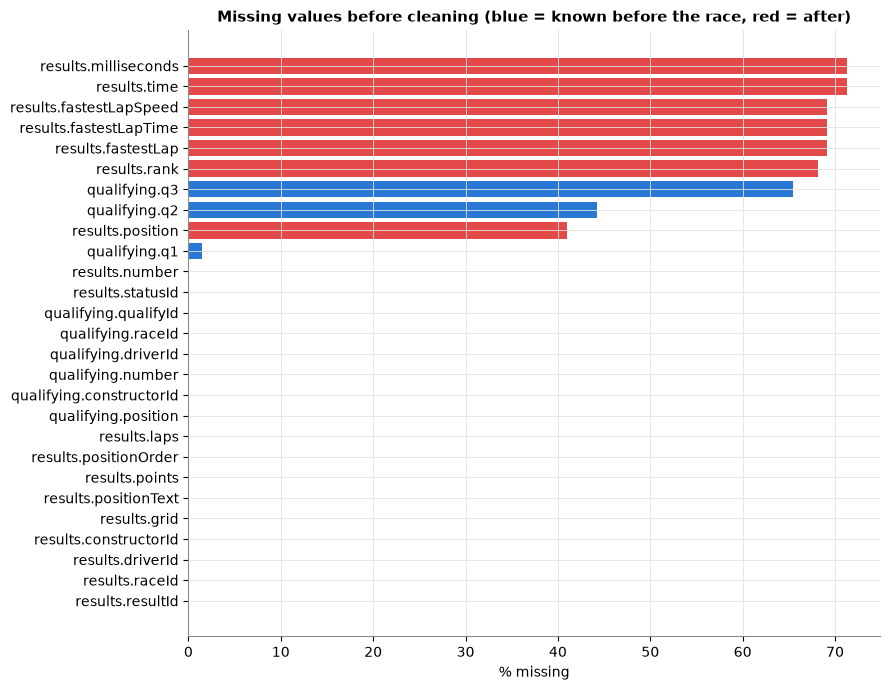

In [14]:
# missing share per column of results and qualifying, coloured by "known before / after the race"
POST_RACE_COLUMNS = ["position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
                     "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId"]
missing = pd.concat([(raw["results"].isna().mean() * 100).rename("missing %").to_frame().assign(table="results"),
                     (raw["qualifying"].isna().mean() * 100).rename("missing %").to_frame().assign(table="qualifying")])
missing["column"] = missing["table"] + "." + missing.index
missing["known"] = np.where((missing["table"] == "results") & missing.index.isin(POST_RACE_COLUMNS),
                            "after the race", "before the race")
missing = missing.sort_values("missing %")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(missing["column"], missing["missing %"], color=missing["known"].map({"before the race": PALETTE[0],
                                                                             "after the race": PALETTE[7]}))
ax.set_xlabel("% missing")
ax.set_title("Missing values before cleaning (blue = known before the race, red = after)")
fig.tight_layout()
savefig(fig, "p2_missing_pre_post")
plt.show()

**Hints.** Almost all missing values are in **post-race** columns (`time`, `milliseconds`, fastest lap,
`position`), which can never be features. The pre-race columns of `results` are complete; in qualifying only
`q2`/`q3` have gaps (by design). Imputation is needed only for missing *history* (Phase 6).

### 2.4 The Indianapolis 500

Part of the championship in 1950–60, but run under USAC rules by a mostly separate field: how to identify it, its
field size, and its effect on American results (Q2).

,min,max,races at circuit 19
name,,,
Indianapolis 500,1950,1960,11
United States Grand Prix,2000,2007,8


name
Indianapolis 500     11
Indian Grand Prix     3
Name: races, dtype: int64

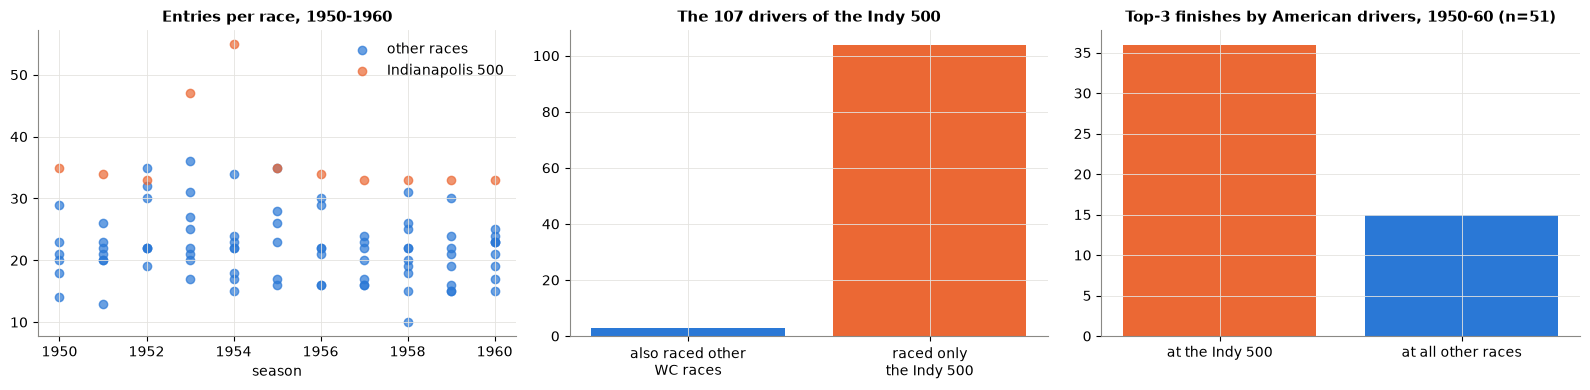

average entries per race 1950-60: {False: 22.0, True: 36.8} | Indy 500: 11 races, 405 rows


In [15]:
# how to identify the race (name vs circuit), and how different it was from the other races of its time
indy_races = tables["races"][tables["races"]["name"].eq("Indianapolis 500")]
display(tables["races"][tables["races"]["circuitId"].isin(indy_races["circuitId"])]
        .groupby("name")["year"].agg(["min", "max", "count"]).rename(columns={"count": "races at circuit 19"}))
display(tables["races"].loc[tables["races"]["name"].str.contains("Indian"), "name"].value_counts().rename("races"))

early = eda[eda["year"] <= 1960]
field = early.groupby(["raceId", "year", "is_indy500"]).size().rename("entries").reset_index()
indy_drivers = set(early.loc[early["is_indy500"], "driverId"])
other_drivers = set(early.loc[~early["is_indy500"], "driverId"])
american_top3 = early[early["nationality"].eq("American") & early["top3"].eq(1)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for is_indy, color, label in [(False, PALETTE[0], "other races"), (True, PALETTE[1], "Indianapolis 500")]:
    part = field[field["is_indy500"] == is_indy]
    axes[0].scatter(part["year"], part["entries"], color=color, label=label, alpha=0.7)
axes[0].set_title("Entries per race, 1950-1960")
axes[0].set_xlabel("season")
axes[0].legend()
axes[1].bar(["also raced other\nWC races", "raced only\nthe Indy 500"],
            [len(indy_drivers & other_drivers), len(indy_drivers - other_drivers)], color=[PALETTE[0], PALETTE[1]])
axes[1].set_title(f"The {len(indy_drivers)} drivers of the Indy 500")
axes[2].bar(["at the Indy 500", "at all other races"],
            [int(american_top3["is_indy500"].sum()), int((~american_top3["is_indy500"]).sum())], color=[PALETTE[1], PALETTE[0]])
axes[2].set_title(f"Top-3 finishes by American drivers, 1950-60 (n={len(american_top3)})")
fig.tight_layout()
savefig(fig, "p2_indy500")
plt.show()
print("average entries per race 1950-60:", field.groupby("is_indy500")["entries"].mean().round(1).to_dict(),
      "| Indy 500:", eda.loc[eda["is_indy500"], "raceId"].nunique(), "races,", int(eda["is_indy500"].sum()), "rows")

**Hints.**
* Identify it by its **exact name**: circuit 19 also hosted the US GP in 2000–07, and "Indian" would also match the
  Indian GP.
* ~37 entries per race vs ~22 for the other races; only 3 of its 107 drivers raced another championship race.
* 36 of the 51 American top-3 finishes of 1950–60 → it would fake a home advantage in Q2. Removed in 3.2 (11 races,
  405 rows).

### 2.5 Who never started the race?

Non-starters are known before the race and add easy negatives. First: what does `grid == 0` mean in each era?

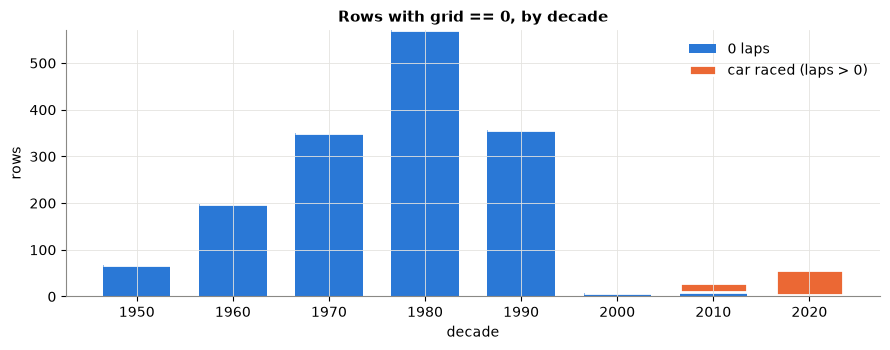

decade,1950,1960,1970,1980,1990,2000,2010,2020
kind,,,,,,,,
0 laps,68,198,351,571,357,8,9,4
car raced (laps > 0),0,0,0,0,0,0,19,53


In [16]:
# what grid == 0 means in each decade: did the car race (laps > 0) or not?
no_indy = eda[~eda["is_indy500"]]
grid0 = no_indy[no_indy["grid"] == 0].assign(kind=lambda d: np.where(d["laps"] > 0, "car raced (laps > 0)", "0 laps"))
grid0_by_decade = pd.crosstab(grid0["decade"], grid0["kind"])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(grid0_by_decade.index, grid0_by_decade["0 laps"], width=7, color=PALETTE[0], label="0 laps")
ax.bar(grid0_by_decade.index, grid0_by_decade["car raced (laps > 0)"], width=7, bottom=grid0_by_decade["0 laps"],
       color=PALETTE[1], label="car raced (laps > 0)", edgecolor="white", linewidth=2)
ax.set_title("Rows with grid == 0, by decade")
ax.set_xlabel("decade")
ax.set_ylabel("rows")
ax.legend()
fig.tight_layout()
savefig(fig, "p2_grid0_by_decade")
plt.show()
grid0_by_decade.T

**Hints.** Until the 2000s `grid == 0` means "did not race"; from the 2010s it is mostly a pit-lane start (2.6).
Neither `grid == 0` nor `laps == 0` alone works, so the rule combines `positionText` (F = failed to qualify,
W = withdrawn, R = retired, D = disqualified, E = excluded, N = not classified, a number = finished), `grid`, `laps`
and `status`.

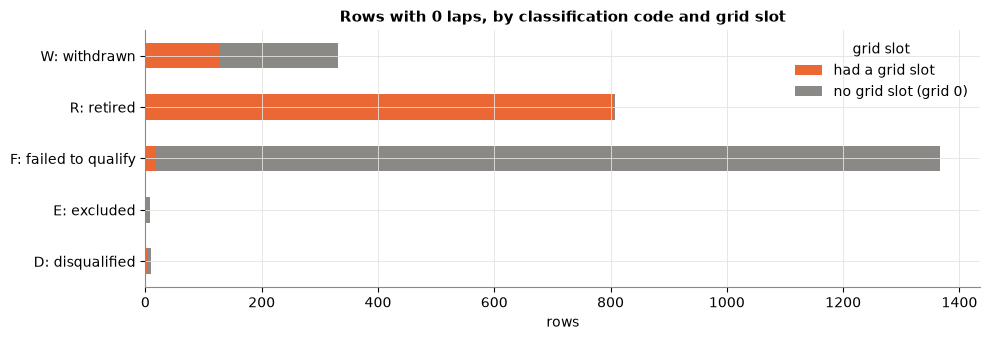

rows with 0 laps: 2523 | most common statuses of the R rows: {'Collision': 349, 'Accident': 213, 'Spun off': 37, 'Engine': 34, 'Gearbox': 26, 'Transmission': 23}


grid slot,had a grid slot,no grid slot (grid 0)
classification,,
D: disqualified,4,6
E: excluded,1,7
F: failed to qualify,19,1348
R: retired,805,2
W: withdrawn,128,203


In [17]:
# rows with 0 laps, by classification code and by whether the driver had a grid slot
zero_laps = no_indy[no_indy["laps"] == 0].copy()
code_names = {"F": "F: failed to qualify", "W": "W: withdrawn", "R": "R: retired", "D": "D: disqualified",
              "E": "E: excluded", "N": "N: not classified"}
zero_laps["classification"] = zero_laps["positionText"].map(code_names).fillna("finished")
zero_laps["grid slot"] = np.where(zero_laps["grid"] > 0, "had a grid slot", "no grid slot (grid 0)")
zero_by_code = zero_laps.groupby(["classification", "grid slot"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.5))
zero_by_code.plot(kind="barh", stacked=True, ax=ax, color=[PALETTE[1], GREY])
ax.set_title("Rows with 0 laps, by classification code and grid slot")
ax.set_xlabel("rows")
ax.set_ylabel("")
fig.tight_layout()
savefig(fig, "p2_zero_laps")
plt.show()
print(f"rows with 0 laps: {len(zero_laps)} | most common statuses of the R rows:",
      zero_laps.loc[zero_laps["positionText"] == "R", "status"].value_counts().head(6).to_dict())
zero_by_code

#### The rule

A driver **did not start** the race if any of these is true:
1. he **failed to qualify** (`positionText` F: did not qualify, did not pre-qualify, 107% rule);
2. he **withdrew before the start** (`positionText` W and 0 laps);
3. he had **no grid slot and 0 laps** (excluded or disqualified before the race, or never got to the grid);
4. he was **unfit to drive**: 0 laps and a health status (Injury, Injured, Physical, Illness, Driver unwell).

,rows,caught only by this condition
1. failed to qualify (F),1368,19
"2. withdrew before the start (W, 0 laps)",331,119
3. no grid slot and 0 laps,1566,15
"4. unfit to drive (health status, 0 laps)",23,3


non-starters: 1717 rows | top-3 among them: 0 | with a grid slot: 151 | since 2003: 61


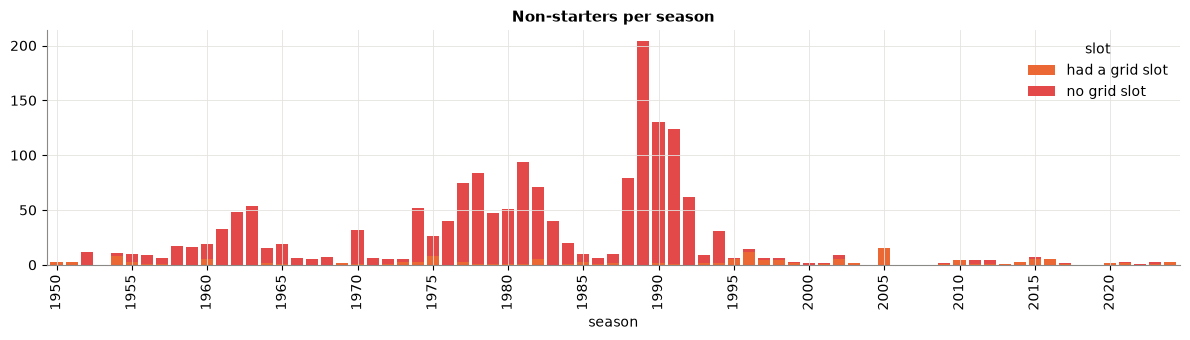

In [18]:
# the non-starter rule (decision D4), how many rows each condition catches, and the non-starters per season
HEALTH_STATUSES = ["Injury", "Injured", "Physical", "Illness", "Driver unwell"]


def is_non_starter(df):
    """True for every row of a driver who did not take the start of the race (decision D4)."""
    failed_to_qualify = df["positionText"] == "F"
    withdrew_before_start = (df["positionText"] == "W") & (df["laps"] == 0)
    no_grid_no_laps = (df["grid"] == 0) & (df["laps"] == 0)
    unfit_to_drive = df["status"].isin(HEALTH_STATUSES) & (df["laps"] == 0)
    return failed_to_qualify | withdrew_before_start | no_grid_no_laps | unfit_to_drive


conditions = pd.DataFrame({
    "1. failed to qualify (F)": no_indy["positionText"] == "F",
    "2. withdrew before the start (W, 0 laps)": (no_indy["positionText"] == "W") & (no_indy["laps"] == 0),
    "3. no grid slot and 0 laps": (no_indy["grid"] == 0) & (no_indy["laps"] == 0),
    "4. unfit to drive (health status, 0 laps)": no_indy["status"].isin(HEALTH_STATUSES) & (no_indy["laps"] == 0),
})
only_this = conditions & (conditions.sum(axis=1) == 1).to_numpy()[:, None]
display(pd.DataFrame({"rows": conditions.sum(), "caught only by this condition": only_this.sum()}))

non_starter = is_non_starter(no_indy)
print(f"non-starters: {non_starter.sum()} rows | top-3 among them: {no_indy.loc[non_starter, 'top3'].sum()} | "
      f"with a grid slot: {(non_starter & (no_indy['grid'] > 0)).sum()} | since 2003: {(non_starter & (no_indy['year'] >= 2003)).sum()}")

per_season_ns = (no_indy[non_starter].assign(slot=lambda d: np.where(d["grid"] > 0, "had a grid slot", "no grid slot"))
                 .groupby(["year", "slot"]).size().unstack(fill_value=0).reindex(range(1950, 2025), fill_value=0))
fig, ax = plt.subplots(figsize=(12, 3.5))
per_season_ns.plot(kind="bar", stacked=True, ax=ax, color=[PALETTE[1], PALETTE[7]], width=0.8)
ax.set_title("Non-starters per season")
ax.set_xlabel("season")
ax.set_xticks(range(0, 75, 5))
ax.set_xticklabels(range(1950, 2025, 5))
fig.tight_layout()
savefig(fig, "p2_non_starters")
plt.show()

#### Status check: did the rule miss anyone?

(a) Every "did not start" status should be caught. (b) 0-lap rows kept by conditions 1–3 should have an in-race
reason; the others are listed with the action taken.

,rows,caught by the rule,"not caught, laps > 0 (raced)","not caught, 0 laps"
status,,,,
Did not qualify,1025,1025,0,0
Did not prequalify,331,331,0,0
107% Rule,9,9,0,0
Withdrew,248,223,23,2


,year,name,surname,grid,laps,positionText,status,decision
11301,1982,Canadian Grand Prix,Jarier,18,0,R,Withdrew,"kept: classified R (retired), so he took the s..."
8478,1989,Australian Grand Prix,Prost,2,0,R,Withdrew,"kept: classified R (retired), so he took the s..."
19796,1952,German Grand Prix,Bianco,16,0,R,Retired,kept: no reason given (limitation)
19553,1953,British Grand Prix,McAlpine,13,0,R,Retired,kept: no reason given (limitation)
19587,1953,German Grand Prix,von Stuck,23,0,R,Retired,kept: no reason given (limitation)
13994,1976,German Grand Prix,Amon,17,0,R,Retired,kept: no reason given (limitation)
11274,1982,Detroit Grand Prix,Paletti,23,0,R,Retired,kept: no reason given (limitation)
9895,1985,San Marino Grand Prix,Palmer,17,0,R,Retired,kept: no reason given (limitation)
22890,2015,Brazilian Grand Prix,Sainz,10,0,R,Retired,kept: no reason given (limitation)
14796,1974,British Grand Prix,Gethin,21,0,R,Physical,"removed by condition 4: health reason, could n..."


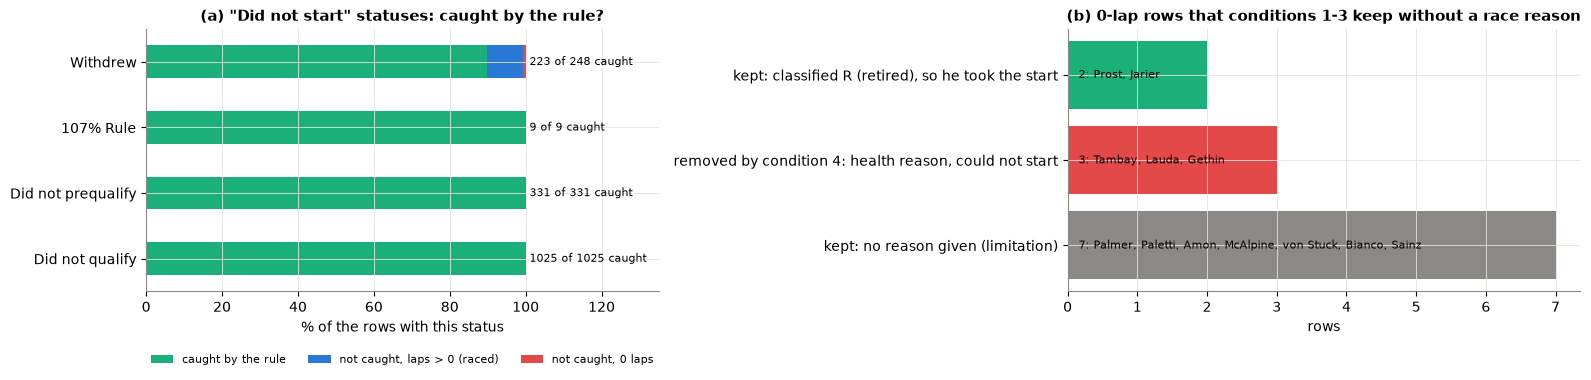

,year,name,surname,grid,laps,positionText,status,positionOrder,non_starter
25059,2021,Monaco Grand Prix,Leclerc,1,0,W,Driveshaft,20,True
25041,2021,Monaco Grand Prix,Verstappen,2,78,1,Finished,1,False
25058,2021,Monaco Grand Prix,Bottas,3,29,R,Wheel nut,19,False
25040,2021,Monaco Grand Prix,Sainz,4,78,2,Finished,2,False


In [19]:
# (a) "did not start" statuses caught by the rule; (b) 0-lap rows kept by conditions 1-3 without a race reason
status_rows = []
for s in ["Did not qualify", "Did not prequalify", "107% Rule", "Withdrew"]:
    rows = no_indy[no_indy["status"] == s]
    caught = non_starter[rows.index]
    status_rows.append({"status": s, "rows": len(rows), "caught by the rule": int(caught.sum()),
                        "not caught, laps > 0 (raced)": int((~caught & (rows["laps"] > 0)).sum()),
                        "not caught, 0 laps": int((~caught & (rows["laps"] == 0)).sum())})
status_df = pd.DataFrame(status_rows).set_index("status")
display(status_df)

caught_by_1_to_3 = conditions.iloc[:, :3].any(axis=1)
edge = no_indy[~caught_by_1_to_3 & (no_indy["laps"] == 0)
               & no_indy["status"].isin(["Withdrew", "Retired"] + HEALTH_STATUSES)].copy()
edge["decision"] = np.select([edge["status"].isin(HEALTH_STATUSES), edge["status"] == "Withdrew"],
                             ["removed by condition 4: health reason, could not start",
                              "kept: classified R (retired), so he took the start"],
                             default="kept: no reason given (limitation)")
display(edge.sort_values(["decision", "year"])[["year", "name", "surname", "grid", "laps", "positionText", "status", "decision"]])

parts = ["caught by the rule", "not caught, laps > 0 (raced)", "not caught, 0 laps"]
shares = status_df[parts].div(status_df["rows"], axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
shares.plot(kind="barh", stacked=True, ax=axes[0], color=[PALETTE[2], PALETTE[0], PALETTE[7]])
for i, s in enumerate(status_df.index):
    axes[0].text(101, i, f"{status_df.loc[s, 'caught by the rule']} of {status_df.loc[s, 'rows']} caught", va="center", fontsize=8)
axes[0].set_xlim(0, 135)
axes[0].set_xlabel("% of the rows with this status")
axes[0].set_ylabel("")
axes[0].set_title('(a) "Did not start" statuses: caught by the rule?')
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
decisions = edge["decision"].value_counts()
decision_colors = {"kept: classified R (retired), so he took the start": PALETTE[2],
                   "kept: no reason given (limitation)": GREY,
                   "removed by condition 4: health reason, could not start": PALETTE[7]}
axes[1].barh(decisions.index, decisions.values, color=[decision_colors[d] for d in decisions.index])
for i, d in enumerate(decisions.index):
    axes[1].text(0.1, i, f" {decisions[d]}: {', '.join(edge.loc[edge['decision'] == d, 'surname'])}", va="center", fontsize=8)
axes[1].set_title("(b) 0-lap rows that conditions 1-3 keep without a race reason")
axes[1].set_xlabel("rows")
fig.tight_layout()
savefig(fig, "p2_status_check")
plt.show()

# grid slots of non-starters: does the car behind move up?
monaco_2021 = no_indy[(no_indy["year"] == 2021) & (no_indy["name"] == "Monaco Grand Prix")].sort_values("grid")
monaco_2021.assign(non_starter=is_non_starter(monaco_2021))[["year", "name", "surname", "grid", "laps", "positionText",
                                                             "status", "positionOrder", "non_starter"]].head(4)

**Hints.**
* 0 laps ≠ did not start: most R rows with 0 laps are first-lap crashes.
* The rule finds 1,717 non-starters, **none** in the top 3; 151 had a grid slot (e.g. Leclerc, pole at Monaco 2021;
  the 14 Michelin cars at the 2005 US GP).
* Status check passes. Prost (1989) and Jarier (1982): "Withdrew" with 0 laps but classified R, so they started
  and stay.
* Limitation: a few 0-lap "Retired" rows without a reason are kept.
* Empty grid slots stay empty (Verstappen started P2 behind Leclerc's empty pole slot), so `grid` is not renumbered.

### 2.6 Pit-lane starters: where does grid 0 belong?

As a number, `grid = 0` looks better than pole. How do pit-lane starters (grid 0, laps > 0) finish compared with each
grid slot?

pit-lane starters (grid 0, laps > 0) per season: {2015: 1, 2016: 4, 2017: 1, 2018: 1, 2019: 12, 2020: 5, 2021: 11, 2022: 10, 2023: 16, 2024: 11} | top-3 finishes: 0


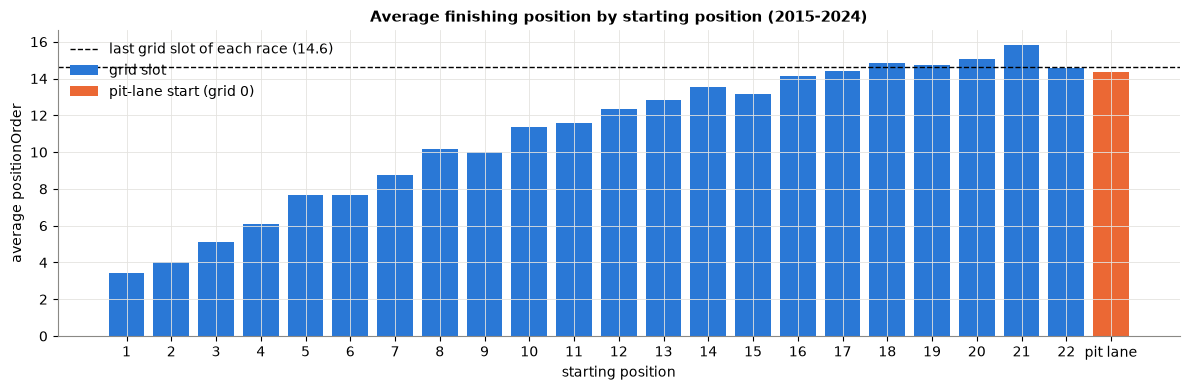

average finish: pole 3.4 | last grid slot 14.6 | pit lane 14.4


In [20]:
# average finish by grid slot vs pit-lane starters, in the seasons where pit-lane starts are recorded as grid 0
pit_lane = eda[(eda["grid"] == 0) & (eda["laps"] > 0)]
print("pit-lane starters (grid 0, laps > 0) per season:", pit_lane.groupby("year").size().to_dict(),
      "| top-3 finishes:", int(pit_lane["top3"].sum()))
first_year = int(pit_lane["year"].min())
recent = eda[eda["year"] >= first_year].copy()
recent["last_slot"] = recent["grid"] == recent.groupby("raceId")["grid"].transform("max")
avg_by_slot = recent[recent["grid"] > 0].groupby("grid")["positionOrder"].mean()
pit_lane_avg = pit_lane["positionOrder"].mean()
last_slot_avg = recent.loc[recent["last_slot"], "positionOrder"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(avg_by_slot.index.astype(str), avg_by_slot.values, color=PALETTE[0], label="grid slot")
ax.bar(["pit lane"], [pit_lane_avg], color=PALETTE[1], label="pit-lane start (grid 0)")
ax.axhline(last_slot_avg, color="black", linestyle="--", linewidth=1, label=f"last grid slot of each race ({last_slot_avg:.1f})")
ax.set_title(f"Average finishing position by starting position ({first_year}-2024)")
ax.set_xlabel("starting position")
ax.set_ylabel("average positionOrder")
ax.legend()
fig.tight_layout()
savefig(fig, "p2_pitlane_vs_grid")
plt.show()
print(f"average finish: pole {avg_by_slot.loc[1]:.1f} | last grid slot {last_slot_avg:.1f} | pit lane {pit_lane_avg:.1f}")

**Hints.** Pit-lane starters finish ~P14.4, like the last grid slot (14.6), not like pole (3.4); none reached the
top 3. Recorded as `grid = 0` only from 2015 (72 rows). Recoded to last slot + 1, plus a `pitlane_start` flag (3.4).

### 2.7 Shared drives

Until the mid-1960s drivers could swap cars during a race. One row per driver per car gives two symptoms:
1. one driver, several rows in a race (breaks the grain `(raceId, driverId)`);
2. one finishing place, several rows (one car, several drivers).

symptom 1 - one driver, several rows: 85 drivers (176 rows)
symptom 2 - one place, several rows : 105 places (228 rows)
every shared place has a single car number: True | a single laps value: True


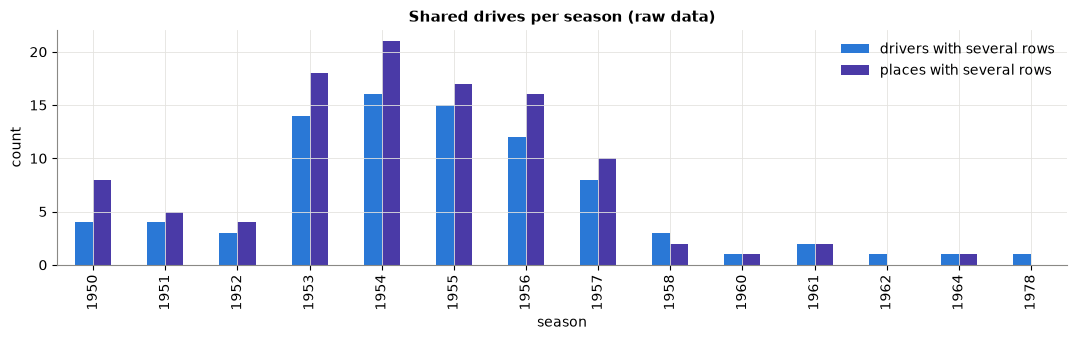

,year,name,positionOrder,number,surname,grid,laps,points,status
19241,1954,Indianapolis 500,11,45,Cross,27,200,0.0,Finished
20217,1954,Indianapolis 500,11,45,Parsons,27,200,0.0,Finished
20218,1954,Indianapolis 500,11,45,Hanks,27,200,0.0,Finished
20219,1954,Indianapolis 500,11,45,Linden,27,200,0.0,Finished
20220,1954,Indianapolis 500,11,45,Davies,27,200,0.0,Finished


In [21]:
# both symptoms per season, and the most extreme shared car
driver_dups = eda[eda.duplicated(["raceId", "driverId"], keep=False)]
place_dups = eda[eda.duplicated(["raceId", "positionOrder"], keep=False)]
places = (place_dups.groupby(["raceId", "positionOrder"])
          .agg(year=("year", "first"), drivers=("driverId", "nunique"), car_numbers=("number", "nunique"),
               laps_values=("laps", "nunique")).reset_index())
print(f"symptom 1 - one driver, several rows: {driver_dups.groupby(['raceId', 'driverId']).ngroups} drivers ({len(driver_dups)} rows)")
print(f"symptom 2 - one place, several rows : {len(places)} places ({len(place_dups)} rows)")
print(f"every shared place has a single car number: {(places['car_numbers'] == 1).all()} | "
      f"a single laps value: {(places['laps_values'] == 1).all()}")

per_season_shared = pd.DataFrame({
    "drivers with several rows": driver_dups.drop_duplicates(["raceId", "driverId"]).groupby("year").size(),
    "places with several rows": places.groupby("year").size()}).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 3.5))
per_season_shared.plot(kind="bar", ax=ax, color=[PALETTE[0], PALETTE[6]])
ax.set_title("Shared drives per season (raw data)")
ax.set_xlabel("season")
ax.set_ylabel("count")
fig.tight_layout()
savefig(fig, "p2_shared_drives_per_season")
plt.show()

biggest = places.sort_values("drivers", ascending=False).iloc[0]
eda[(eda["raceId"] == biggest["raceId"]) & (eda["positionOrder"] == biggest["positionOrder"])][
    ["year", "name", "positionOrder", "number", "surname", "grid", "laps", "points", "status"]]

In [22]:
# a documented example: Fangio at the 1956 Argentine GP (pole in car 30, retired, then took over Musso's car 34)
eda[(eda["year"] == 1956) & (eda["name"] == "Argentine Grand Prix") & eda["number"].isin([30, 34])][
    ["resultId", "surname", "team", "number", "grid", "positionOrder", "laps", "points", "status"]].sort_values("resultId")

,resultId,surname,team,number,grid,positionOrder,laps,points,status
18882,18883,Musso,Ferrari,34,3,1,98,4.0,Finished
18894,18895,Fangio,Ferrari,30,1,13,22,0.0,Fuel pump
20266,20267,Fangio,Ferrari,34,3,1,98,5.0,Finished


**Hints.** 85 drivers with several rows and 105 shared places, almost all in 1950–64. Every shared place has one
car number and one laps value → a car = `(raceId, positionOrder)`, and `grid`, `laps` and the result belong to the
car. Example: Fangio, 1956 Argentine GP: his own car #30 (pole, retired) and Musso's car #34 (shared win).

#### Who started each car?

Each row should describe the driver who **started** that car (as in modern F1, where swaps are forbidden). Rules, in
order:
1. a driver who is **alone** in a car started it;
2. a driver starts **only one** car: drivers who already own a car (rule 1) are not candidates; if one candidate is
   left, he started it;
3. otherwise the driver listed **first in the file** (lowest `resultId`).

Tested on a preview without the Indy 500 and the non-starters, and checked against race reports (`races.url`).

shared cars after D3 + D4: 74 | every shared car got exactly one starter: True


,race,car,started by (race report),our rules pick,decided by,first in the file,rules correct,file order correct
0,1950 Italian Grand Prix,#48,Serafini,Serafini,rule 2: only candidate left,Serafini,True,True
1,1951 French Grand Prix,#8,Fagioli,Fagioli,rule 3: first in the file,Fagioli,True,True
2,1951 French Grand Prix,#14,González,González,rule 2: only candidate left,Ascari,True,False
3,1951 Italian Grand Prix,#40,Bonetto,Bonetto,rule 2: only candidate left,Bonetto,True,True
4,1954 Belgian Grand Prix,#10,Hawthorn,Hawthorn,rule 2: only candidate left,González,True,False
5,1956 Argentine Grand Prix,#34,Musso,Musso,rule 2: only candidate left,Musso,True,True
6,1957 British Grand Prix,#20,Brooks,Brooks,rule 3: first in the file,Brooks,True,True
7,1961 British Grand Prix,#26,Fairman,Fairman,rule 2: only candidate left,Moss,True,False
8,1964 United States Grand Prix,#2,Spence,Spence,rule 2: only candidate left,Spence,True,True


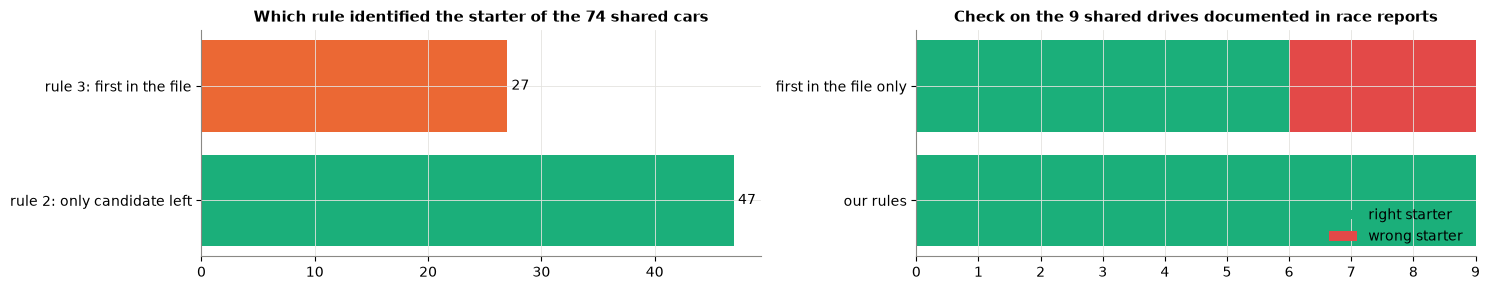

our rules: 9 of 9 correct | file order alone: 6 of 9 correct


In [23]:
# the starter rules, applied to a preview of the table after D3 + D4, and checked against race reports
def find_starters(df):
    """Adds `started_car` (True = this driver started this car) and `decided_by` (which rule decided it)."""
    df = df.copy()
    df["car_drivers"] = df.groupby(["raceId", "positionOrder"])["driverId"].transform("nunique")
    df["started_car"] = df["car_drivers"] == 1                                     # rule 1: alone in the car
    df["decided_by"] = np.where(df["started_car"], "rule 1: alone in the car", "")
    for (race, place), car in df[df["car_drivers"] > 1].sort_values("resultId").groupby(["raceId", "positionOrder"]):
        owners = set(df.loc[(df["raceId"] == race) & df["started_car"], "driverId"])
        candidates = car[~car["driverId"].isin(owners)]                            # rule 2: drivers without a car yet
        if len(candidates) == 0:
            continue
        rule = "rule 2: only candidate left" if len(candidates) == 1 else "rule 3: first in the file"
        df.loc[candidates.index[0], ["started_car", "decided_by"]] = [True, rule]
    return df


pre = find_starters(eda[~eda["is_indy500"] & ~is_non_starter(eda)])
shared_rows = pre[pre["car_drivers"] > 1]
starters_per_car = shared_rows.groupby(["raceId", "positionOrder"])["started_car"].sum()
print(f"shared cars after D3 + D4: {len(starters_per_car)} | every shared car got exactly one starter: "
      f"{(starters_per_car == 1).all()}")

documented = pd.DataFrame([
    (1950, "Italian Grand Prix", 48, "Serafini"), (1951, "French Grand Prix", 8, "Fagioli"),
    (1951, "French Grand Prix", 14, "González"), (1951, "Italian Grand Prix", 40, "Bonetto"),
    (1954, "Belgian Grand Prix", 10, "Hawthorn"), (1956, "Argentine Grand Prix", 34, "Musso"),
    (1957, "British Grand Prix", 20, "Brooks"), (1961, "British Grand Prix", 26, "Fairman"),
    (1964, "United States Grand Prix", 2, "Spence")], columns=["year", "name", "number", "started by (race report)"])
check_rows = []
for _, case_ in documented.iterrows():
    car = pre[(pre["year"] == case_["year"]) & (pre["name"] == case_["name"]) & (pre["number"] == case_["number"])]
    check_rows.append({"race": f"{case_['year']} {case_['name']}", "car": f"#{case_['number']}",
                       "started by (race report)": case_["started by (race report)"],
                       "our rules pick": ", ".join(car.loc[car["started_car"], "surname"]),
                       "decided by": ", ".join(car.loc[car["started_car"], "decided_by"]),
                       "first in the file": car.sort_values("resultId")["surname"].iloc[0]})
starter_check = pd.DataFrame(check_rows)
starter_check["rules correct"] = starter_check["our rules pick"] == starter_check["started by (race report)"]
starter_check["file order correct"] = starter_check["first in the file"] == starter_check["started by (race report)"]
display(starter_check)

decided = shared_rows.loc[shared_rows["started_car"], "decided_by"].value_counts()
right = [int(starter_check["rules correct"].sum()), int(starter_check["file order correct"].sum())]
fig, axes = plt.subplots(1, 2, figsize=(15, 3))
axes[0].barh(decided.index, decided.values, color=[PALETTE[2], PALETTE[1]])
for i, v in enumerate(decided.values):
    axes[0].text(v, i, f" {v}", va="center")
axes[0].set_title(f"Which rule identified the starter of the {len(starters_per_car)} shared cars")
axes[1].barh(["our rules", "first in the file only"], right, color=PALETTE[2], label="right starter")
axes[1].barh(["our rules", "first in the file only"], [len(starter_check) - r for r in right], left=right,
             color=PALETTE[7], label="wrong starter")
axes[1].set_title(f"Check on the {len(starter_check)} shared drives documented in race reports")
axes[1].legend(loc="lower right")
fig.tight_layout()
savefig(fig, "p2_starter_rules")
plt.show()
print(f"our rules: {right[0]} of {len(starter_check)} correct | file order alone: {right[1]} of {len(starter_check)} correct")

**Hints.** Every shared car gets exactly one starter (rule 2: 47 cars, rule 3: 27). On the 9 shared drives described
in race reports the rules are right **9 of 9** times; file order alone 6 of 9. Limitation: rule-3 cars rely on file
order.

### Phase 2 summary

| Evidence | Action |
|---|---|
| Field size and top-3 rate change by era; P1–P3 conversion ~45% → ~67% (2.1) | all seasons kept; modelling window chosen in Phase 6 |
| Qualifying complete only from 2003 (2.2) | modelling from 2003; qualifying pace from q1 |
| Missing values almost all in post-race columns (2.3) | no heavy imputation of pre-race columns |
| Indy 500: separate field, 36 of 51 American top-3 finishes (2.4) | removed: 11 races, 405 rows (3.2) |
| Non-starters: four-condition rule, 0 top-3 finishes (2.5) | removed; grid slots stay empty (3.3) |
| Pit-lane starts finish like the last grid slot; recorded from 2015 (2.6) | grid 0 → last slot + 1, plus `pitlane_start` (3.4) |
| Shared drives: starter rules 9/9 correct (2.7) | one row per car, credited to its starter (3.5–3.7) |
| Inconsistent labels (1.6) | normalised (3.1) |

## 3. Cleaning, with EDA before and after each step

Turns the raw results into `base`: exactly **one row per driver who started a race**. Each step: EDA before → rule →
code → EDA after.

| Part | What it does |
|---|---|
| 3.1 | Normalise country, nationality and team labels |
| 3.2 | Remove the Indianapolis 500 |
| 3.3 | Remove every driver who did not start the race |
| 3.4 | Pit-lane starters: grid 0 → back of the grid, plus a `pitlane_start` flag |
| 3.5 | One row per driver: keep the car he started |
| 3.6 | One row per finishing place: keep the driver who started that car |
| 3.7 | Remove a driver still credited to two teams in one race |
| 3.8 | Renumber the finishing order 1…N inside each race |
| 3.9 | The target, final checks, row-count waterfall, saved tables |
| 3.10 | Known data issues left in `base` (documented, not changed) |

No column is dropped: post-race columns are still needed for the target, Phase 4 and the history features.

In [24]:
# the working table (one row per result, with race, status, driver and team) and small helpers for the plots
clean = (tables["results"]
         .merge(tables["races"][["raceId", "year", "round", "date", "name", "circuitId"]], on="raceId")
         .merge(tables["status"], on="statusId")
         .merge(tables["drivers"][["driverId", "surname"]], on="driverId")
         .merge(tables["constructors"][["constructorId", "name"]].rename(columns={"name": "team"}), on="constructorId"))
row_log = [("raw results", len(clean))]


def log_step(step):
    removed = row_log[-1][1] - len(clean)
    row_log.append((step, len(clean)))
    print(f"{step}: {len(clean):,} rows ({removed:,} removed)")


def before_after_bars(ax, labels, before_values, after_values, title):
    """Grouped bars: grey = before the step, green = after the step, with the numbers on top."""
    x = np.arange(len(labels))
    ax.bar(x - 0.2, before_values, width=0.4, color=GREY, label="before")
    ax.bar(x + 0.2, after_values, width=0.4, color=PALETTE[2], label="after")
    for i, (b, a) in enumerate(zip(before_values, after_values)):
        ax.text(i - 0.2, b, f"{b:,}", ha="center", va="bottom", fontsize=8)
        ax.text(i + 0.2, a, f"{a:,}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, labels)
    ax.set_title(title)
    ax.legend()


def shared_drive_counts(df):
    """(drivers with several rows in one race, finishing places with several rows in one race)"""
    drivers_ = df[df.duplicated(["raceId", "driverId"], keep=False)].groupby(["raceId", "driverId"]).ngroups
    places_ = df[df.duplicated(["raceId", "positionOrder"], keep=False)].groupby(["raceId", "positionOrder"]).ngroups
    return drivers_, places_


SHOW = ["year", "name", "surname", "team", "number", "grid", "laps", "positionText", "positionOrder", "status"]
print(f"start: {len(clean):,} rows, {clean['raceId'].nunique():,} races")

start: 26,759 rows, 1,125 races


### 3.1 Normalise country, nationality and team labels

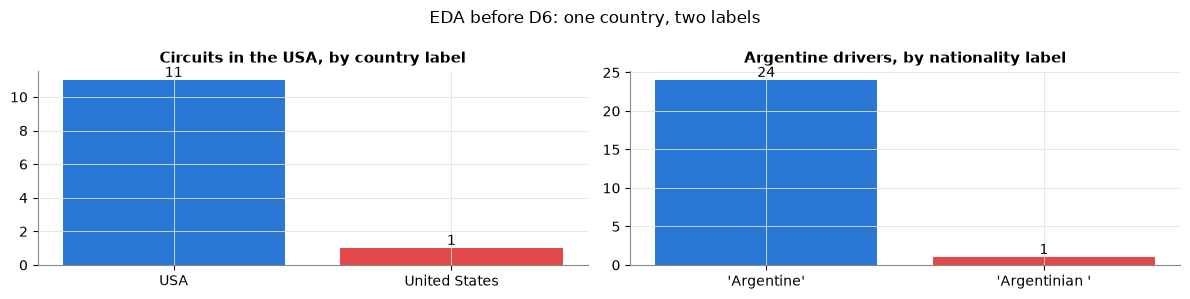

In [25]:
# EDA before D6: the labels written in two ways (red = the odd label)
us_labels = tables["circuits"]["country"].value_counts().reindex(["USA", "United States"])
ar_labels = tables["drivers"]["nationality"].value_counts().reindex(["Argentine", "Argentinian "])
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].bar(us_labels.index, us_labels.values, color=[PALETTE[0], PALETTE[7]])
axes[0].set_title("Circuits in the USA, by country label")
axes[1].bar([repr(label) for label in ar_labels.index], ar_labels.values, color=[PALETTE[0], PALETTE[7]])
axes[1].set_title("Argentine drivers, by nationality label")
for ax, values in [(axes[0], us_labels.values), (axes[1], ar_labels.values)]:
    for i, v in enumerate(values):
        ax.text(i, v, str(v), ha="center", va="bottom")
fig.suptitle("EDA before D6: one country, two labels")
fig.tight_layout()
savefig(fig, "p3_d6_before")
plt.show()

**Before:** Las Vegas Strip is `United States` (all other US circuits `USA`), Colapinto is `'Argentinian '`, and
one team name contains `&amp;`.

**Rule:** map each odd label to the existing one, in cleaned copies of `circuits`, `drivers` and `constructors` (no
results row changes). Needed for the home-race check in Q2.

In [26]:
# D6: strip spaces and HTML codes in the label tables, then map the two odd labels to the existing ones
circuits_clean, drivers_clean, constructors_clean = (tables[n].copy() for n in ["circuits", "drivers", "constructors"])
country_before = circuits_clean["country"].value_counts()
nationality_before = drivers_clean["nationality"].value_counts()

for df in (circuits_clean, drivers_clean, constructors_clean):
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].map(lambda v: html.unescape(v).strip() if isinstance(v, str) else v)
circuits_clean["country"] = circuits_clean["country"].replace({"United States": "USA"})
drivers_clean["nationality"] = drivers_clean["nationality"].replace({"Argentinian": "Argentine"})
clean["team"] = clean["constructorId"].map(constructors_clean.set_index("constructorId")["name"])
log_step("D6 labels (no rows removed)")

D6 labels (no rows removed): 26,759 rows (0 removed)


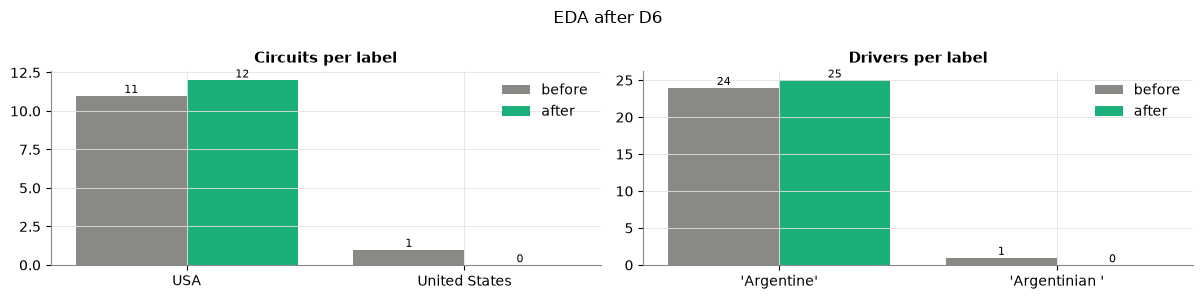

distinct circuit countries: 35 -> 34 | distinct driver nationalities: 43 -> 42 | team names with an HTML code left: 0


In [27]:
# EDA after D6: the same labels before and after
us, ar = ["USA", "United States"], ["Argentine", "Argentinian "]
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
before_after_bars(axes[0], us, country_before.reindex(us, fill_value=0).values,
                  circuits_clean["country"].value_counts().reindex(us, fill_value=0).values, "Circuits per label")
before_after_bars(axes[1], [repr(label) for label in ar], nationality_before.reindex(ar, fill_value=0).values,
                  drivers_clean["nationality"].value_counts().reindex(ar, fill_value=0).values, "Drivers per label")
fig.suptitle("EDA after D6")
fig.tight_layout()
savefig(fig, "p3_d6_after")
plt.show()
print("distinct circuit countries:", country_before.size, "->", circuits_clean["country"].nunique(),
      "| distinct driver nationalities:", nationality_before.size, "->", drivers_clean["nationality"].nunique(),
      "| team names with an HTML code left:", int(constructors_clean["name"].str.contains("&amp;").sum()))

**After:** `USA` covers all 12 US circuits and `Argentine` all 25 Argentine drivers; no extra spaces or HTML codes
left.

### 3.2 Remove the Indianapolis 500

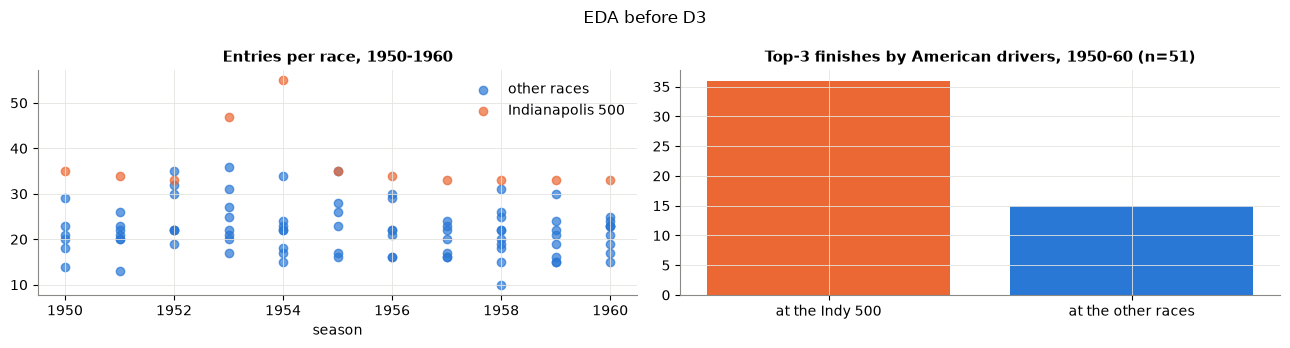

In [28]:
# EDA before D3: entries per race in 1950-60, and where American drivers' top-3 finishes came from
def early_view(df):
    e = df[df["year"] <= 1960].merge(drivers_clean[["driverId", "nationality"]], on="driverId")
    return e.assign(is_indy500=e["name"].eq("Indianapolis 500"))


early_before = early_view(clean)
entries = early_before.groupby(["raceId", "year", "is_indy500"]).size().rename("entries").reset_index()
us_top3_before = early_before[early_before["nationality"].eq("American") & (early_before["positionOrder"] <= 3)]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for is_indy, color, label in [(False, PALETTE[0], "other races"), (True, PALETTE[1], "Indianapolis 500")]:
    part = entries[entries["is_indy500"] == is_indy]
    axes[0].scatter(part["year"], part["entries"], color=color, label=label, alpha=0.7)
axes[0].set_title("Entries per race, 1950-1960")
axes[0].set_xlabel("season")
axes[0].legend()
axes[1].bar(["at the Indy 500", "at the other races"],
            [int(us_top3_before["is_indy500"].sum()), int((~us_top3_before["is_indy500"]).sum())], color=[PALETTE[1], PALETTE[0]])
axes[1].set_title(f"Top-3 finishes by American drivers, 1950-60 (n={len(us_top3_before)})")
fig.suptitle("EDA before D3")
fig.tight_layout()
savefig(fig, "p3_d3_before")
plt.show()

**Before:** the Indy 500 had far bigger fields, and most American top-3 finishes of 1950–60 came from it (2.4).

**Rule:** remove the races named exactly `Indianapolis 500` (the 2000–07 US GPs at the same circuit stay). It was a
separate competition; kept in, it would fake a home advantage in Q2.

In [29]:
# D3: remove the races named exactly "Indianapolis 500"
before_step = clean.copy()
is_indy = clean["name"].eq("Indianapolis 500")
print(f"Indianapolis 500: {clean.loc[is_indy, 'raceId'].nunique()} races, {is_indy.sum()} rows")
clean = clean[~is_indy]
assert clean["name"].str.contains("United States Grand Prix").any() and clean["name"].eq("Indian Grand Prix").any()
log_step("D3 remove Indy 500")

Indianapolis 500: 11 races, 405 rows
D3 remove Indy 500: 26,354 rows (405 removed)


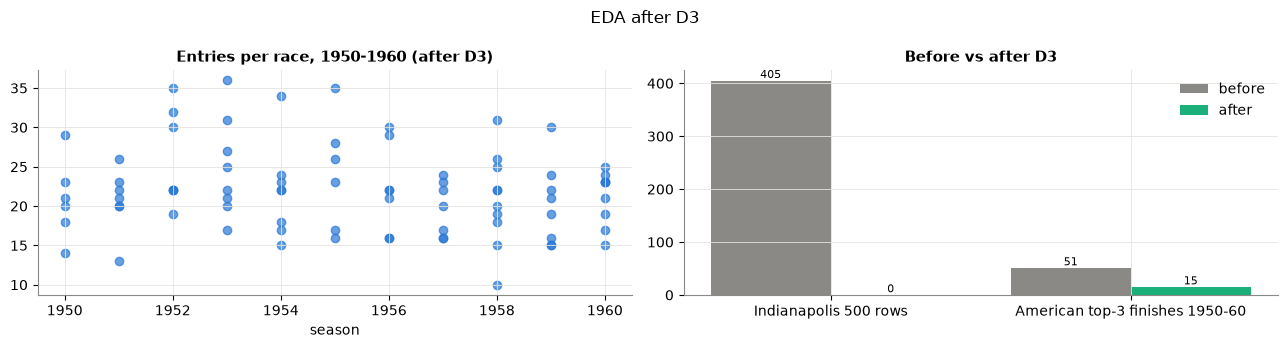

non-starters still in the table: 1717


In [30]:
# EDA after D3: entries per race in 1950-60 and American top-3 finishes, after the removal
early_after = early_view(clean)
entries_after = early_after.groupby(["raceId", "year"]).size().rename("entries").reset_index()
us_top3_after = early_after[early_after["nationality"].eq("American") & (early_after["positionOrder"] <= 3)]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].scatter(entries_after["year"], entries_after["entries"], color=PALETTE[0], alpha=0.7)
axes[0].set_title("Entries per race, 1950-1960 (after D3)")
axes[0].set_xlabel("season")
before_after_bars(axes[1], ["Indianapolis 500 rows", "American top-3 finishes 1950-60"],
                  [int(before_step["name"].eq("Indianapolis 500").sum()), len(us_top3_before)],
                  [int(clean["name"].eq("Indianapolis 500").sum()), len(us_top3_after)], "Before vs after D3")
fig.suptitle("EDA after D3")
fig.tight_layout()
savefig(fig, "p3_d3_after")
plt.show()
print("non-starters still in the table:", int(is_non_starter(clean).sum()))

**After:** the 1950–60 races average ~22 entries; American top-3 finishes fall to the regular Grands Prix.

### 3.3 Remove every driver who did not start

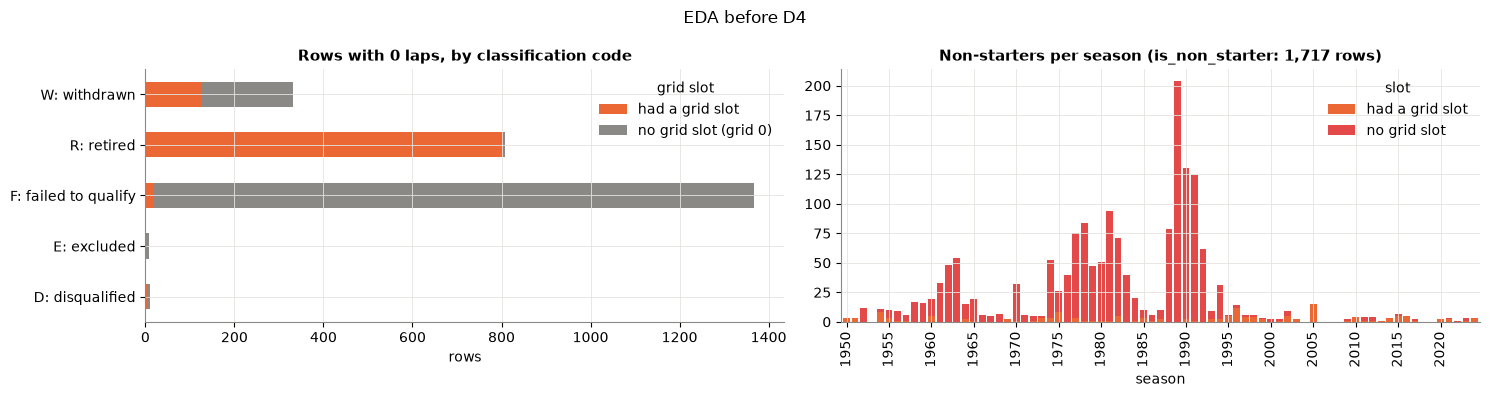

In [31]:
# EDA before D4: rows with 0 laps by classification code, and the non-starters per season
non_starter_now = is_non_starter(clean)
zero = clean[clean["laps"] == 0].copy()
zero["classification"] = zero["positionText"].map(code_names).fillna("finished")
zero["grid slot"] = np.where(zero["grid"] > 0, "had a grid slot", "no grid slot (grid 0)")
zero_by_code_now = zero.groupby(["classification", "grid slot"]).size().unstack(fill_value=0)
ns_per_season = (clean[non_starter_now].assign(slot=lambda d: np.where(d["grid"] > 0, "had a grid slot", "no grid slot"))
                 .groupby(["year", "slot"]).size().unstack(fill_value=0).reindex(range(1950, 2025), fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
zero_by_code_now.plot(kind="barh", stacked=True, ax=axes[0], color=[PALETTE[1], GREY])
axes[0].set_title("Rows with 0 laps, by classification code")
axes[0].set_xlabel("rows")
axes[0].set_ylabel("")
ns_per_season.plot(kind="bar", stacked=True, ax=axes[1], color=[PALETTE[1], PALETTE[7]], width=0.8)
axes[1].set_title(f"Non-starters per season (is_non_starter: {non_starter_now.sum():,} rows)")
axes[1].set_xticks(range(0, 75, 5))
axes[1].set_xticklabels(range(1950, 2025, 5))
axes[1].set_xlabel("season")
fig.suptitle("EDA before D4")
fig.tight_layout()
savefig(fig, "p3_d4_before")
plt.show()

**Before:** non-starters peak in the 1970s–90s and some had a grid slot (orange). Most R rows with 0 laps are
first-lap crashes, so `laps == 0` alone is wrong.

**Rule:** `is_non_starter` (the four conditions of 2.5) on classification code, grid, laps and status. The grid slots
of non-starters stay empty.

In [32]:
# D4: remove every row where is_non_starter is true
before_step = clean.copy()
non_starter_rows = is_non_starter(clean)
print(f"non-starters removed: {non_starter_rows.sum():,} rows (top-3 finishes among them: "
      f"{(clean.loc[non_starter_rows, 'positionOrder'] <= 3).sum()})")
clean = clean[~non_starter_rows]
log_step("D4 remove non-starters")

non-starters removed: 1,717 rows (top-3 finishes among them: 0)
D4 remove non-starters: 24,637 rows (1,717 removed)


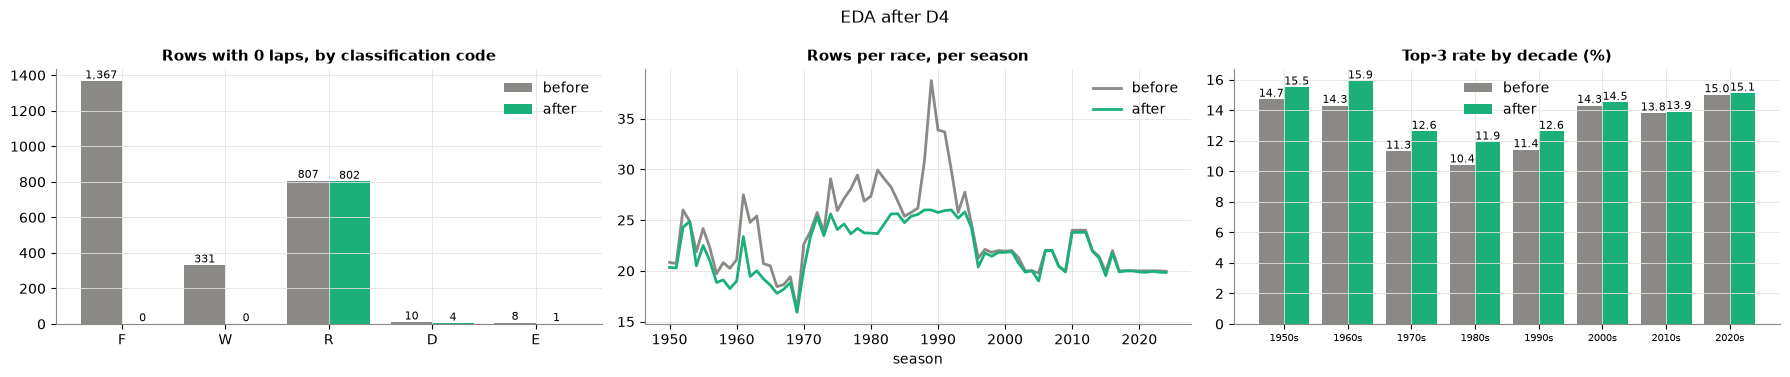

,race,driver,why,still in the table after D4
0,1989 Australian Grand Prix,Prost,took the start (R),True
1,1982 Canadian Grand Prix,Jarier,took the start (R),True
2,1977 Spanish Grand Prix,Lauda,"health reason, could not start",False
3,2021 Monaco Grand Prix,Leclerc,"pole slot, did not start",False


rows with grid 0 left: 72 | of them with laps > 0 (pit-lane starters): 72


In [33]:
# EDA after D4: 0-lap rows by code, rows per race per season, and the top-3 rate by decade, before and after
codes = ["F", "W", "R", "D", "E"]
season_before = before_step.groupby("year").size() / before_step.groupby("year")["raceId"].nunique()
season_after = clean.groupby("year").size() / clean.groupby("year")["raceId"].nunique()
rate_before = (before_step["positionOrder"] <= 3).groupby(before_step["year"] // 10 * 10).mean()
rate_after = (clean["positionOrder"] <= 3).groupby(clean["year"] // 10 * 10).mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
before_after_bars(axes[0], codes,
                  before_step.loc[before_step["laps"] == 0, "positionText"].value_counts().reindex(codes, fill_value=0).values,
                  clean.loc[clean["laps"] == 0, "positionText"].value_counts().reindex(codes, fill_value=0).values,
                  "Rows with 0 laps, by classification code")
axes[1].plot(season_before.index, season_before.values, color=GREY, label="before")
axes[1].plot(season_after.index, season_after.values, color=PALETTE[2], label="after")
axes[1].set_title("Rows per race, per season")
axes[1].set_xlabel("season")
axes[1].legend()
before_after_bars(axes[2], [f"{d}s" for d in rate_before.index], (rate_before * 100).round(1).values,
                  (rate_after * 100).round(1).values, "Top-3 rate by decade (%)")
axes[2].tick_params(axis="x", labelsize=7)
fig.suptitle("EDA after D4")
fig.tight_layout()
savefig(fig, "p3_d4_after")
plt.show()

edge_cases = [(1989, "Australian Grand Prix", "Prost", "took the start (R)"),
              (1982, "Canadian Grand Prix", "Jarier", "took the start (R)"),
              (1977, "Spanish Grand Prix", "Lauda", "health reason, could not start"),
              (2021, "Monaco Grand Prix", "Leclerc", "pole slot, did not start")]
display(pd.DataFrame([{"race": f"{y} {n}", "driver": s, "why": why,
                       "still in the table after D4": bool(((clean["year"] == y) & (clean["name"] == n) & (clean["surname"] == s)).any())}
                      for y, n, s, why in edge_cases]))
print("rows with grid 0 left:", int((clean["grid"] == 0).sum()), "| of them with laps > 0 (pit-lane starters):",
      int(((clean["grid"] == 0) & (clean["laps"] > 0)).sum()))

**After:** no F or W row with 0 laps left; rows per race follow the real starting fields (1980s–90s peaks of ~39
drop to ~26); the top-3 rate rises where non-starters had pulled it down. Prost and Jarier stay; Lauda and Leclerc
are removed.

### 3.4 Pit-lane starters go to the back of the grid

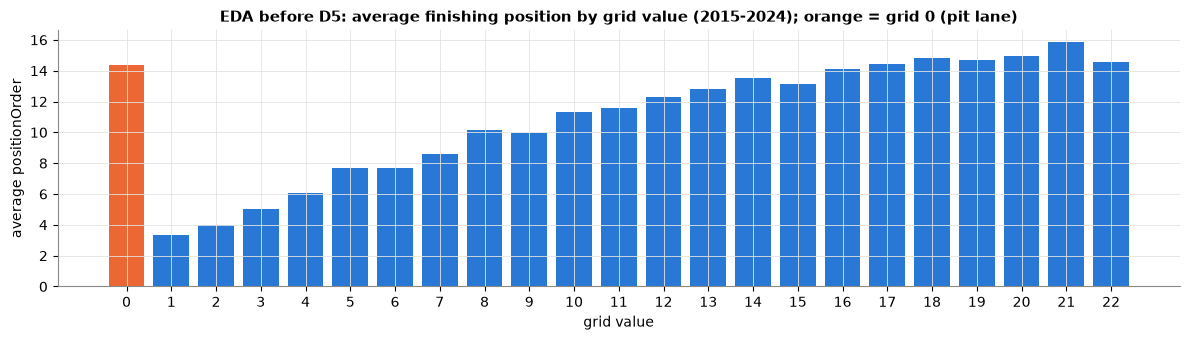

grid 0 rows: 72 | their average finish: 14.4 | pole: 3.3


In [34]:
# EDA before D5: average finish by grid value (2015-2024), grid 0 = pit-lane start
recent = clean[clean["year"] >= 2015]
avg_by_grid = recent.groupby("grid")["positionOrder"].mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(avg_by_grid.index.astype(str), avg_by_grid.values, color=[PALETTE[1] if g == 0 else PALETTE[0] for g in avg_by_grid.index])
ax.set_title("EDA before D5: average finishing position by grid value (2015-2024); orange = grid 0 (pit lane)")
ax.set_xlabel("grid value")
ax.set_ylabel("average positionOrder")
fig.tight_layout()
savefig(fig, "p3_d5_before")
plt.show()
print(f"grid 0 rows: {(clean['grid'] == 0).sum()} | their average finish: {avg_by_grid.loc[0]:.1f} | pole: {avg_by_grid.loc[1]:.1f}")

**Before:** `grid = 0` sits in front of pole, but these drivers finish ~P14, like the back of the grid (2.6).

**Rule:** `grid = last grid slot of that race + 1`, plus a `pitlane_start` flag.

In [35]:
# D5: grid = last grid slot of the race + 1 for pit-lane starters, plus a flag
before_step = clean.copy()
clean["pitlane_start"] = ((clean["grid"] == 0) & (clean["laps"] > 0)).astype(int)
last_slot = clean.groupby("raceId")["grid"].transform("max")
clean["grid"] = np.where(clean["pitlane_start"] == 1, last_slot + 1, clean["grid"])
assert (clean["grid"] > 0).all(), "grid 0 left after D5"
print("pit-lane starters recoded:", int(clean["pitlane_start"].sum()))
log_step("D5 pit-lane recode (no rows removed)")

pit-lane starters recoded: 72
D5 pit-lane recode (no rows removed): 24,637 rows (0 removed)


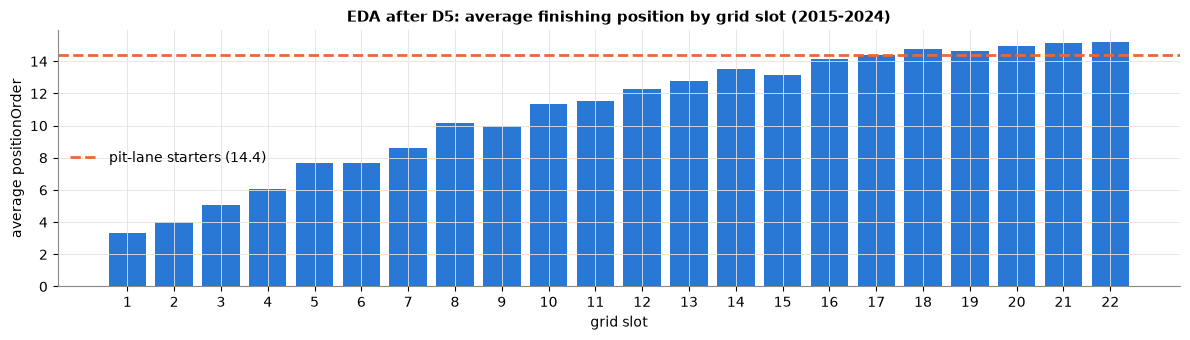

,surname,grid before D5,grid after D5,pitlane_start
12,Ericsson,17,17,0
16,Stevens,18,18,0
15,Merhi,19,19,0
9,Sainz,0,20,1


still a problem: 61 drivers with several rows, 74 finishing places with several rows


In [36]:
# EDA after D5: average finish by grid slot (2015-2024) and one example race
recent_after = clean[clean["year"] >= 2015]
avg_finish = recent_after.groupby("grid")["positionOrder"].mean()
pit_avg = recent_after.loc[recent_after["pitlane_start"] == 1, "positionOrder"].mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(avg_finish.index.astype(str), avg_finish.values, color=PALETTE[0])
ax.axhline(pit_avg, color=PALETTE[1], linestyle="--", label=f"pit-lane starters ({pit_avg:.1f})")
ax.set_title("EDA after D5: average finishing position by grid slot (2015-2024)")
ax.set_xlabel("grid slot")
ax.set_ylabel("average positionOrder")
ax.legend()
fig.tight_layout()
savefig(fig, "p3_d5_after")
plt.show()

example_race = clean.loc[clean["pitlane_start"] == 1, "raceId"].iloc[0]
compare_grid = (before_step.loc[before_step["raceId"] == example_race, ["surname", "grid"]]
                .merge(clean.loc[clean["raceId"] == example_race, ["surname", "grid", "pitlane_start"]],
                       on="surname", suffixes=(" before D5", " after D5")))
display(compare_grid.sort_values("grid after D5").tail(4))
drivers_several, places_several = shared_drive_counts(clean)
print(f"still a problem: {drivers_several} drivers with several rows, {places_several} finishing places with several rows")

**After:** no `grid = 0` left; pit-lane starters sit behind the last car, where their average result (dashed line)
says they belong.

### 3.5 One row per driver: keep the car he started

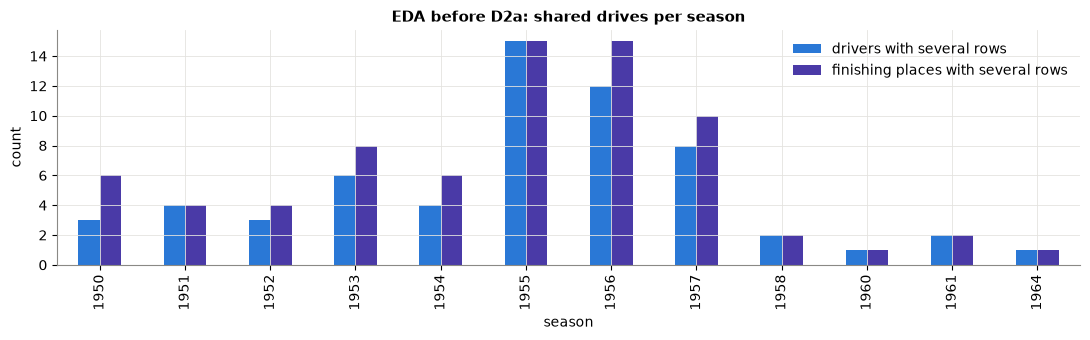

totals: {'drivers with several rows': 61, 'finishing places with several rows': 74}


In [37]:
# EDA before D2a: drivers with several rows and finishing places with several rows, per season
driver_dup_rows = clean[clean.duplicated(["raceId", "driverId"], keep=False)]
place_dup_rows = clean[clean.duplicated(["raceId", "positionOrder"], keep=False)]
shared_per_season = pd.DataFrame({
    "drivers with several rows": driver_dup_rows.drop_duplicates(["raceId", "driverId"]).groupby("year").size(),
    "finishing places with several rows": place_dup_rows.drop_duplicates(["raceId", "positionOrder"]).groupby("year").size(),
}).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 3.5))
shared_per_season.plot(kind="bar", ax=ax, color=[PALETTE[0], PALETTE[6]])
ax.set_title("EDA before D2a: shared drives per season")
ax.set_xlabel("season")
ax.set_ylabel("count")
fig.tight_layout()
savefig(fig, "p3_d2a_before")
plt.show()
print("totals:", shared_per_season.sum().to_dict())

**Before:** drivers and finishing places with several rows remain, all in 1950–64.

**Rule:** one row per car, credited to the driver who started it (rules of 2.7, 9/9 correct), so that grid and
result describe the same car. Done in three steps (3.5–3.7). Rejected alternatives: best position (mixes two cars),
first row in the file (wrong in 3 of 9 cases), delete all (loses real starters), merge (invents a row).

In [38]:
# D2a: mark the starter of every car (rules of 2.7) and drop the rows of cars a driver did not start
before_step = clean.copy()
clean = find_starters(clean)
rows_of_driver = clean.groupby(["raceId", "driverId"])["resultId"].transform("size")
cars_started = clean.groupby(["raceId", "driverId"])["started_car"].transform("sum")
relief_rows = (rows_of_driver > 1) & (cars_started == 1) & ~clean["started_car"]
print(f"D2a removes {relief_rows.sum()} rows of cars the driver did not start "
      f"({(clean.loc[relief_rows, 'positionOrder'] <= 3).sum()} of them top-3 places)")
display(clean[(clean["year"] == 1956) & (clean["name"] == "Argentine Grand Prix") & (clean["surname"] == "Fangio")]
        [SHOW + ["started_car", "decided_by"]])
clean = clean[~relief_rows]
log_step("D2a keep the car the driver started")

D2a removes 63 rows of cars the driver did not start (18 of them top-3 places)


,year,name,surname,team,number,grid,laps,positionText,positionOrder,status,started_car,decided_by
18894,1956,Argentine Grand Prix,Fangio,Ferrari,30,1,22,R,13,Fuel pump,True,rule 1: alone in the car
20266,1956,Argentine Grand Prix,Fangio,Ferrari,34,3,98,1,1,Finished,False,


D2a keep the car the driver started: 24,574 rows (63 removed)


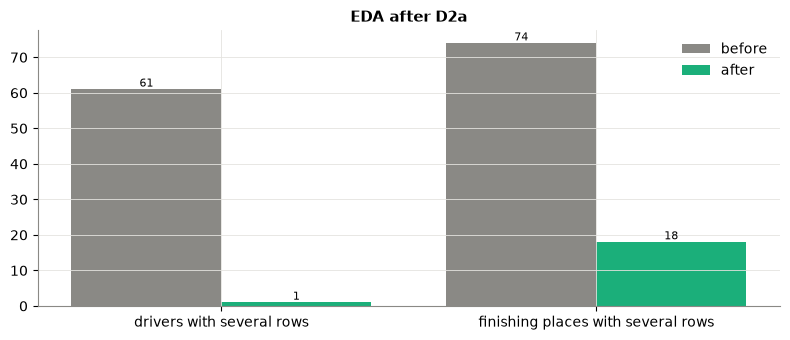

,year,name,surname,team,number,grid,laps,positionText,positionOrder,status,started_car
20033,1950,British Grand Prix,Shawe Taylor,Maserati,10,20,64,10,10,+6 Laps,True
20176,1950,British Grand Prix,Fry,Maserati,10,20,64,10,10,+6 Laps,False
20043,1950,British Grand Prix,Walker,ERA,9,10,5,R,20,Gearbox,True
20177,1950,British Grand Prix,Rolt,ERA,9,10,5,R,20,Gearbox,False
20135,1950,French Grand Prix,Étancelin,Talbot-Lago,16,4,59,5,5,+5 Laps,True
20180,1950,French Grand Prix,Chaboud,Talbot-Lago,16,4,59,5,5,+5 Laps,False


In [39]:
# EDA after D2a: shared drives before and after, and the finishing places that still have several rows
fig, ax = plt.subplots(figsize=(8, 3.5))
before_after_bars(ax, ["drivers with several rows", "finishing places with several rows"],
                  list(shared_drive_counts(before_step)), list(shared_drive_counts(clean)), "EDA after D2a")
fig.tight_layout()
savefig(fig, "p3_d2a_after")
plt.show()
car_size = clean.groupby(["raceId", "positionOrder"])["driverId"].transform("nunique")
clean[car_size > 1].sort_values(["year", "raceId", "positionOrder"])[SHOW + ["started_car"]].head(6)

**After:** every driver who started a car has one row (Fangio keeps his own car #30). Some places still have two
rows: the starter plus a relief driver with no car of his own → 3.6. One driver still has two rows → 3.7.

### 3.6 One row per finishing place: keep the driver who started the car

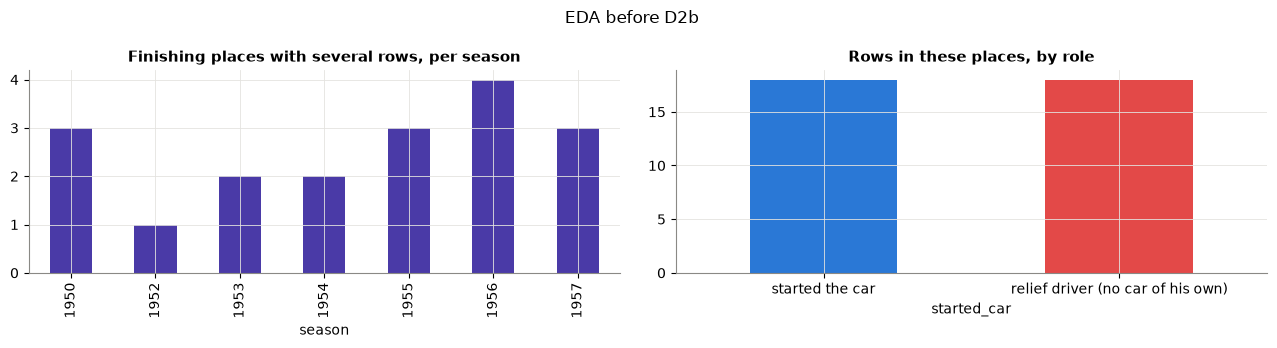

In [40]:
# EDA before D2b: the shared places per season, and the role of the drivers in them
car_size = clean.groupby(["raceId", "positionOrder"])["driverId"].transform("nunique")
in_shared_place = clean[car_size > 1]
roles = in_shared_place["started_car"].map({True: "started the car", False: "relief driver (no car of his own)"})
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
in_shared_place.drop_duplicates(["raceId", "positionOrder"]).groupby("year").size().plot(kind="bar", ax=axes[0], color=PALETTE[6])
axes[0].set_title("Finishing places with several rows, per season")
axes[0].set_xlabel("season")
roles.value_counts().plot(kind="bar", ax=axes[1], color=[PALETTE[0], PALETTE[7]], rot=0)
axes[1].set_title("Rows in these places, by role")
fig.suptitle("EDA before D2b")
fig.tight_layout()
savefig(fig, "p3_d2b_before")
plt.show()

**Before:** each remaining shared place holds the starter and one relief driver who never started a car of his own.

**Rule:** keep the starter; a relief driver without his own car did not start the race (same logic as 3.3).

In [41]:
# D2b: in every finishing place that still has several rows, keep only the driver who started the car
before_step = clean.copy()
car_size = clean.groupby(["raceId", "positionOrder"])["driverId"].transform("nunique")
relief_only = (car_size > 1) & ~clean["started_car"]
print(f"D2b removes {relief_only.sum()} rows of relief drivers ({(clean.loc[relief_only, 'positionOrder'] <= 3).sum()} of them top-3 places)")
clean = clean[~relief_only]
log_step("D2b keep the starter of each car")

D2b removes 18 rows of relief drivers (1 of them top-3 places)
D2b keep the starter of each car: 24,556 rows (18 removed)


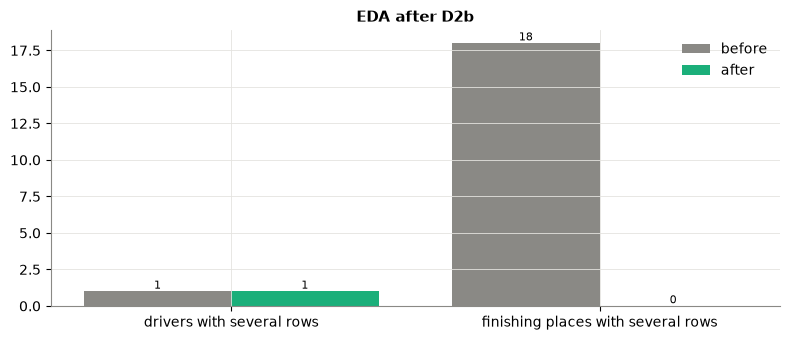

,year,name,surname,team,number,grid,laps,positionText,positionOrder,status,started_car,decided_by
18968,1956,French Grand Prix,da Silva Ramos,Gordini,32,14,57,8,8,+4 Laps,True,rule 1: alone in the car
18973,1956,French Grand Prix,da Silva Ramos,Maserati,8,16,40,R,13,Engine,True,rule 1: alone in the car


In [42]:
# EDA after D2b: shared drives before and after, and the driver who still has several rows
fig, ax = plt.subplots(figsize=(8, 3.5))
before_after_bars(ax, ["drivers with several rows", "finishing places with several rows"],
                  list(shared_drive_counts(before_step)), list(shared_drive_counts(clean)), "EDA after D2b")
fig.tight_layout()
savefig(fig, "p3_d2b_after")
plt.show()
clean[clean.duplicated(["raceId", "driverId"], keep=False)][SHOW + ["started_car", "decided_by"]]

**After:** every finishing place has one row. One driver still has two rows: da Silva Ramos, 1956 French GP,
credited with a Gordini (#32) and a Maserati (#8), alone in both cars.

### 3.7 Remove a driver credited to two teams in one race

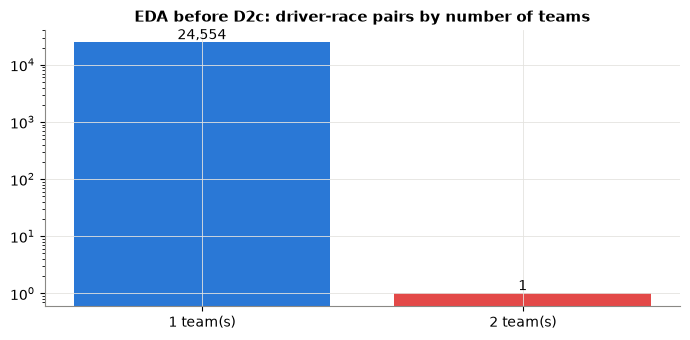

In [43]:
# EDA before D2c: driver-race pairs by number of teams (log scale: one pair vs ~24,500)
teams_per_driver = clean.groupby(["raceId", "driverId"])["team"].nunique().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([f"{n} team(s)" for n in teams_per_driver.index], teams_per_driver.values,
       color=[PALETTE[0] if n == 1 else PALETTE[7] for n in teams_per_driver.index])
for i, v in enumerate(teams_per_driver.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_yscale("log")
ax.set_title("EDA before D2c: driver-race pairs by number of teams")
fig.tight_layout()
savefig(fig, "p3_d2c_before")
plt.show()

**Before:** one driver–race pair has two teams (da Silva Ramos, 1956 French GP: Gordini P8, Maserati retired).

**Rule:** remove both rows: a driver cannot start for two teams, and nothing in the data says which car he started.

In [44]:
# D2c: remove the driver who is still credited to two teams in one race
before_step = clean.copy()
two_teams = clean.duplicated(["raceId", "driverId"], keep=False)
print(f"D2c removes {two_teams.sum()} rows")
clean = clean[~two_teams].drop(columns=["car_drivers", "started_car", "decided_by"])
log_step("D2c remove driver with two teams")

D2c removes 2 rows
D2c remove driver with two teams: 24,554 rows (2 removed)


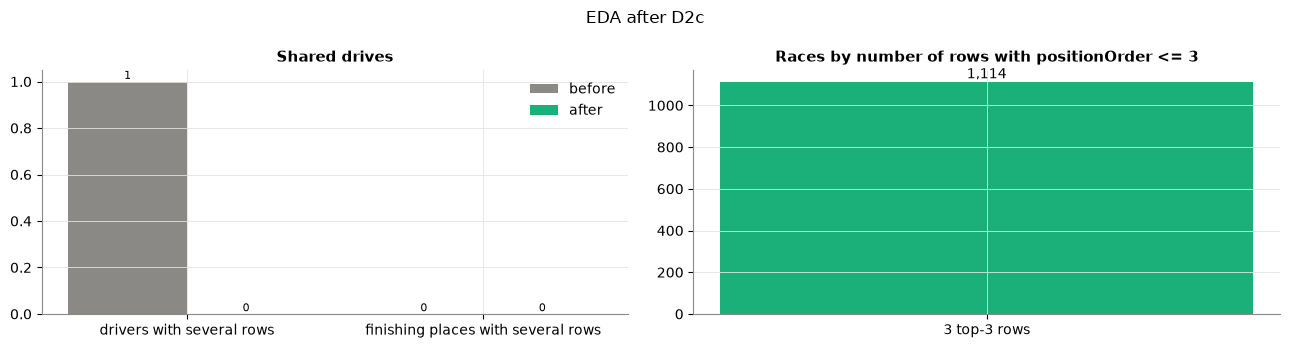

In [45]:
# EDA after D2c: the grain is fixed (one row per driver per race, one row per finishing place)
assert not clean.duplicated(["raceId", "driverId"]).any(), "driver with several rows in a race"
assert not clean.duplicated(["raceId", "positionOrder"]).any(), "finishing place with several rows"
top3_rows = (clean["positionOrder"] <= 3).groupby(clean["raceId"]).sum().value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
before_after_bars(axes[0], ["drivers with several rows", "finishing places with several rows"],
                  list(shared_drive_counts(before_step)), list(shared_drive_counts(clean)), "Shared drives")
axes[1].bar([f"{n} top-3 rows" for n in top3_rows.index], top3_rows.values, color=PALETTE[2])
axes[1].set_title("Races by number of rows with positionOrder <= 3")
for i, v in enumerate(top3_rows.values):
    axes[1].text(i, v, f"{v:,}", ha="center", va="bottom")
fig.suptitle("EDA after D2c")
fig.tight_layout()
savefig(fig, "p3_d2c_after")
plt.show()

**After:** one row per driver per race and one row per finishing place, so every race has exactly 3 rows with
`positionOrder <= 3`.

### 3.8 Renumber the finishing order

Finishing positions must be 1…N (N = number of starters), because `drv_avg_finish` and `team_avg_finish` average past
positions.

races whose finishing order is not 1..N: 3 of 1114


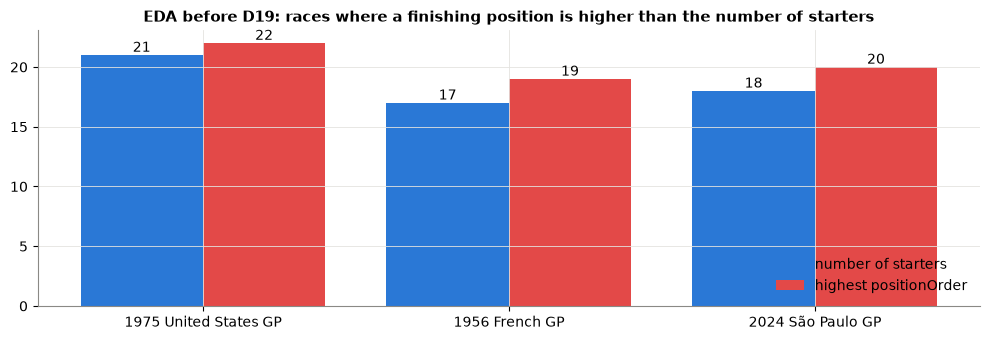

1975 United States Grand Prix: missing positions [15] -> held by ['Regazzoni'] (removed by cleaning)
1956 French Grand Prix: missing positions [8, 13] -> held by ['da Silva Ramos', 'da Silva Ramos'] (removed by cleaning)
2024 São Paulo Grand Prix: missing positions [18, 19] -> held by ['Albon', 'Stroll'] (removed by cleaning)


In [46]:
# EDA before D19: races whose last finishing position is larger than their number of starters
order_check = (clean.groupby(["raceId", "year", "name"])
               .agg(starters=("driverId", "size"), last_position=("positionOrder", "max")).reset_index())
gapped = order_check[order_check["last_position"] != order_check["starters"]]
print(f"races whose finishing order is not 1..N: {len(gapped)} of {len(order_check)}")
gap_labels = [f"{row.year} {row.name.replace(' Grand Prix', ' GP')}" for row in gapped.itertuples()]
x = np.arange(len(gapped))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(x - 0.2, gapped["starters"], width=0.4, color=PALETTE[0], label="number of starters")
ax.bar(x + 0.2, gapped["last_position"], width=0.4, color=PALETTE[7], label="highest positionOrder")
for i, (s, p) in enumerate(zip(gapped["starters"], gapped["last_position"])):
    ax.text(i - 0.2, s, str(s), ha="center", va="bottom")
    ax.text(i + 0.2, p, str(p), ha="center", va="bottom")
ax.set_xticks(x, gap_labels)
ax.set_title("EDA before D19: races where a finishing position is higher than the number of starters")
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "p3_d19_before")
plt.show()
for row in gapped.itertuples():
    present = set(clean.loc[clean["raceId"] == row.raceId, "positionOrder"])
    missing_pos = [p for p in range(1, row.last_position + 1) if p not in present]
    who = (tables["results"][(tables["results"]["raceId"] == row.raceId) & tables["results"]["positionOrder"].isin(missing_pos)]
           .merge(tables["drivers"][["driverId", "surname"]], on="driverId"))
    print(f"{row.year} {row.name}: missing positions {missing_pos} -> held by {list(who['surname'])} (removed by cleaning)")

**Before:** in 3 races a removed driver held a position in the middle of the order, leaving gaps (2024 São Paulo GP:
Hülkenberg ranked 20th although 18 cars started).

**Rule:** renumber 1…N inside each race, keeping the order. All gaps are after P3, so no podium changes (assert).

In [47]:
# D19: renumber positionOrder 1..N inside each race, keeping the order
before_step = clean.copy()
clean["positionOrder"] = clean.groupby("raceId")["positionOrder"].rank(method="first").astype(int)
changed = clean["positionOrder"] != before_step["positionOrder"]
print(f"rows renumbered: {changed.sum()} in {clean.loc[changed, 'raceId'].nunique()} races")
assert ((before_step["positionOrder"] <= 3) == (clean["positionOrder"] <= 3)).all(), "a podium changed"
log_step("D19 renumber finishing order (no rows removed)")

rows renumbered: 18 in 3 races
D19 renumber finishing order (no rows removed): 24,554 rows (0 removed)


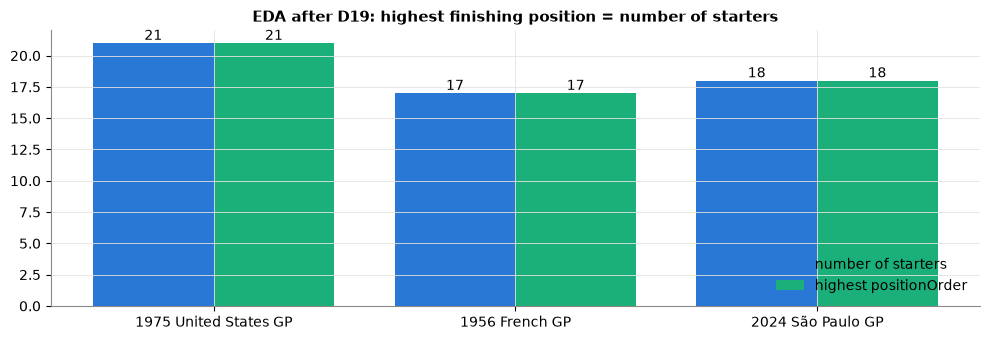

races whose finishing order is not 1..N: 0


In [48]:
# EDA after D19: the same races, now with highest finishing position = number of starters
order_after = (clean.groupby("raceId").agg(starters=("driverId", "size"), last_position=("positionOrder", "max"))
               .loc[gapped["raceId"]])
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(x - 0.2, order_after["starters"], width=0.4, color=PALETTE[0], label="number of starters")
ax.bar(x + 0.2, order_after["last_position"], width=0.4, color=PALETTE[2], label="highest positionOrder")
for i, (s, p) in enumerate(zip(order_after["starters"], order_after["last_position"])):
    ax.text(i - 0.2, s, str(s), ha="center", va="bottom")
    ax.text(i + 0.2, p, str(p), ha="center", va="bottom")
ax.set_xticks(x, gap_labels)
ax.set_title("EDA after D19: highest finishing position = number of starters")
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "p3_d19_after")
plt.show()
order_all = clean.groupby("raceId").agg(starters=("driverId", "size"), last_position=("positionOrder", "max"))
print("races whose finishing order is not 1..N:", int((order_all["last_position"] != order_all["starters"]).sum()))

**After:** every race has positions 1…N; no podium changed.

### 3.9 The target, final checks, row-count waterfall and the saved tables

**Target:** `podium = 1` if `positionOrder <= 3`, else 0. Defined once, here, and used unchanged in Phases 4–10.
Special case: at the 1983 Brazilian GP the officials left 2nd place empty after a disqualification; `positionOrder`
gives Laffite (officially 4th) the podium. The brief's definition is kept (3 podiums per race), noted as a limitation.

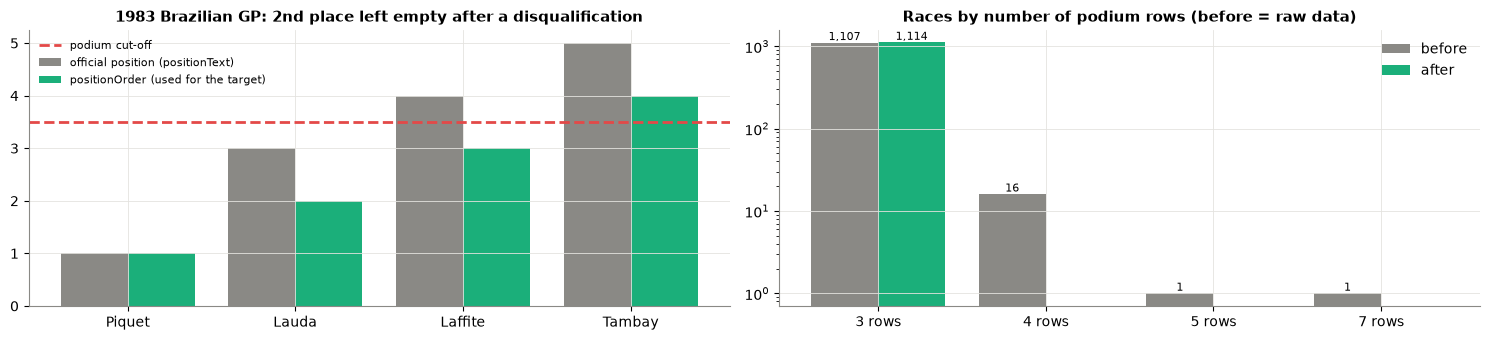

In [49]:
# the target, and the one race where the official result and positionOrder disagree on the podium
clean["podium"] = (clean["positionOrder"] <= 3).astype(int)

brazil_83 = clean[(clean["year"] == 1983) & (clean["name"] == "Brazilian Grand Prix")].sort_values("positionOrder").head(4)
xb = np.arange(len(brazil_83))
fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
axes[0].bar(xb - 0.2, brazil_83["positionText"].astype(int), width=0.4, color=GREY, label="official position (positionText)")
axes[0].bar(xb + 0.2, brazil_83["positionOrder"], width=0.4, color=PALETTE[2], label="positionOrder (used for the target)")
axes[0].axhline(3.5, color=PALETTE[7], linestyle="--", label="podium cut-off")
axes[0].set_xticks(xb, brazil_83["surname"])
axes[0].set_title("1983 Brazilian GP: 2nd place left empty after a disqualification")
axes[0].legend(fontsize=8, loc="upper left")
raw_top3 = eda.groupby("raceId")["top3"].sum().value_counts().sort_index()
clean_top3 = clean.groupby("raceId")["podium"].sum().value_counts().sort_index()
counts_ = sorted(set(raw_top3.index) | set(clean_top3.index))
before_after_bars(axes[1], [f"{n} rows" for n in counts_], raw_top3.reindex(counts_, fill_value=0).values,
                  clean_top3.reindex(counts_, fill_value=0).values, "Races by number of podium rows (before = raw data)")
axes[1].set_yscale("log")
fig.tight_layout()
savefig(fig, "p3_target")
plt.show()

all final checks passed: grain, 3 podiums per race, finishing order 1..N, foreign keys of base reconcile


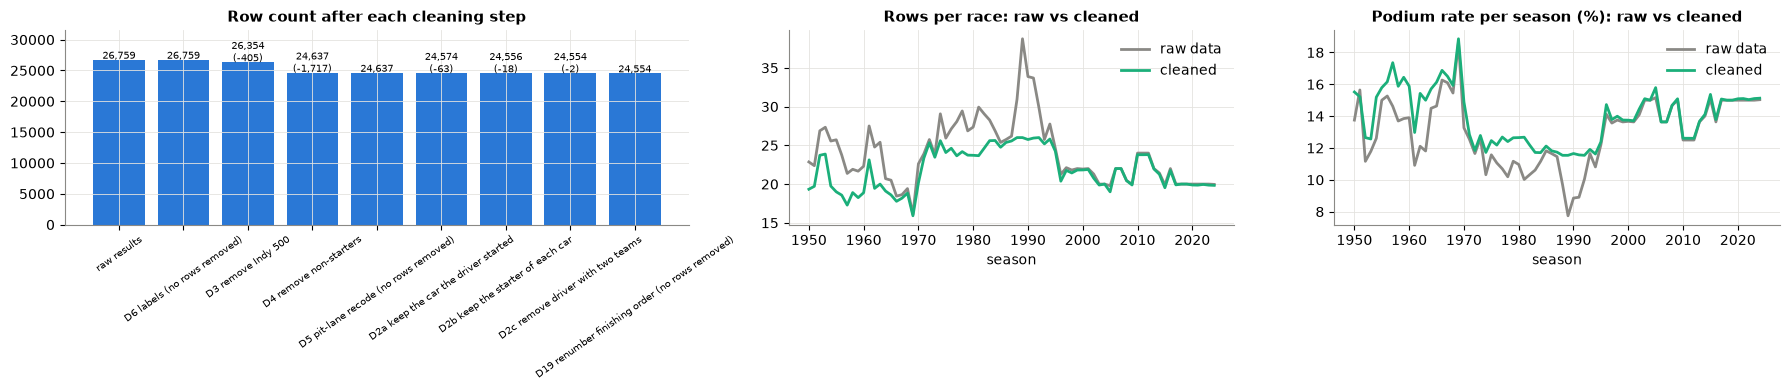

base: 24,554 rows x 28 columns | 1,114 races | podium rate 13.6% (raw 12.7%) | 2003-2024: 14.4%


,step,rows,removed
0,raw results,26759,0
1,D6 labels (no rows removed),26759,0
2,D3 remove Indy 500,26354,405
3,D4 remove non-starters,24637,1717
4,D5 pit-lane recode (no rows removed),24637,0
5,D2a keep the car the driver started,24574,63
6,D2b keep the starter of each car,24556,18
7,D2c remove driver with two teams,24554,2
8,D19 renumber finishing order (no rows removed),24554,0


In [50]:
# final checks: every decision must hold in the final table; then the row-count waterfall and raw vs clean per season
base = clean.reset_index(drop=True)
assert base["year"].between(1950, YEAR_MAX).all()
assert not base["name"].eq("Indianapolis 500").any()
assert not is_non_starter(base).any()
assert (base["grid"] > 0).all()
assert not base.duplicated(["raceId", "driverId"]).any()
assert not base.duplicated(["raceId", "positionOrder"]).any()
assert base.groupby("raceId")["podium"].sum().eq(3).all()
assert base.groupby("raceId")["positionOrder"].max().eq(base.groupby("raceId").size()).all()
keys_after = fk_audit({"results": base, "races": tables["races"], "drivers": drivers_clean,
                       "constructors": constructors_clean, "status": tables["status"]},
                      [("results", ["raceId"], "races", ["raceId"]), ("results", ["driverId"], "drivers", ["driverId"]),
                       ("results", ["constructorId"], "constructors", ["constructorId"]),
                       ("results", ["statusId"], "status", ["statusId"])])
assert keys_after["orphan rows"].sum() == 0
print("all final checks passed: grain, 3 podiums per race, finishing order 1..N, foreign keys of base reconcile")

waterfall = pd.DataFrame(row_log, columns=["step", "rows"])
waterfall["removed"] = (-waterfall["rows"].diff()).fillna(0).astype(int)
season_raw = eda.groupby("year").agg(rows=("raceId", "size"), races=("raceId", "nunique"), rate=("top3", "mean"))
season_clean = base.groupby("year").agg(rows=("raceId", "size"), races=("raceId", "nunique"), rate=("podium", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={"width_ratios": [1.4, 1, 1]})
axes[0].bar(waterfall["step"], waterfall["rows"], color=PALETTE[0])
for i, row in waterfall.iterrows():
    axes[0].text(i, row["rows"] + 150, f"{row['rows']:,}" + (f"\n(-{row['removed']:,})" if row["removed"] else ""),
                 ha="center", fontsize=7)
axes[0].set_ylim(0, waterfall["rows"].max() * 1.18)
axes[0].set_title("Row count after each cleaning step")
axes[0].tick_params(axis="x", rotation=35, labelsize=7)
for ax, col, title in [(axes[1], None, "Rows per race: raw vs cleaned"), (axes[2], "rate", "Podium rate per season (%): raw vs cleaned")]:
    for d, color, label in [(season_raw, GREY, "raw data"), (season_clean, PALETTE[2], "cleaned")]:
        values = d["rows"] / d["races"] if col is None else d[col] * 100
        ax.plot(d.index, values, color=color, label=label)
    ax.set_title(title)
    ax.set_xlabel("season")
    ax.legend()
fig.tight_layout()
savefig(fig, "p3_waterfall_and_effect")
plt.show()
print(f"base: {base.shape[0]:,} rows x {base.shape[1]} columns | {base['raceId'].nunique():,} races | "
      f"podium rate {base['podium'].mean():.1%} (raw {eda['top3'].mean():.1%}) | 2003-2024: {base.loc[base['year'] >= 2003, 'podium'].mean():.1%}")
waterfall

In [51]:
# save the cleaned table and the typed tables (with the cleaned label tables) for Phases 4-10
saved_tables = {**tables, "circuits": circuits_clean, "drivers": drivers_clean, "constructors": constructors_clean}
for name, df in saved_tables.items():
    df.to_csv(PROC_DIR / f"{name}.csv", index=False)
base.to_csv(PROC_DIR / "base.csv", index=False)
print("saved:", sorted(p.name for p in PROC_DIR.glob("*.csv")))

saved: ['base.csv', 'circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'model_table.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


**Hints.** All final checks pass: one row per starter, 3 podiums per race, positions 1…N, foreign keys reconcile.
24,554 rows in 1,114 races; podium rate 13.6% (raw 12.7%).

### 3.10 Known data issues left in `base` (documented, not changed)

**Grid ties:** two drivers with the same grid number in one race.

tie pairs by cause: {'source data': 74, 'pit-lane starters (D5, by design)': 15} | source-data ties since 2003: 4


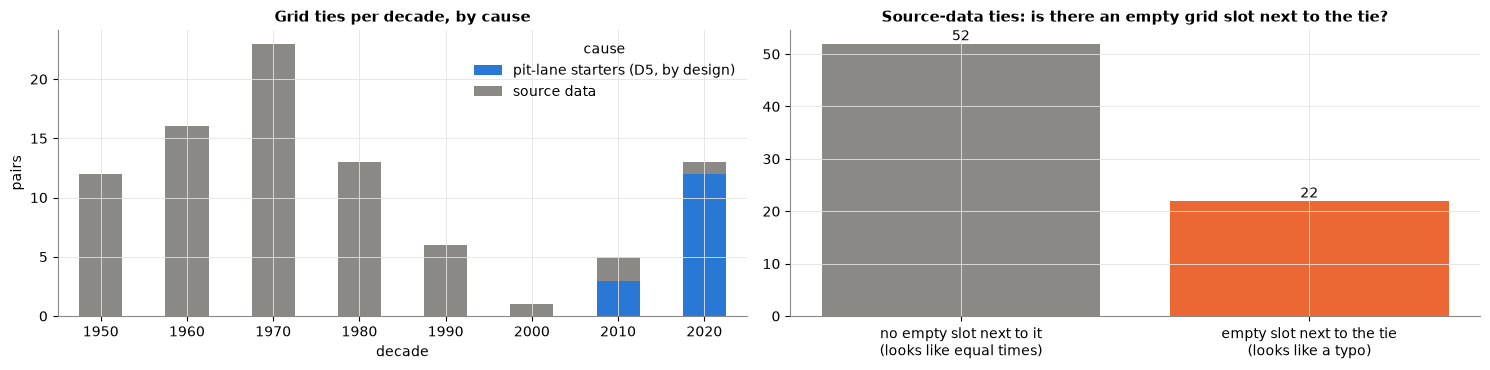

,year,race,grid,drivers
0,2003,German Grand Prix,13,"Villeneuve, Fisichella"
71,2015,Italian Grand Prix,17,"Sainz, Nasr"
72,2015,Russian Grand Prix,17,"Stevens, Ericsson"
88,2024,São Paulo Grand Prix,17,"Verstappen, Hülkenberg"


In [52]:
# every pair of drivers sharing a grid number in the same race, by cause, and whether an empty slot sits next to it
ties = base[base.duplicated(["raceId", "grid"], keep=False)]


def empty_slot_next_to(race, g):
    used = set(base.loc[base["raceId"] == race, "grid"])
    return (g - 1 >= 1 and g - 1 not in used) or (g + 1 not in used and g + 1 <= max(used))


tie_pairs = pd.DataFrame([{"raceId": race, "grid": g, "year": pair["year"].iloc[0], "race": pair["name"].iloc[0],
                           "drivers": ", ".join(pair["surname"]),
                           "cause": "pit-lane starters (D5, by design)" if pair["pitlane_start"].sum() > 0 else "source data",
                           "empty slot next to it": empty_slot_next_to(race, g)}
                          for (race, g), pair in ties.groupby(["raceId", "grid"])])
source_ties = tie_pairs[tie_pairs["cause"] == "source data"]
print("tie pairs by cause:", tie_pairs["cause"].value_counts().to_dict(),
      "| source-data ties since 2003:", int((source_ties["year"] >= 2003).sum()))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
(tie_pairs.assign(decade=tie_pairs["year"] // 10 * 10).groupby(["decade", "cause"]).size().unstack(fill_value=0)
 .plot(kind="bar", stacked=True, ax=axes[0], color=[PALETTE[0], GREY], rot=0))
axes[0].set_title("Grid ties per decade, by cause")
axes[0].set_ylabel("pairs")
slot_counts = source_ties["empty slot next to it"].map({True: "empty slot next to the tie\n(looks like a typo)",
                                                        False: "no empty slot next to it\n(looks like equal times)"}).value_counts()
axes[1].bar(slot_counts.index, slot_counts.values, color=[GREY, PALETTE[1]][:len(slot_counts)])
for i, v in enumerate(slot_counts.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")
axes[1].set_title("Source-data ties: is there an empty grid slot next to the tie?")
fig.tight_layout()
savefig(fig, "p3_grid_ties")
plt.show()
source_ties[source_ties["year"] >= 2003][["year", "race", "grid", "drivers"]]

**Hints.**
* Pit-lane starters share "last slot + 1" by design.
* 74 source-data pairs, mostly 1950–89; only 4 races since 2003 (2003 German, 2015 Italian, 2015 Russian, 2024 São
  Paulo GP).
* Kept as recorded: tiny effect and no reliable fix (no qualifying data before 1994; qualifying ≠ grid after
  penalties).

**Other documented issues:** an impossible lap count at the 1960 Dutch GP (`laps` is not a feature); a few 0-lap
"Retired" rows may be non-starters (2.5); the 1983 Brazilian GP target (3.9); shared cars decided by file order (2.7).

### Phase 3 summary

| Step | What changed | Rows removed / changed |
|---|---|---|
| 3.1 | labels normalised (`circuits_clean`, `drivers_clean`, `constructors_clean`) | 3 labels, 0 rows |
| 3.2 | Indianapolis 500 removed | 405 rows |
| 3.3 | non-starters removed | 1,717 rows |
| 3.4 | pit-lane starters → back of the grid + `pitlane_start` | 72 values, 0 rows |
| 3.5 | rows of cars a driver did not start | 63 rows |
| 3.6 | relief drivers without a car of their own | 18 rows |
| 3.7 | driver credited to two teams | 2 rows |
| 3.8 | finishing order renumbered 1…N | 18 values in 3 races, 0 rows |

`base`: 24,554 rows in 1,114 races, exactly 3 podiums per race.

## 4. Data-engineering questions

Each question uses **multi-hop joins** on `base` (one row per starter) and the cleaned lookup tables `circuits_clean`
and `drivers_clean`.

Per question: definitions (constants at the top) → join, checked to keep `len(base)` rows → EDA graphs → answer, with
a note on grain, missingness and the pre-race cutoff.

Rates are shown with a **95% Wilson interval**: a wide interval means few races, so differences should not be
over-read.

In [53]:
# helper: 95% Wilson interval for a rate (used by all three questions)
def wilson_interval(successes, n, z=1.96):
    # 95% interval for a rate successes / n (stays inside 0-1 and works for small n)
    successes, n = np.asarray(successes, dtype=float), np.asarray(n, dtype=float)
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

print('Example: 15 podiums in 20 starts ->', [round(float(v), 2) for v in wilson_interval(15, 20)],
      '| 150 in 200 ->', [round(float(v), 2) for v in wilson_interval(150, 200)])

Example: 15 podiums in 20 starts -> [0.53, 0.89] | 150 in 200 -> [0.69, 0.8]


### 4.1 Q1: Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Definitions**
- Front-row start = `grid` 1 or 2 (the starting grid, not qualifying; see 4.1.5).
- Conversion rate = share of front-row starts that end on the podium.
- Eras: before 2014 vs 2014+ (turbo-hybrid era).
- A circuit is ranked only with at least 10 front-row starts in **each** era.

**Join:** `base` (grid, podium) → `races` (circuitId) → `circuits_clean` (circuit name).

In [54]:
# Q1 definitions (D7) and the join base -> circuits_clean
FRONT_ROW_SLOTS = [1, 2]
ERA_SPLIT_YEAR = 2014
MIN_FRONT_ROW_STARTS = 10

q1 = base.merge(circuits_clean[['circuitId', 'name']].rename(columns={'name': 'circuit'}), on='circuitId', how='left')
assert len(q1) == len(base) and q1['circuit'].notna().all()
q1['era'] = np.where(q1['year'] >= ERA_SPLIT_YEAR, '2014+', 'before 2014')

front = q1[q1['grid'].isin(FRONT_ROW_SLOTS)]
print(f'Front-row starts: {len(front)} in {front["raceId"].nunique()} races | missing grid values: {q1["grid"].isna().sum()}')
print('Races by number of front-row starters:', front.groupby('raceId').size().value_counts().sort_index().to_dict())

Front-row starts: 2221 in 1113 races | missing grid values: 0
Races by number of front-row starters: {1: 8, 2: 1103, 3: 1, 4: 1}


#### 4.1.1 How often does the front row reach the podium, by era?

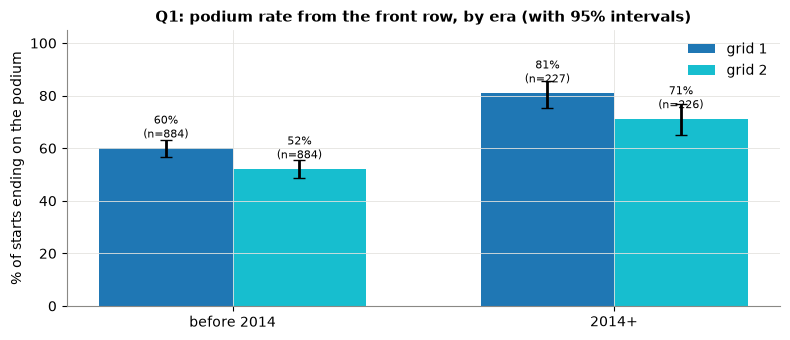

Front-row conversion: {'before 2014': '56.1%', '2014+': '76.2%'}


In [55]:
# Q1: podium rate from grid 1 and grid 2, by era, with 95% intervals
by_slot = front.groupby(['era', 'grid'])['podium'].agg(['sum', 'size'])
by_slot['rate'] = by_slot['sum'] / by_slot['size']
low, high = wilson_interval(by_slot['sum'], by_slot['size'])
by_slot['low'], by_slot['high'] = low, high

fig, ax = plt.subplots(figsize=(8, 3.5))
eras = ['before 2014', '2014+']
for i, slot in enumerate(FRONT_ROW_SLOTS):
    rows = by_slot.xs(slot, level='grid').reindex(eras)
    x = np.arange(len(eras)) + (i - 0.5) * 0.35
    ax.bar(x, rows['rate'] * 100, width=0.35, label=f'grid {slot}', color=['tab:blue', 'tab:cyan'][i],
           yerr=[(rows['rate'] - rows['low']) * 100, (rows['high'] - rows['rate']) * 100], capsize=4)
    for xi, (r, n) in zip(x, zip(rows['rate'], rows['size'])):
        ax.text(xi, r * 100 + 4, f'{r:.0%}\n(n={n})', ha='center', fontsize=8)
ax.set_xticks(np.arange(len(eras)))
ax.set_xticklabels(eras)
ax.set_ylim(0, 105)
ax.set_ylabel('% of starts ending on the podium')
ax.set_title('Q1: podium rate from the front row, by era (with 95% intervals)')
ax.legend()
plt.tight_layout()
savefig(fig, 'p4_q1_front_row_by_era')
plt.show()

overall = front.groupby('era')['podium'].mean()
print('Front-row conversion:', {era: f'{overall[era]:.1%}' for era in eras})

**Hints.** Front row → podium: 56% before 2014, 76% from 2014 (pole 60% → 81%, P2 52% → 71%); the intervals do
not overlap. In the hybrid era one or two dominant teams usually filled the front row.

#### 4.1.2 Which circuits have enough front-row starts in both eras?

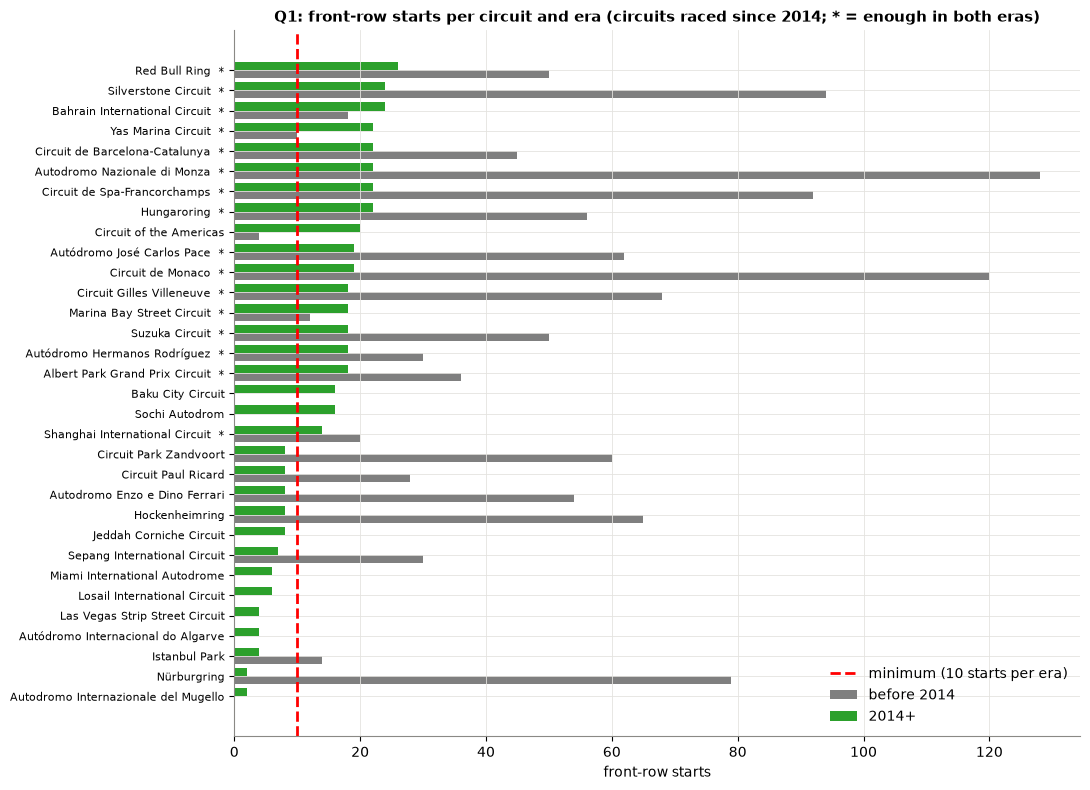

Circuits raced since 2014: 32 | eligible (>= 10 front-row starts in each era): 16


In [56]:
# Q1: front-row starts per circuit and era, and the circuits with enough starts in both eras
circuit_era = front.groupby(['circuit', 'era'])['podium'].agg(podiums='sum', starts='size').unstack('era')
starts = circuit_era['starts'].fillna(0).astype(int)
used_after_2014 = starts[starts['2014+'] > 0].sort_values('2014+')
eligible = starts[(starts['before 2014'] >= MIN_FRONT_ROW_STARTS) & (starts['2014+'] >= MIN_FRONT_ROW_STARTS)].index

fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(used_after_2014))
ax.barh(y - 0.2, used_after_2014['before 2014'], height=0.4, color='tab:gray', label='before 2014')
ax.barh(y + 0.2, used_after_2014['2014+'], height=0.4, color='tab:green', label='2014+')
ax.axvline(MIN_FRONT_ROW_STARTS, color='red', linestyle='--', label=f'minimum ({MIN_FRONT_ROW_STARTS} starts per era)')
ax.set_yticks(y)
ax.set_yticklabels([f'{c}  *' if c in eligible else c for c in used_after_2014.index], fontsize=8)
ax.set_xlabel('front-row starts')
ax.set_title('Q1: front-row starts per circuit and era (circuits raced since 2014; * = enough in both eras)')
ax.legend(loc='lower right')
plt.tight_layout()
savefig(fig, 'p4_q1_sample_size')
plt.show()
print(f'Circuits raced since 2014: {len(used_after_2014)} | eligible (>= {MIN_FRONT_ROW_STARTS} front-row starts in each era): {len(eligible)}')

**Hints.** 32 circuits raced since 2014; only **16** have at least 10 front-row starts in both eras (a rate from 3–4
starts is mostly luck).

#### 4.1.3 Conversion rate per circuit, before vs after 2014

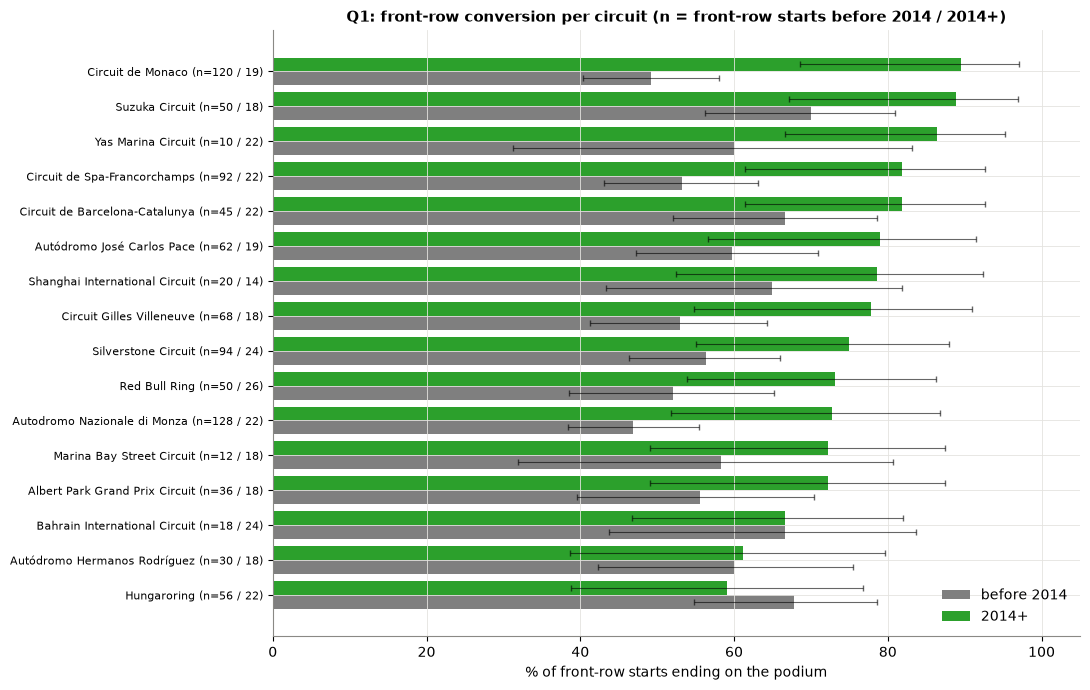

,rate before 2014,rank before 2014,rate 2014+,rank 2014+
circuit,,,,
Circuit de Monaco,0.492,15,0.895,1
Suzuka Circuit,0.700,1,0.889,2
Yas Marina Circuit,0.600,6,0.864,3
Circuit de Barcelona-Catalunya,0.667,3,0.818,4
Circuit de Spa-Francorchamps,0.533,12,0.818,4
Autódromo José Carlos Pace,0.597,8,0.789,6
Shanghai International Circuit,0.650,5,0.786,7
Circuit Gilles Villeneuve,0.529,13,0.778,8
Silverstone Circuit,0.564,10,0.750,9


In [57]:
# Q1: conversion rate per eligible circuit, before vs after 2014, and the two rankings
conv = circuit_era.loc[eligible].copy()
for era in eras:
    conv[('rate', era)] = conv[('podiums', era)] / conv[('starts', era)]
    conv[('low', era)], conv[('high', era)] = wilson_interval(conv[('podiums', era)], conv[('starts', era)])
conv = conv.sort_values(('rate', '2014+'))

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(conv))
for offset, era, color in [(-0.2, 'before 2014', 'tab:gray'), (0.2, '2014+', 'tab:green')]:
    rate = conv[('rate', era)]
    ax.barh(y + offset, rate * 100, height=0.4, color=color, label=era,
            xerr=[(rate - conv[('low', era)]) * 100, (conv[('high', era)] - rate) * 100], capsize=2,
            error_kw={'elinewidth': 0.8, 'alpha': 0.6})
ax.set_yticks(y)
ax.set_yticklabels([f"{c} (n={conv.loc[c, ('starts', 'before 2014')]:.0f} / {conv.loc[c, ('starts', '2014+')]:.0f})"
                    for c in conv.index], fontsize=8)
ax.set_xlabel('% of front-row starts ending on the podium')
ax.set_xlim(0, 105)
ax.set_title('Q1: front-row conversion per circuit (n = front-row starts before 2014 / 2014+)')
ax.legend(loc='lower right')
plt.tight_layout()
savefig(fig, 'p4_q1_conversion_by_circuit')
plt.show()

ranking = pd.DataFrame({
    'rate before 2014': conv[('rate', 'before 2014')].round(3),
    'rank before 2014': conv[('rate', 'before 2014')].rank(ascending=False, method='min').astype(int),
    'rate 2014+': conv[('rate', '2014+')].round(3),
    'rank 2014+': conv[('rate', '2014+')].rank(ascending=False, method='min').astype(int),
}).sort_values('rank 2014+')
display(ranking)

**Hints.**
- Before 2014: Suzuka 70%, Hungaroring 68%, Barcelona and Bahrain 67%; worst Monza 47%, Monaco 49%.
- 2014+: Monaco 90% (17 of 19), Suzuka 89%, Yas Marina 86%; worst Hungaroring 59%, Mexico City 61%.
- Almost every circuit converts better after 2014. Small 2014+ samples (14–26 starts) → wide, overlapping intervals.

#### 4.1.4 Does the ranking change? (rank before 2014 → rank 2014+)

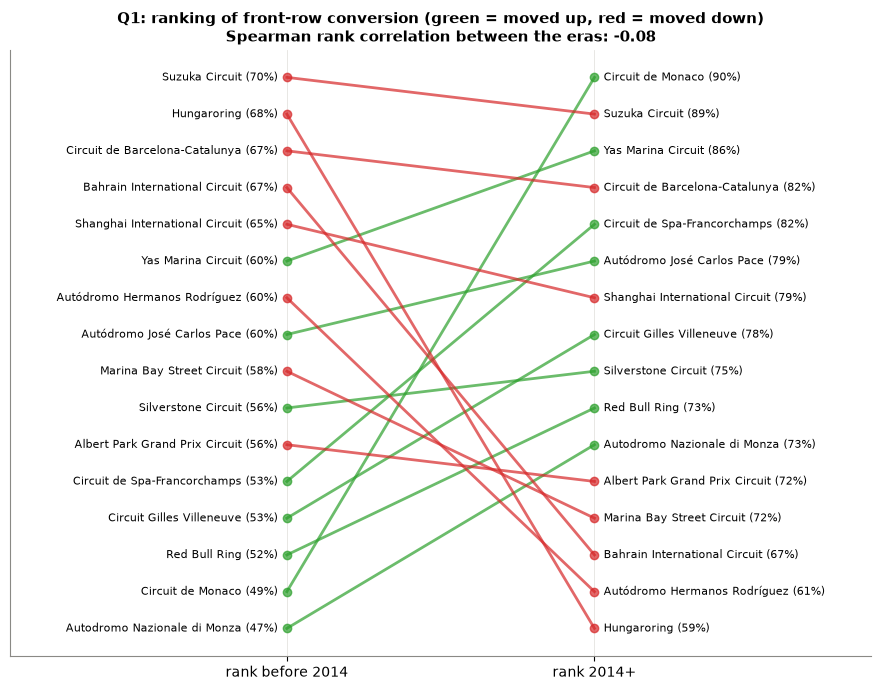

Spearman rank correlation: -0.08 (1 = same ranking, 0 = unrelated, -1 = reversed)


In [58]:
# Q1: how the ranking changes between the eras (slope chart + Spearman rank correlation)
rank_corr = ranking['rank before 2014'].corr(ranking['rank 2014+'], method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))
# tied ranks get neighbouring positions so that the labels do not overlap
position_before = ranking['rate before 2014'].rank(ascending=False, method='first')
position_after = ranking['rate 2014+'].rank(ascending=False, method='first')
for circuit, row in ranking.iterrows():
    moved_up = row['rank 2014+'] < row['rank before 2014']
    ax.plot([0, 1], [position_before[circuit], position_after[circuit]], marker='o',
            color='tab:green' if moved_up else 'tab:red', alpha=0.7)
    ax.text(-0.03, position_before[circuit], f"{circuit} ({row['rate before 2014']:.0%})", ha='right', va='center', fontsize=8)
    ax.text(1.03, position_after[circuit], f"{circuit} ({row['rate 2014+']:.0%})", ha='left', va='center', fontsize=8)
ax.set_xlim(-0.9, 1.9)
ax.invert_yaxis()
ax.set_xticks([0, 1])
ax.set_xticklabels(['rank before 2014', 'rank 2014+'])
ax.set_yticks([])
ax.set_title(f'Q1: ranking of front-row conversion (green = moved up, red = moved down)\n'
             f'Spearman rank correlation between the eras: {rank_corr:.2f}')
plt.tight_layout()
savefig(fig, 'p4_q1_rank_change')
plt.show()
print(f'Spearman rank correlation: {rank_corr:.2f} (1 = same ranking, 0 = unrelated, -1 = reversed)')

**Hints.** Rank correlation −0.08: the pre-2014 rank says nothing about the 2014+ rank. Monaco 15th → 1st, Spa
12th → 4th; Hungaroring 2nd → last, Bahrain 3rd → 14th. (A possible reason for Monaco, not proven here: no overtaking
plus reliable cars.)

#### 4.1.5 Grid vs qualifying: why the front row is defined by the grid

Grid penalties move drivers back after qualifying. For 2014+, compare the drivers who **qualified** on the front row
with those who **started** there.

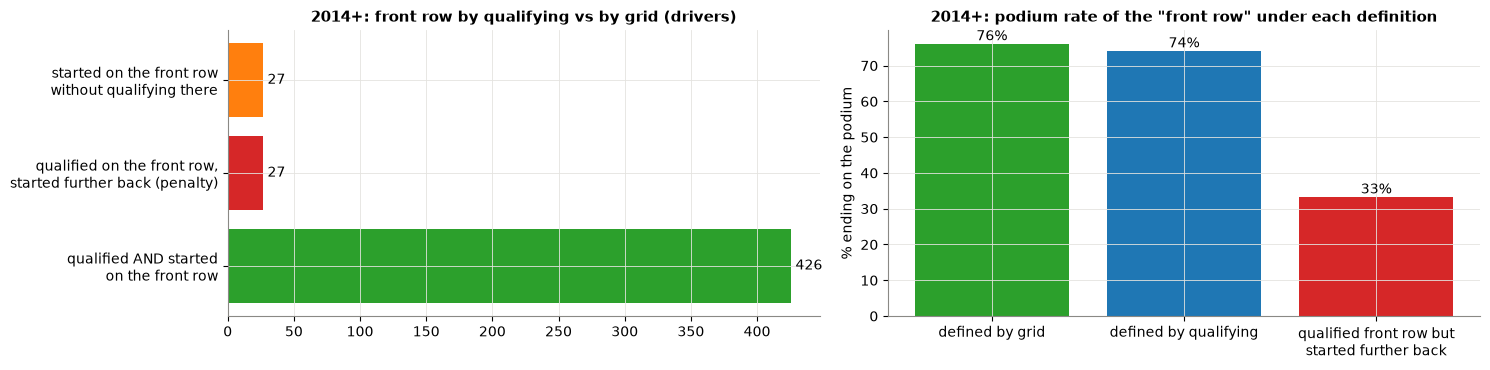

Podium rate: {'defined by grid': '76%', 'defined by qualifying': '74%', 'qualified front row but started further back': '33%'}
2014+: grid differs from qualifying position for 31% of all starters


In [59]:
# Q1: front row by qualifying vs by grid (2014+)
quali_pos = tables['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'})
q1_recent = q1[q1['year'] >= ERA_SPLIT_YEAR].merge(quali_pos, on=['raceId', 'driverId'], how='left')
assert len(q1_recent) == (q1['year'] >= ERA_SPLIT_YEAR).sum()

started_front = q1_recent['grid'].isin(FRONT_ROW_SLOTS)
qualified_front = q1_recent['quali_position'].isin(FRONT_ROW_SLOTS)
groups = pd.Series({
    'qualified AND started\non the front row': (started_front & qualified_front).sum(),
    'qualified on the front row,\nstarted further back (penalty)': (qualified_front & ~started_front).sum(),
    'started on the front row\nwithout qualifying there': (started_front & ~qualified_front).sum(),
})
front_row_rates = pd.Series({
    'defined by grid': q1_recent.loc[started_front, 'podium'].mean(),
    'defined by qualifying': q1_recent.loc[qualified_front, 'podium'].mean(),
    'qualified front row but\nstarted further back': q1_recent.loc[qualified_front & ~started_front, 'podium'].mean(),
})

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].barh(groups.index, groups.values, color=['tab:green', 'tab:red', 'tab:orange'])
for i, v in enumerate(groups.values):
    axes[0].text(v, i, f' {v}', va='center')
axes[0].set_title('2014+: front row by qualifying vs by grid (drivers)')
axes[1].bar(front_row_rates.index, front_row_rates.values * 100, color=['tab:green', 'tab:blue', 'tab:red'])
for i, v in enumerate(front_row_rates.values):
    axes[1].text(i, v * 100, f'{v:.0%}', ha='center', va='bottom')
axes[1].set_ylabel('% ending on the podium')
axes[1].set_title('2014+: podium rate of the "front row" under each definition')
plt.tight_layout()
savefig(fig, 'p4_q1_grid_vs_qualifying')
plt.show()
print('Podium rate:', {k.replace(chr(10), ' '): f'{v:.0%}' for k, v in front_row_rates.items()})
print(f'2014+: grid differs from qualifying position for {(q1_recent["grid"] != q1_recent["quali_position"]).mean():.0%} of all starters')

**Hints.** Grid ≠ qualifying position for 31% of starters since 2014. Front row: 426 qualified and started there,
27 qualified there but started further back after a penalty (podium only 33%), 27 started there without qualifying
there → Q1 uses the **grid** (where the driver actually started).

#### Q1 answer

- **Which circuits convert a front-row start most often?** Before 2014: Suzuka, the Hungaroring, Barcelona and Bahrain
  (67–70%). Since 2014: Monaco, Suzuka and Yas Marina (86–90%).
- **Does the ranking change after 2014?** Yes, almost completely (rank correlation −0.08). Monaco rises from 15th to
  1st, the Hungaroring falls from 2nd to last. At the same time the front row converts much more often everywhere
  (56% → 76%), which is the clearest effect of the hybrid era.
- **Caveat:** 14–26 front-row starts per circuit since 2014 → wide intervals; the ranking of circuits that are close
  is uncertain.

**Grain, missingness, cutoff.** Grain: one row of `base` = one car that started a race, so a shared car is counted
once. `grid` is never missing. In 8 races only one car started from slots 1–2 (the other front-row driver did not start
and his slot stayed empty, e.g. Monaco 2021); in the 2005 US GP no car started from slots 1–2 (the 14 cars in front
withdrew); 2 races have a grid tie on the front row (3.10). Cutoff: the grid is known before the race; the podium is
the outcome being described, which is fine for an analysis question (it is not a model feature).

### 4.2 Q2: Do drivers podium more often at a circuit in their home country, after controlling for starting position?

**Definitions**
- Home race = the circuit's country (`circuits_clean`, not the Grand Prix name: the 1982 "Swiss" GP was held at
  Dijon, France) is the driver's country (nationality in `drivers_clean`).
- Dual nationals (American-Italian, Argentine-Italian) are at home in either country; "East German" counts as
  German.
- Nationalities whose country never hosted a Grand Prix (Finnish, Danish, …) are always away.
- Control for starting position: compare within grid groups **1–3 / 4–6 / 7–10 / 11+**.

**Join:** `base` → `drivers_clean` (nationality) and `base` → `circuits_clean` (country, via circuitId).

In [60]:
# Q2 definitions (D8), the join base -> drivers_clean / circuits_clean, and the home flag
NATIONALITY_TO_COUNTRIES = {
    'American': ['USA'], 'American-Italian': ['USA', 'Italy'], 'Argentine': ['Argentina'],
    'Argentine-Italian': ['Argentina', 'Italy'], 'Australian': ['Australia'], 'Austrian': ['Austria'],
    'Belgian': ['Belgium'], 'Brazilian': ['Brazil'], 'British': ['UK'], 'Canadian': ['Canada'], 'Chinese': ['China'],
    'Dutch': ['Netherlands'], 'East German': ['Germany'],   # East and West ('German') -> Germany
    'French': ['France'], 'German': ['Germany'],
    'Hungarian': ['Hungary'], 'Indian': ['India'], 'Italian': ['Italy'], 'Japanese': ['Japan'],
    'Malaysian': ['Malaysia'], 'Mexican': ['Mexico'], 'Monegasque': ['Monaco'], 'Portuguese': ['Portugal'],
    'Russian': ['Russia'], 'South African': ['South Africa'], 'Spanish': ['Spain'], 'Swedish': ['Sweden'],
    'Swiss': ['Switzerland'],
}
GRID_GROUPS = [0, 3, 6, 10, 100]
GRID_GROUP_NAMES = ['1-3', '4-6', '7-10', '11+']

q2 = (base.merge(drivers_clean[['driverId', 'nationality']], on='driverId', how='left')
          .merge(circuits_clean[['circuitId', 'country']], on='circuitId', how='left'))
assert len(q2) == len(base) and q2['nationality'].notna().all() and q2['country'].notna().all()

# every nationality is either in the map or has no circuit in its country
no_home_circuit = sorted(set(q2['nationality']) - set(NATIONALITY_TO_COUNTRIES))
print('Nationalities without a home circuit (always away):', no_home_circuit)
mapped_countries = {c for countries in NATIONALITY_TO_COUNTRIES.values() for c in countries}
assert mapped_countries <= set(circuits_clean['country']), 'a mapped country has no circuit'

q2['home'] = [country in NATIONALITY_TO_COUNTRIES.get(nat, []) for nat, country in zip(q2['nationality'], q2['country'])]
q2['grid_group'] = pd.cut(q2['grid'], bins=GRID_GROUPS, labels=GRID_GROUP_NAMES)
print(f'Home starts: {q2["home"].sum()} ({q2["home"].mean():.1%}) | away starts: {(~q2["home"]).sum()}')

Nationalities without a home circuit (always away): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Home starts: 1920 (7.8%) | away starts: 22634


#### 4.2.1 Without control: home vs away, and why starting position must be controlled

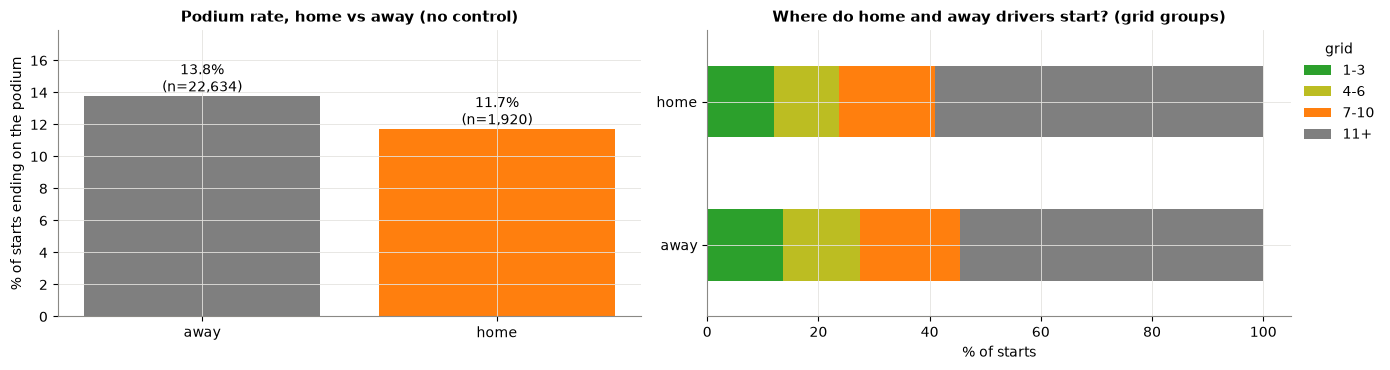

grid_group,1-3,4-6,7-10,11+
home,,,,
False,13.7,13.7,18.1,54.5
True,12.0,11.7,17.2,59.1


In [61]:
# Q2 without control: home vs away podium rate, and where home / away drivers start
raw_rate = q2.groupby('home')['podium'].agg(['sum', 'size'])
raw_rate['rate'] = raw_rate['sum'] / raw_rate['size']
grid_mix = pd.crosstab(q2['home'], q2['grid_group'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
labels = ['away', 'home']
axes[0].bar(labels, raw_rate.reindex([False, True])['rate'] * 100, color=['tab:gray', 'tab:orange'])
for i, (r, n) in enumerate(zip(raw_rate.reindex([False, True])['rate'], raw_rate.reindex([False, True])['size'])):
    axes[0].text(i, r * 100, f'{r:.1%}\n(n={n:,})', ha='center', va='bottom')
axes[0].set_ylim(0, raw_rate['rate'].max() * 100 * 1.3)
axes[0].set_ylabel('% of starts ending on the podium')
axes[0].set_title('Podium rate, home vs away (no control)')
grid_mix.reindex([False, True]).set_axis(labels).plot(kind='barh', stacked=True, ax=axes[1],
                                                  color=['tab:green', 'tab:olive', 'tab:orange', 'tab:gray'])
axes[1].set_xlabel('% of starts')
axes[1].set_title('Where do home and away drivers start? (grid groups)')
axes[1].legend(title='grid', bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout()
savefig(fig, 'p4_q2_uncontrolled')
plt.show()
display(grid_mix.round(1))

**Hints.** 1,920 home starts (7.8%). Without control, home drivers podium *less* (11.7% vs 13.8%) because they
start from grid 11+ more often (59% vs 55%; local drivers in weaker cars) → starting position must be controlled.

#### 4.2.2 With control: home vs away inside each grid group

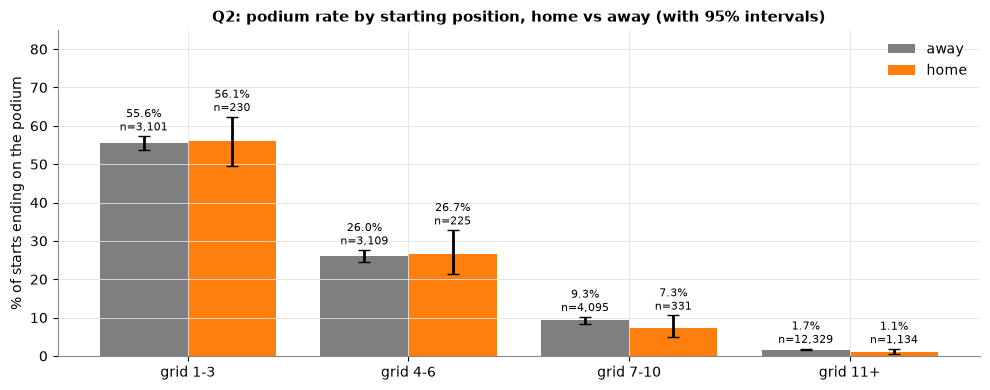

home,away,home
grid_group,,
1-3,0.556,0.561
4-6,0.260,0.267
7-10,0.093,0.073
11+,0.017,0.011


In [62]:
# Q2 with control: home vs away podium rate inside each grid group
by_group = q2.groupby(['grid_group', 'home'], observed=True)['podium'].agg(podiums='sum', starts='size').reset_index()
by_group['rate'] = by_group['podiums'] / by_group['starts']
by_group['low'], by_group['high'] = wilson_interval(by_group['podiums'], by_group['starts'])

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(GRID_GROUP_NAMES))
for offset, is_home, color, label in [(-0.2, False, 'tab:gray', 'away'), (0.2, True, 'tab:orange', 'home')]:
    rows = by_group[by_group['home'] == is_home].set_index('grid_group').reindex(GRID_GROUP_NAMES)
    ax.bar(x + offset, rows['rate'] * 100, width=0.4, color=color, label=label,
           yerr=[(rows['rate'] - rows['low']) * 100, (rows['high'] - rows['rate']) * 100], capsize=4)
    for xi, r, h, n in zip(x + offset, rows['rate'], rows['high'], rows['starts']):
        ax.text(xi, h * 100 + 1.5, f'{r:.1%}\nn={n:,}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f'grid {g}' for g in GRID_GROUP_NAMES])
ax.set_ylim(0, 85)
ax.set_ylabel('% of starts ending on the podium')
ax.set_title('Q2: podium rate by starting position, home vs away (with 95% intervals)')
ax.legend()
plt.tight_layout()
savefig(fig, 'p4_q2_by_grid_group')
plt.show()
display(by_group.pivot(index='grid_group', columns='home', values='rate').rename(columns={False: 'away', True: 'home'}).round(3))

**Hints.** Inside each grid group home ≈ away (1–3: 56.1% vs 55.6%; 4–6: 26.7% vs 26.0%; 7–10: 7.3% vs 9.3%;
11+: 1.1% vs 1.7%); all intervals overlap.

#### 4.2.3 One number: home podiums observed vs expected from their starting positions

Expected = the podiums home drivers would have if they converted like away drivers from the same grid group. Ratio
above 1 = home advantage. 95% interval from a bootstrap over races (2,000 resamples).

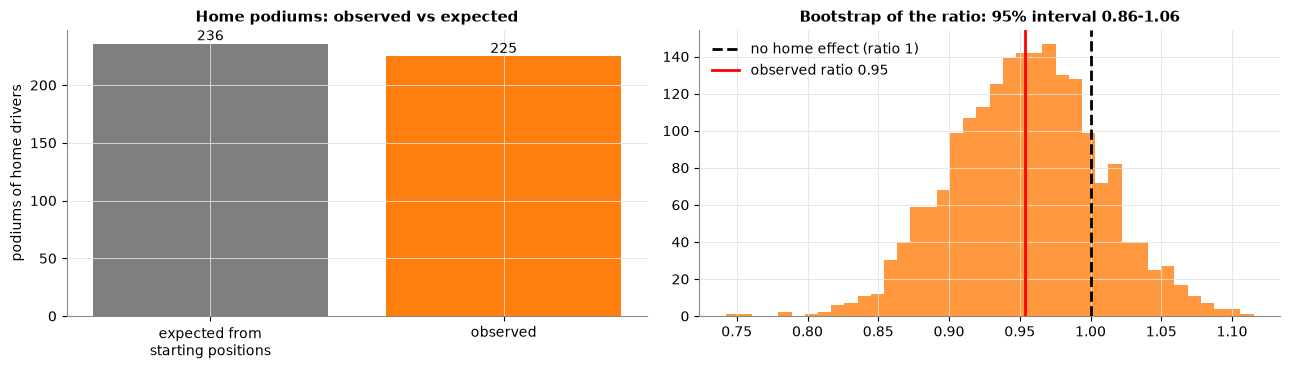

Home podiums: observed 225, expected 235.9, ratio 0.95 (95% interval 0.86-1.06)


In [63]:
# Q2: observed vs expected home podiums, with a bootstrap interval over races
def observed_vs_expected(df):
    away_rate = df[~df['home']].groupby('grid_group', observed=True)['podium'].mean()
    home = df[df['home']]
    expected = home['grid_group'].map(away_rate).astype(float).sum()
    return home['podium'].sum(), expected

observed, expected = observed_vs_expected(q2)

# bootstrap over races: per race and grid group, count home/away starts and podiums once, then resample races
counts = (q2.assign(home_start=q2['home'].astype(int), home_podium=(q2['home'] & (q2['podium'] == 1)).astype(int),
                    away_start=(~q2['home']).astype(int), away_podium=(~q2['home'] & (q2['podium'] == 1)).astype(int))
            .groupby(['raceId', 'grid_group'], observed=False)[['home_start', 'home_podium', 'away_start', 'away_podium']]
            .sum())
per_race = counts.to_numpy().reshape(q2['raceId'].nunique(), len(GRID_GROUP_NAMES), 4)

rng = np.random.default_rng(SEED)
ratios = []
for _ in range(2000):
    sample = per_race[rng.integers(0, len(per_race), len(per_race))].sum(axis=0)
    away_rate = sample[:, 3] / sample[:, 2]
    ratios.append(sample[:, 1].sum() / (sample[:, 0] * away_rate).sum())
low, high = np.percentile(ratios, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(['expected from\nstarting positions', 'observed'], [expected, observed], color=['tab:gray', 'tab:orange'])
for i, v in enumerate([expected, observed]):
    axes[0].text(i, v, f'{v:.0f}', ha='center', va='bottom')
axes[0].set_ylabel('podiums of home drivers')
axes[0].set_title('Home podiums: observed vs expected')
axes[1].hist(ratios, bins=40, color='tab:orange', alpha=0.8)
axes[1].axvline(1, color='black', linestyle='--', label='no home effect (ratio 1)')
axes[1].axvline(observed / expected, color='red', label=f'observed ratio {observed / expected:.2f}')
axes[1].set_title(f'Bootstrap of the ratio: 95% interval {low:.2f}-{high:.2f}')
axes[1].legend()
plt.tight_layout()
savefig(fig, 'p4_q2_observed_vs_expected')
plt.show()
print(f'Home podiums: observed {observed}, expected {expected:.1f}, ratio {observed / expected:.2f} '
      f'(95% interval {low:.2f}-{high:.2f})')

**Hints.** Expected 236, observed 225: ratio **0.95** (95% interval 0.86–1.06, contains 1 = no effect).

#### Q2 answer

**No.** Once starting position is controlled, drivers do **not** podium more often at a circuit in their home country:
home and away rates are nearly identical in every grid group, and home drivers have 0.95 times the podiums their
starting positions predict (95% interval 0.86–1.06). The lower raw home rate (11.7% vs 13.8%) comes from where home
drivers start, not from being at home. Any home advantage must therefore already show up *before* the race (in
qualifying and the grid), not in the race itself. This is an association over all seasons, not a causal statement, and
the grid groups control the starting position only roughly.

**Grain, missingness, cutoff.** Grain: one row per start. Nationality and circuit country are never missing; 14
nationalities have no circuit in their country and are always "away"; the two dual nationalities are at home in either
country. Cutoff: whether a race is a home race and the grid are both known before the race, so `home` could even be a
model feature: Phase 5 tests it as a candidate (5.9).

### 4.3 Q3: Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definitions**
- Mechanical retirement = a start that ended because a car component failed. Every 2014–2024 status is grouped:
  finished / mechanical / not mechanical (crash, driver, regulation or team decision) / unknown ("Retired", no
  cause). Puncture, tyre, fire and safety belt count as mechanical; refuelling does not.
- Rate = mechanical retirements ÷ starts (every row of `base` is a start).
- "Retired" (no cause) is left out of the main answer and counted in a sensitivity check.
- Constructors are grouped by **team lineage** (Toro Rosso → AlphaTauri → RB); a per-name view is also shown.

**Join:** `base` → `status` → `constructors` (team name) → lineage table; `races` gives the year.

In [64]:
# Q3 definitions (D9): status groups, team lineages and the 2014-2024 starts
FINISHED = ['Finished'] + [f'+{n} Lap' for n in [1]] + [f'+{n} Laps' for n in range(2, 10)]
MECHANICAL = ['Engine', 'Power Unit', 'Gearbox', 'Transmission', 'Clutch', 'Drivetrain', 'Driveshaft', 'Differential',
              'Brakes', 'Brake duct', 'Suspension', 'Hydraulics', 'Electrical', 'Electronics', 'Battery', 'ERS', 'Turbo',
              'Power loss', 'Exhaust', 'Throttle', 'Spark plugs', 'Oil leak', 'Oil pressure', 'Water leak',
              'Water pressure', 'Water pump', 'Radiator', 'Cooling system', 'Overheating', 'Fuel pressure', 'Fuel leak',
              'Fuel system', 'Fuel pump', 'Wheel', 'Wheel nut', 'Puncture', 'Tyre', 'Tyre puncture', 'Front wing',
              'Rear wing', 'Undertray', 'Steering', 'Vibrations', 'Seat', 'Mechanical', 'Technical', 'Fire', 'Safety belt']
NOT_MECHANICAL = ['Collision', 'Collision damage', 'Accident', 'Spun off', 'Damage', 'Debris', 'Disqualified', 'Excluded',
                  'Withdrew', 'Illness', 'Out of fuel', 'Refuelling']
UNKNOWN = ['Retired']

LINEAGE = {   # constructor name -> team lineage (renamed teams keep one history)
    'Force India': 'Force India / Racing Point / Aston Martin', 'Racing Point': 'Force India / Racing Point / Aston Martin',
    'Aston Martin': 'Force India / Racing Point / Aston Martin',
    'Toro Rosso': 'Toro Rosso / AlphaTauri / RB', 'AlphaTauri': 'Toro Rosso / AlphaTauri / RB',
    'RB F1 Team': 'Toro Rosso / AlphaTauri / RB',
    'Lotus F1': 'Lotus / Renault / Alpine', 'Renault': 'Lotus / Renault / Alpine', 'Alpine F1 Team': 'Lotus / Renault / Alpine',
    'Sauber': 'Sauber / Alfa Romeo', 'Alfa Romeo': 'Sauber / Alfa Romeo',
    'Marussia': 'Marussia / Manor', 'Manor Marussia': 'Marussia / Manor',
    'Haas F1 Team': 'Haas',
}
PERIODS = {'2014-2021': (2014, 2021), '2022-2024': (2022, 2024)}

q3 = base[base['year'].between(2014, 2024)].copy()
q3['period'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
q3['lineage'] = q3['team'].map(LINEAGE).fillna(q3['team'])
q3['outcome'] = np.select(
    [q3['status'].isin(FINISHED), q3['status'].isin(MECHANICAL), q3['status'].isin(NOT_MECHANICAL), q3['status'].isin(UNKNOWN)],
    ['finished', 'mechanical', 'not mechanical', 'unknown ("Retired")'], default='UNCLASSIFIED')
assert (q3['outcome'] != 'UNCLASSIFIED').all(), q3.loc[q3['outcome'] == 'UNCLASSIFIED', 'status'].unique()
print(f'Starts 2014-2024: {len(q3)} | statuses: {q3["status"].nunique()}, all classified')

Starts 2014-2024: 4597 | statuses: 65, all classified


#### 4.3.1 How do races end in 2014–2024? (status groups)

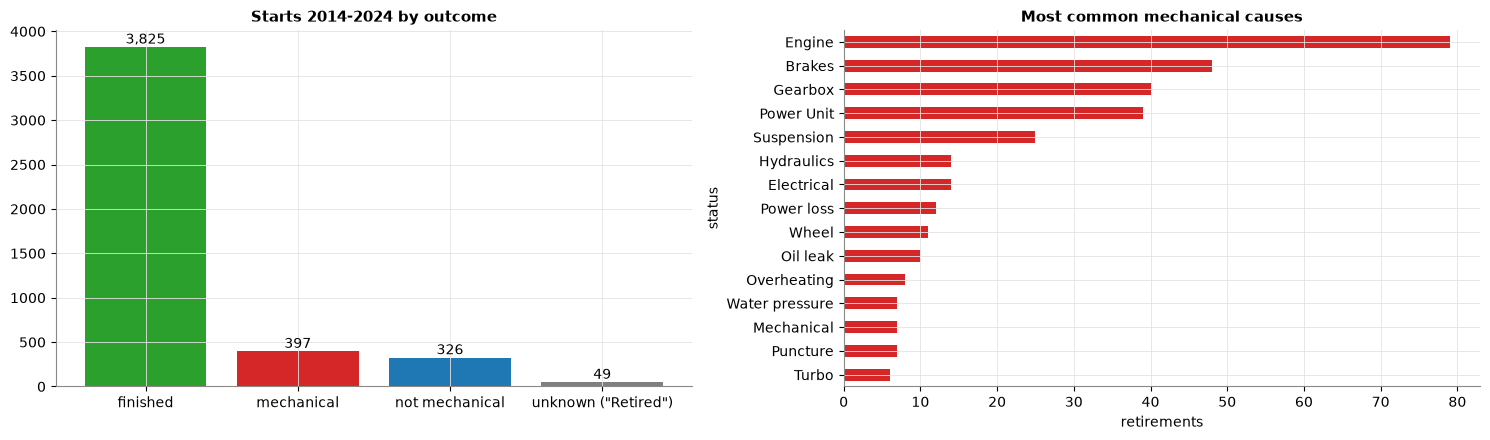

In [65]:
# Q3: how races end in 2014-2024, and the most common mechanical causes
outcome_counts = q3['outcome'].value_counts()
mechanical_statuses = q3.loc[q3['outcome'] == 'mechanical', 'status'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(outcome_counts.index, outcome_counts.values,
            color=[{'finished': 'tab:green', 'mechanical': 'tab:red', 'not mechanical': 'tab:blue',
                    'unknown ("Retired")': 'tab:gray'}[o] for o in outcome_counts.index])
for i, v in enumerate(outcome_counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
axes[0].set_title('Starts 2014-2024 by outcome')
mechanical_statuses.head(15).sort_values().plot(kind='barh', ax=axes[1], color='tab:red')
axes[1].set_title('Most common mechanical causes')
axes[1].set_xlabel('retirements')
plt.tight_layout()
savefig(fig, 'p4_q3_outcomes')
plt.show()

**Hints.** 4,597 starts: 3,825 finished, 397 mechanical, 326 crash / other, 49 only "Retired" (37 in 2014–21, 12 in
2022–24). All 65 statuses are assigned (the code stops otherwise). Top causes: engine 79, brakes 48, gearbox 40, power
unit 39.

#### 4.3.2 Team lineages: which names belong to the same team?

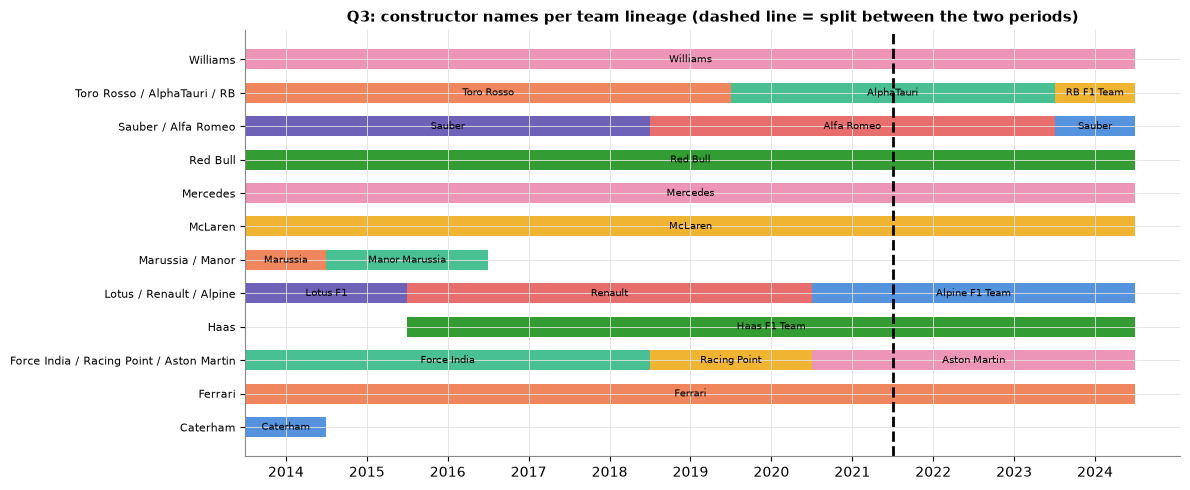

In [66]:
# one block per run of consecutive seasons with the same name (Sauber is used in 2014-2018 and again in 2024)
team_years = q3[['lineage', 'year', 'team']].drop_duplicates().sort_values(['lineage', 'year'])
team_years['new_block'] = (team_years['team'] != team_years.groupby('lineage')['team'].shift()).astype(int)
team_years['block'] = team_years.groupby('lineage')['new_block'].cumsum()
names_by_year = (team_years.groupby(['lineage', 'block', 'team'])['year'].agg(['min', 'max'])
                 .reset_index().sort_values(['lineage', 'min']))
lineages = sorted(q3['lineage'].unique())

fig, ax = plt.subplots(figsize=(12, 5))
for i, lineage in enumerate(lineages):
    for _, row in names_by_year[names_by_year['lineage'] == lineage].iterrows():
        ax.barh(i, row['max'] - row['min'] + 1, left=row['min'] - 0.5, height=0.6, alpha=0.8)
        ax.text((row['min'] + row['max']) / 2, i, row['team'], ha='center', va='center', fontsize=7)
ax.axvline(2021.5, color='black', linestyle='--')
ax.set_yticks(range(len(lineages)))
ax.set_yticklabels(lineages, fontsize=8)
ax.set_xticks(range(2014, 2025))
ax.set_title('Q3: constructor names per team lineage (dashed line = split between the two periods)')
plt.tight_layout()
savefig(fig, 'p4_q3_lineages')
plt.show()

**Hints.** Five teams were renamed in this period, some inside 2022–24 (AlphaTauri → RB, Alfa Romeo → Sauber).
Lineages keep each team's history together (e.g. the Faenza team: 136 starts in 2022–24 instead of two small groups).

#### 4.3.3 Mechanical-retirement rate per team, 2014–2021 vs 2022–2024

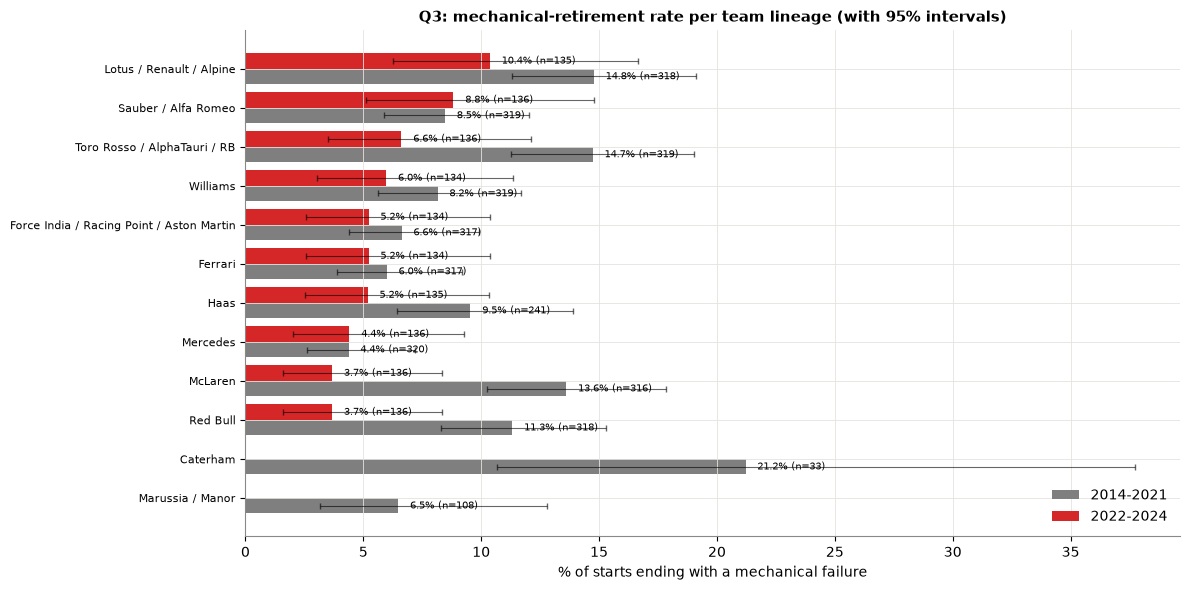

2014-2021: highest -> {'Caterham': 0.212, 'Lotus / Renault / Alpine': 0.148, 'Toro Rosso / AlphaTauri / RB': 0.147}
2022-2024: highest -> {'Lotus / Renault / Alpine': 0.104, 'Sauber / Alfa Romeo': 0.088, 'Toro Rosso / AlphaTauri / RB': 0.066}
All teams: {'2014-2021': '9.8%', '2022-2024': '5.9%'}


In [67]:
# Q3: mechanical-retirement rate per team lineage and period, with 95% intervals
def mechanical_rate(df, group_col, count_retired_as_mechanical=False):
    mech = df['outcome'].eq('mechanical')
    if count_retired_as_mechanical:
        mech = mech | df['outcome'].eq('unknown ("Retired")')
    table = df.assign(mech=mech).groupby([group_col, 'period'])['mech'].agg(retirements='sum', starts='size').reset_index()
    table['rate'] = table['retirements'] / table['starts']
    table['low'], table['high'] = wilson_interval(table['retirements'], table['starts'])
    return table

rates = mechanical_rate(q3, 'lineage')
order = (rates.pivot(index='lineage', columns='period', values='rate')
              .sort_values(['2022-2024', '2014-2021'], na_position='first').index)

fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(order))
for offset, period, color in [(-0.2, '2014-2021', 'tab:gray'), (0.2, '2022-2024', 'tab:red')]:
    rows = rates[rates['period'] == period].set_index('lineage').reindex(order)
    ax.barh(y + offset, rows['rate'] * 100, height=0.4, color=color, label=period,
            xerr=[(rows['rate'] - rows['low']).fillna(0) * 100, (rows['high'] - rows['rate']).fillna(0) * 100],
            capsize=2, error_kw={'elinewidth': 0.8, 'alpha': 0.6})
    for yi, r, n in zip(y + offset, rows['rate'], rows['starts']):
        if pd.notna(r):
            ax.text(r * 100 + 0.5, yi, f'{r:.1%} (n={n:.0f})', va='center', fontsize=7)
ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel('% of starts ending with a mechanical failure')
ax.set_title('Q3: mechanical-retirement rate per team lineage (with 95% intervals)')
ax.legend(loc='lower right')
plt.tight_layout()
savefig(fig, 'p4_q3_rate_by_team')
plt.show()

rate_table = rates.pivot(index='lineage', columns='period', values='rate')
for period in PERIODS:
    print(f'{period}: highest ->', rate_table[period].dropna().sort_values(ascending=False).head(3).round(3).to_dict())
print('All teams:', q3.groupby('period')['outcome'].apply(lambda s: f"{(s == 'mechanical').mean():.1%}").to_dict())

**Hints.**
- Overall: 9.8% of starts (2014–21) → 5.9% (2022–24).
- 2014–21 highest: Caterham 21.2% (33 starts, wide interval), Lotus / Renault / Alpine 14.8%, Toro Rosso /
  AlphaTauri / RB 14.7%, McLaren 13.6% (Honda years); lowest Mercedes 4.4%.
- 2022–24 highest: Lotus / Renault / Alpine 10.4%, Sauber / Alfa Romeo 8.8%, Toro Rosso / AlphaTauri / RB 6.6%;
  lowest McLaren and Red Bull 3.7%.
- ~135 starts per team in 2022–24 → wide intervals (e.g. Alpine 6–17%).

#### 4.3.4 Sensitivity: what if "Retired" (no cause given) were mechanical?

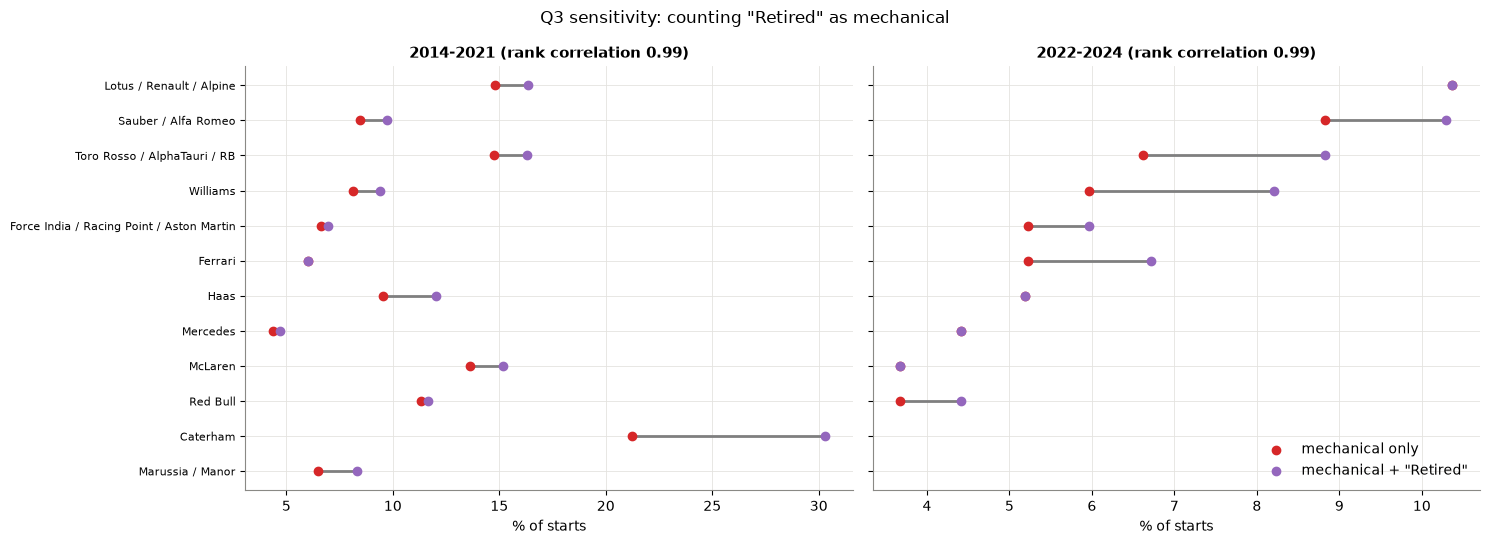

2014-2021: top 3 with "Retired" counted -> ['Caterham', 'Lotus / Renault / Alpine', 'Toro Rosso / AlphaTauri / RB']
2022-2024: top 3 with "Retired" counted -> ['Lotus / Renault / Alpine', 'Sauber / Alfa Romeo', 'Toro Rosso / AlphaTauri / RB']


In [68]:
# Q3 sensitivity: count the 'Retired' (no cause) rows as mechanical
with_retired = mechanical_rate(q3, 'lineage', count_retired_as_mechanical=True)
compare = rates.merge(with_retired, on=['lineage', 'period'], suffixes=('', ' incl. Retired'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
y_all = np.arange(len(order))                     # every team keeps the same row in both panels
for ax, period in zip(axes, PERIODS):
    rows = compare[compare['period'] == period].set_index('lineage').reindex(order)
    has_data = rows['rate'].notna().to_numpy()
    ax.hlines(y_all[has_data], rows['rate'][has_data] * 100, rows['rate incl. Retired'][has_data] * 100, color='tab:gray')
    ax.scatter(rows['rate'][has_data] * 100, y_all[has_data], color='tab:red', label='mechanical only', zorder=3)
    ax.scatter(rows['rate incl. Retired'][has_data] * 100, y_all[has_data], color='tab:purple',
               label='mechanical + "Retired"', zorder=3)
    corr = rows['rate'].corr(rows['rate incl. Retired'], method='spearman')
    ax.set_title(f'{period} (rank correlation {corr:.2f})')
    ax.set_xlabel('% of starts')
axes[0].set_yticks(y_all)
axes[0].set_yticklabels(order, fontsize=8)
axes[1].legend(loc='lower right')
fig.suptitle('Q3 sensitivity: counting "Retired" as mechanical')
plt.tight_layout()
savefig(fig, 'p4_q3_sensitivity')
plt.show()
for period in PERIODS:
    top = compare[compare['period'] == period].sort_values('rate incl. Retired', ascending=False).head(3)['lineage'].tolist()
    print(f'{period}: top 3 with "Retired" counted ->', top)

**Hints.** Counting the 49 "Retired" rows as mechanical barely changes the order (rank correlation 0.99, same top 3
in both periods).

#### 4.3.5 Raw view: one bar per constructor name (no lineage)

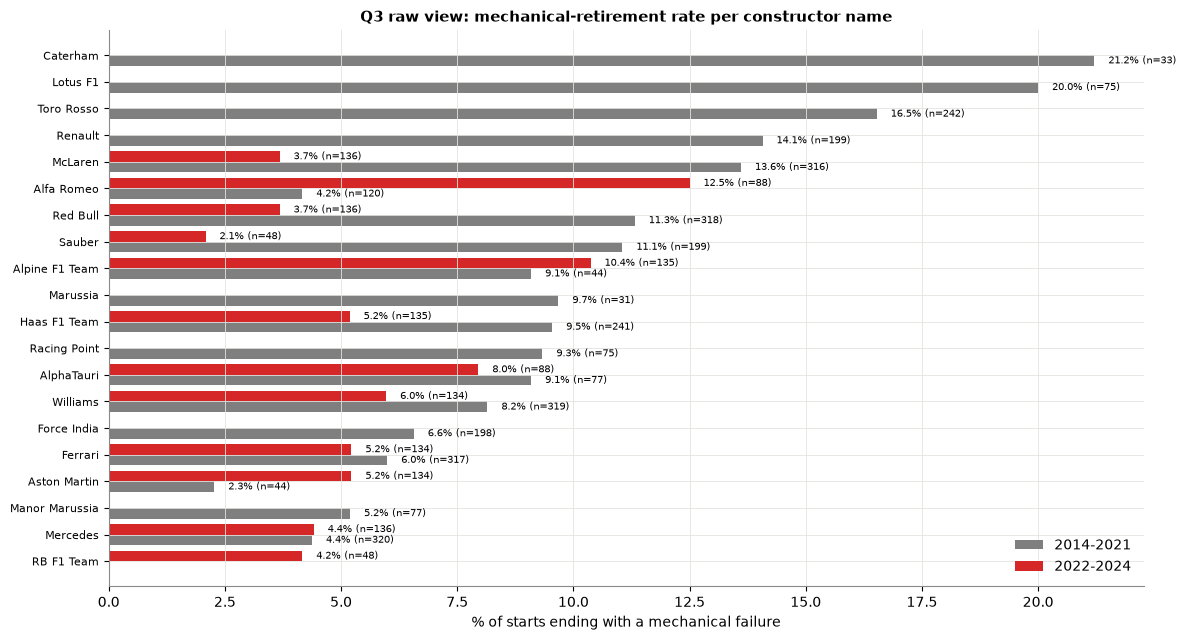

In [69]:
# Q3 raw view: one bar per constructor name (no lineage)
raw_rates = mechanical_rate(q3, 'team')
raw_order = raw_rates.groupby('team')['rate'].max().sort_values().index

fig, ax = plt.subplots(figsize=(12, 6.5))
y = np.arange(len(raw_order))
for offset, period, color in [(-0.2, '2014-2021', 'tab:gray'), (0.2, '2022-2024', 'tab:red')]:
    rows = raw_rates[raw_rates['period'] == period].set_index('team').reindex(raw_order)
    ax.barh(y + offset, rows['rate'] * 100, height=0.4, color=color, label=period)
    for yi, r, n in zip(y + offset, rows['rate'], rows['starts']):
        if pd.notna(r):
            ax.text(r * 100 + 0.3, yi, f'{r:.1%} (n={n:.0f})', va='center', fontsize=7)
ax.set_yticks(y)
ax.set_yticklabels(raw_order, fontsize=8)
ax.set_xlabel('% of starts ending with a mechanical failure')
ax.set_title('Q3 raw view: mechanical-retirement rate per constructor name')
ax.legend(loc='lower right')
plt.tight_layout()
savefig(fig, 'p4_q3_rate_by_name')
plt.show()

**Hints.** Split by name, the picture is noisy and misleading: "Alfa Romeo" 12.5% vs "Sauber" 2.1% are the same team;
"Lotus F1" 20.0% comes from only 2 seasons → the main answer uses lineages.

#### Q3 answer

- **2014–2021:** the highest mechanical-retirement rates were **Caterham (21%, one season only)**, **Lotus / Renault /
  Alpine (15%)**, **Toro Rosso / AlphaTauri / RB (15%)** and **McLaren (14%)**.
- **2022–2024:** **Lotus / Renault / Alpine (10%)**, **Sauber / Alfa Romeo (9%)** and **Toro Rosso / AlphaTauri / RB (7%)**.
- The Enstone team (Lotus / Renault / Alpine) is the least reliable in **both** periods. Reliability improved for
  almost everyone (9.8% → 5.9% overall); McLaren and Red Bull improved the most (to 3.7%).
- The result is robust to the treatment of "Retired" (rank correlation 0.99); the ranking below the top is uncertain
  because of the small 2022–2024 samples.

**Grain, missingness, cutoff.** Grain: one row per start (the denominator), 2014–2024: 4,597 starts. `status` is never
missing; 49 rows have only "Retired" (sensitivity analysis). Cutoff: the status of a race is only known after it, which
is fine for this analysis question; as a model feature only the statuses of **past** races may be used (e.g. a team's
recent reliability, Phase 5).

### 4.4 Phase 4 summary

| Question | Answer | Main evidence |
|---|---|---|
| Q1: front-row conversion by circuit, before vs after 2014 | Before: Suzuka, Hungaroring, Barcelona, Bahrain (67–70%); since 2014: Monaco, Suzuka, Yas Marina (86–90%). The ranking changes almost completely (rank correlation −0.08); conversion rises everywhere (56% → 76%) | 4.1.1–4.1.4; grid (not qualifying) used, 4.1.5 |
| Q2: home podium advantage, controlling for grid | No: home ≈ away in every grid group; observed/expected podiums 0.95 (0.86–1.06) | 4.2.1–4.2.3 |
| Q3: mechanical-retirement rate by constructor | 2014–21: Caterham, Lotus/Renault/Alpine, Toro Rosso/AlphaTauri/RB, McLaren; 2022–24: Lotus/Renault/Alpine, Sauber/Alfa Romeo, Toro Rosso/AlphaTauri/RB; overall 9.8% → 5.9% | 4.3.1–4.3.5; robust to "Retired" |

All figures are saved in `figures/p4_*.png` for the report.

## 5. Feature engineering

Each row asks: *given everything known after qualifying, will this driver finish on the podium?* A feature is kept
only if it passes four tests:

| Test | Question | How we check it here |
|---|---|---|
| T1 cutoff | Is it known before lights out? | built only from the grid, qualifying, and races **strictly before** this one; leakage checks in 5.10 |
| T2 signal | Does the podium rate change with it? | EDA plot per group + its ROC-AUC on its own (0.5 = no signal) on the **training seasons** |
| T3 coverage & stable meaning | Is it filled, and does it mean the same, in train / validation / test? | coverage per period; signal re-checked on validation |
| T4 contribution | Does removing it hurt the trained model? | feature-group ablation, Phase 8 |

**Rows:** seasons from **2003** (complete qualifying, 2.2), split train 2003–2019 / validation 2020–2021 / test
2022–2024. Test labels are never used for a choice. **History** features use all earlier races, including those
before 2003.

### 5.0 Setup: the cleaned table and three helpers

In [70]:
# load the cleaned table of Phase 3, add the qualifying position, and define the periods and three helpers
from sklearn.metrics import roc_auc_score

fe = pd.read_csv(PROC_DIR / "base.csv", parse_dates=["date"])                  # starts from the saved, cleaned table
quali_positions = (pd.read_csv(PROC_DIR / "qualifying.csv")[["raceId", "driverId", "position"]]
                   .rename(columns={"position": "quali_position"}))
fe = fe.merge(quali_positions, on=["raceId", "driverId"], how="left", validate="one_to_one")
fe = fe.sort_values(["date", "raceId", "positionOrder"]).reset_index(drop=True)
fe["period"] = pd.cut(fe["year"], [1949, 2002, 2019, 2021, 2024], labels=["history only", "train", "validation", "test"])
PERIODS = ["train", "validation", "test"]
print(fe["period"].value_counts().reindex(["history only"] + PERIODS).rename("rows").to_frame().T)


def past_values(df, keys, col, how, window=None):
    """Value of `col` over the group's EARLIER rows only: shift(1) drops the current race before the window."""
    shifted = df.groupby(keys)[col].shift(1)
    grouped = shifted.groupby([df[k] for k in keys])
    if how == "rolling":
        return grouped.transform(lambda s: s.rolling(window, min_periods=1).mean())
    return grouped.transform(lambda s: s.expanding().mean())


def signal(df, feature):
    """ROC-AUC of one feature on its own (oriented, so 0.5 = no signal, 1 = perfect) and its direction."""
    d = df[[feature, "podium"]].dropna()
    auc = roc_auc_score(d["podium"], d[feature].astype(float))
    return round(max(auc, 1 - auc), 3), ("+" if auc >= 0.5 else "−")


def evidence(df, features):
    """Coverage per period (inputs only) and signal on train and validation (never test)."""
    rows = []
    for f in features:
        r = {"feature": f}
        for p in PERIODS:
            r[f"coverage {p}"] = round(df.loc[df["period"] == p, f].notna().mean(), 3)
        for p in ["train", "validation"]:
            r[f"AUC {p}"], r["direction"] = signal(df[df["period"] == p], f)
        rows.append(r)
    return pd.DataFrame(rows).set_index("feature")


def rate_plot(ax, df, groups, title, xlabel, color=PALETTE[0]):
    """Bar chart of the podium rate per group, with the number of rows above each bar."""
    t = df.groupby(groups, observed=True)["podium"].agg(["mean", "size"])
    x = np.arange(len(t))
    ax.bar(x, t["mean"], color=color, width=0.7)
    for i, (m, n) in enumerate(t.values):
        ax.text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x, [str(i) for i in t.index], rotation=0)
    ax.set_ylim(0, t["mean"].max() * 1.3)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("podium rate")
    return t


train_view = lambda: fe[fe["period"] == "train"]

period  history only  train  validation  test
rows           15645   6782         775  1352


### 5.1 Identity rules and status groups (inputs for the history features)

History features follow an ID through time, so the ID must be right: car numbers change, drivers change teams, teams
change names. The reliability features also need every race ending grouped.

**Car numbers are not identifiers.**

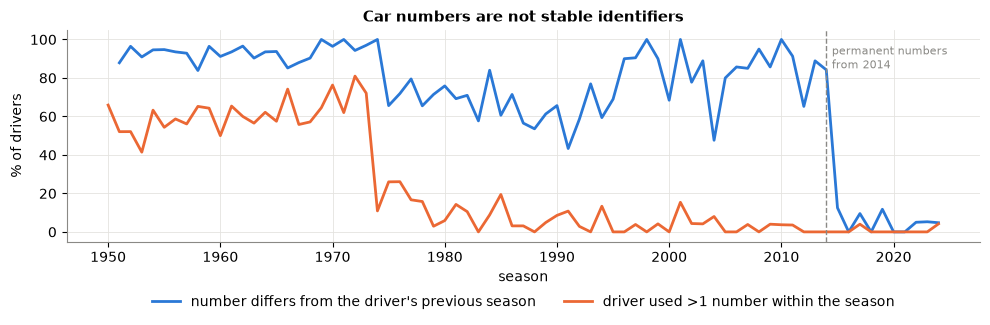

before 2014: 82% of returning drivers changed number; 2015+: 5%
people with the same name and date of birth under two driverIds: 0
driver-seasons since 2003 with a mid-season team change: 13


In [71]:
# how often a returning driver's car number changed from one season to the next (and within a season)
modal_number = (fe.dropna(subset=["number"]).groupby(["driverId", "year"])["number"]
                .agg(lambda s: s.mode().iat[0]).reset_index().sort_values(["driverId", "year"]))
modal_number["prev"] = modal_number.groupby("driverId")["number"].shift()
modal_number["changed"] = modal_number["number"].ne(modal_number["prev"]) & modal_number["prev"].notna()
change_rate = modal_number.dropna(subset=["prev"]).groupby("year")["changed"].mean() * 100
within_season = (fe.groupby(["driverId", "year"])["number"].nunique() > 1).groupby(level="year").mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(change_rate.index, change_rate.values, color=PALETTE[0], label="number differs from the driver's previous season")
ax.plot(within_season.index, within_season.values, color=PALETTE[1], label="driver used >1 number within the season")
ax.axvline(2014, color=GREY, linestyle="--", linewidth=1)
ax.text(2014.5, 85, "permanent numbers\nfrom 2014", fontsize=8, color=GREY)
ax.set_title("Car numbers are not stable identifiers")
ax.set_xlabel("season")
ax.set_ylabel("% of drivers")
ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.38))
fig.tight_layout()
savefig(fig, "p5_car_number_drift")
plt.show()
print(f"before 2014: {change_rate.loc[:2013].mean():.0f}% of returning drivers changed number; 2015+: {change_rate.loc[2015:].mean():.0f}%")

drivers_saved = pd.read_csv(PROC_DIR / "drivers.csv")
print("people with the same name and date of birth under two driverIds:",
      int(drivers_saved.duplicated(["forename", "surname", "dob"]).sum()))
team_moves = fe[fe["year"] >= 2003].groupby(["driverId", "surname", "year"])["constructorId"].nunique()
print("driver-seasons since 2003 with a mid-season team change:", int((team_moves > 1).sum()))

**Hints.** Before 2014, 82% of returning drivers changed number (5% since 2015). No person has two `driverId`s; 13
driver-seasons since 2003 had a mid-season team change → `number` is never used; driver history follows `driverId`
across teams.

**Constructors: renamed teams and re-used IDs.** A renamed team gets a new `constructorId` (renames reset history);
an old name returning decades later re-uses the old ID. Each ID is split into **stints** separated by at least one
season without a race.

,chain,team,constructorId,years in data
0,Minardi line,Minardi,18,1985–2005
1,Minardi line,Toro Rosso,5,2006–2019
2,Minardi line,AlphaTauri,213,2020–2023
3,Minardi line,RB F1 Team,215,2024–2024
4,Jordan line,Jordan,17,1991–2005
5,Jordan line,MF1,13,2006–2006
6,Jordan line,Spyker MF1,14,2006–2006
7,Jordan line,Spyker,12,2007–2007
8,Jordan line,Force India,10,2008–2018
9,Jordan line,Racing Point,211,2019–2020


constructorIds with more than one stint: 28 | active since 2003 with a gap of 5+ seasons: 6


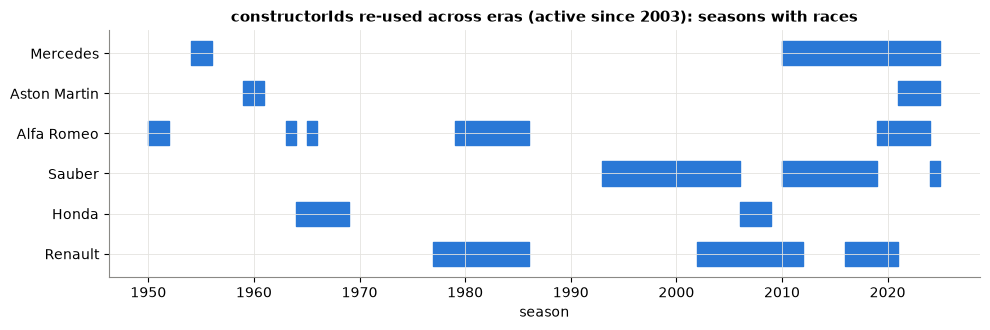

In [72]:
# renamed teams (ownership chains since 2003) and constructorIds re-used after a long gap -> constructor stints
RENAME_CHAINS = {
    "Minardi line": ["Minardi", "Toro Rosso", "AlphaTauri", "RB F1 Team"],
    "Jordan line": ["Jordan", "MF1", "Spyker MF1", "Spyker", "Force India", "Racing Point", "Aston Martin"],
    "BAR line": ["BAR", "Honda", "Brawn", "Mercedes"],
    "Benetton line": ["Benetton", "Renault", "Lotus F1", "Alpine F1 Team"],
    "Stewart line": ["Stewart", "Jaguar", "Red Bull"],
    "Sauber line": ["Sauber", "BMW Sauber", "Alfa Romeo"],
    "Virgin line": ["Virgin", "Marussia", "Manor Marussia"],
}
team_years = fe.groupby(["team", "constructorId"])["year"].agg(["min", "max"])
display(pd.DataFrame([{"chain": chain, "team": t, "constructorId": team_years.loc[t].index[0],
                       "years in data": f"{team_years.loc[t, 'min'].iat[0]}–{team_years.loc[t, 'max'].iat[0]}"}
                      for chain, teams in RENAME_CHAINS.items() for t in teams]))

seasons_active = fe[["constructorId", "year"]].drop_duplicates().sort_values(["constructorId", "year"])
seasons_active["constructor_stint"] = (seasons_active.groupby("constructorId")["year"].diff() > 1).groupby(
    seasons_active["constructorId"]).cumsum().astype(int)
fe = fe.merge(seasons_active, on=["constructorId", "year"], how="left", validate="many_to_one")

stints = (seasons_active.merge(fe[["constructorId", "team"]].drop_duplicates("constructorId"), on="constructorId")
          .groupby(["constructorId", "team", "constructor_stint"])["year"].agg(["min", "max"]).reset_index())
stints["gap_before"] = stints["min"] - stints.groupby("constructorId")["max"].shift()
reused = stints.groupby("constructorId").filter(lambda d: d["max"].max() >= 2003 and d["gap_before"].max() >= 5)
print(f"constructorIds with more than one stint: {stints.loc[stints['constructor_stint'] > 0, 'constructorId'].nunique()} | "
      f"active since 2003 with a gap of 5+ seasons: {reused['constructorId'].nunique()}")

fig, ax = plt.subplots(figsize=(10, 3.4))
for y_pos, (cid, d) in enumerate(reused.groupby("constructorId", sort=False)):
    ax.broken_barh([(a, b - a + 1) for a, b in zip(d["min"], d["max"])], (y_pos - 0.3, 0.6), color=PALETTE[0])
ax.set_yticks(range(reused["constructorId"].nunique()), reused.drop_duplicates("constructorId")["team"].tolist())
ax.set_title("constructorIds re-used across eras (active since 2003): seasons with races")
ax.set_xlabel("season")
fig.tight_layout()
savefig(fig, "p5_constructor_id_reuse")
plt.show()

**Hints.** Each name in a rename chain is a separate ID (AlphaTauri → RB starts with no history). 6 IDs active since
2003 were used by unrelated teams decades apart (Aston Martin, Mercedes, Alfa Romeo, Sauber in 2024, …) → constructor
form is computed per **(`constructorId`, `constructor_stint`)**; `team_races_history` tells a new team from a bad one.

**Status groups.** All 139 statuses are mapped to finished / mechanical / crash or driver / regulation or other; for
2014–2024 the mapping is checked against Q3 (4.3).

all 139 statuses mapped; for 2014-2024 'mechanical' agrees with D9 on all 4,597 starts


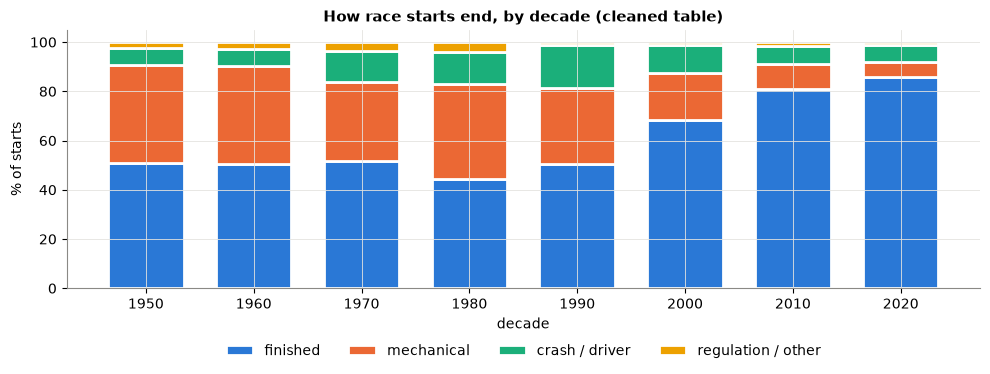

status_group,finished,mechanical,crash / driver,regulation / other
year,,,,
1950,50.9,39.9,6.8,2.4
1960,50.3,39.8,7.0,2.9
1970,51.8,32.1,12.4,3.6
1980,44.3,38.7,13.0,4.0
1990,50.6,30.6,17.6,1.1
2000,68.4,19.0,11.5,1.1
2010,80.9,10.4,7.3,1.5
2020,86.0,6.1,6.8,1.1


In [73]:
# map every status to finished / mechanical / crash or driver / regulation or other, and check it against D9
STATUS_GROUPS = {
    "did not qualify": ["Did not qualify", "Did not prequalify", "107% Rule"],
    "crash / driver": ["Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Damage", "Stalled",
                       "Physical", "Injured", "Injury", "Eye injury", "Driver unwell", "Illness"],
    "regulation / other": ["Disqualified", "Excluded", "Withdrew", "Not classified", "Retired", "Not restarted",
                           "Underweight", "Safety", "Safety concerns", "Out of fuel", "Fuel rig", "Refuelling", "Debris"],
    "mechanical": ["Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
                   "Brakes", "Differential", "Overheating", "Mechanical", "Tyre", "Puncture", "Tyre puncture",
                   "Driveshaft", "Fuel pressure", "Front wing", "Rear wing", "Broken wing", "Water pressure", "Wheel",
                   "Wheel rim", "Wheel nut", "Wheel bearing", "Throttle", "Steering", "Technical", "Electronics",
                   "Heat shield fire", "Exhaust", "Oil leak", "Water leak", "Fuel pump", "Track rod", "Oil pressure",
                   "Engine fire", "Engine misfire", "Pneumatics", "Handling", "Fire", "Fuel system", "Oil line",
                   "Launch control", "Fuel", "Power loss", "Vibrations", "Drivetrain", "Ignition", "Chassis", "Battery",
                   "Halfshaft", "Crankshaft", "Alternator", "Safety belt", "Driver Seat", "Seat", "Oil pump",
                   "Fuel leak", "Injection", "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs",
                   "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger", "Power Unit", "ERS",
                   "Brake duct", "Undertray", "Cooling system"],
}


def status_group(status):
    if status == "Finished" or pd.Series([status]).str.fullmatch(r"\+\d+ Laps?").iat[0]:
        return "finished"
    for group, values in STATUS_GROUPS.items():
        if status in values:
            return group
    raise ValueError(f"status without a group: {status!r}")


all_statuses = pd.read_csv(PROC_DIR / "status.csv")["status"]
listed = [s for values in STATUS_GROUPS.values() for s in values]
assert len(listed) == len(set(listed)), "a status is listed in two groups"
fe["status_group"] = fe["status"].map({s: status_group(s) for s in all_statuses})
q3_seasons = fe[fe["year"].between(2014, 2024)]
assert (q3_seasons["status_group"].eq("mechanical") == q3_seasons["status"].isin(MECHANICAL)).all(), "differs from D9"
print(f"all {all_statuses.size} statuses mapped; for 2014-2024 'mechanical' agrees with D9 on all {len(q3_seasons):,} starts")

GROUP_ORDER = ["finished", "mechanical", "crash / driver", "regulation / other"]
mix = pd.crosstab(fe["year"] // 10 * 10, fe["status_group"], normalize="index")[GROUP_ORDER] * 100
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(mix))
for group, color in zip(GROUP_ORDER, PALETTE[:4]):
    ax.bar(mix.index, mix[group], bottom=bottom, width=7, color=color, label=group, edgecolor="white", linewidth=2)
    bottom += mix[group].values
ax.set_title("How race starts end, by decade (cleaned table)")
ax.set_xlabel("decade")
ax.set_ylabel("% of starts")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.32))
fig.tight_layout()
savefig(fig, "p5_status_groups")
plt.show()
mix.round(1)

**Hints.** Every status has one group; the 2014–24 "mechanical" group is identical to Q3. Mechanical failures ended
~40% of starts in the 1950s–60s vs ~6% in the 2020s. Punctures, tyres and wings = mechanical; out of fuel, refuelling
and "Retired" (no cause) = not.

### 5.2 Grid: `grid_pos`, `grid_penalty`

Pole position is the strongest single predictor; a penalty moves a fast car back without making it slow.
* `grid_pos` = the starting slot after the pit-lane recode (3.4).
* `grid_penalty` = `grid_pos − quali_position` (positive = started behind where it qualified). Together the two also
  contain the qualifying position, so it is not added a third time.

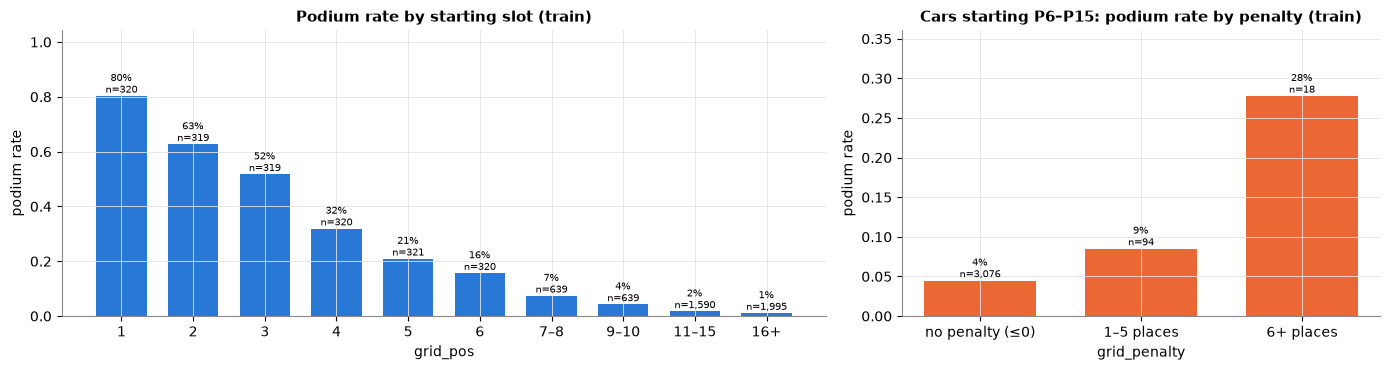

pit-lane starters in train: 19 | podiums: 0


,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
grid_pos,1.000,1.000,1.0,0.909,−,0.910
grid_penalty,0.997,0.999,1.0,0.556,+,0.539


In [74]:
# the starting slot (pit-lane starts were moved to the back of the grid by D5) and the grid penalty
fe["field_size"] = fe.groupby("raceId")["driverId"].transform("size")
fe["grid_pos"] = fe["grid"]
fe["grid_penalty"] = fe["grid_pos"] - fe["quali_position"]

tr = train_view()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
slot = pd.cut(tr["grid_pos"], [0, 1, 2, 3, 4, 5, 6, 8, 10, 15, 30], labels=["1", "2", "3", "4", "5", "6", "7–8", "9–10", "11–15", "16+"])
rate_plot(axes[0], tr, slot, "Podium rate by starting slot (train)", "grid_pos")
mid = tr[tr["grid_pos"].between(6, 15)]
pen = pd.cut(mid["grid_penalty"], [-30, 0, 5, 30], labels=["no penalty (≤0)", "1–5 places", "6+ places"])
rate_plot(axes[1], mid, pen, "Cars starting P6–P15: podium rate by penalty (train)", "grid_penalty", PALETTE[1])
fig.tight_layout()
savefig(fig, "p5_grid")
plt.show()
print("pit-lane starters in train:", int(tr["pitlane_start"].sum()), "| podiums:", int(tr.loc[tr["pitlane_start"] == 1, "podium"].sum()))
evidence(fe, ["grid_pos", "grid_penalty"])

**Hints.** The podium rate falls steeply with the slot (AUC ≈ 0.91 on train and validation). P6–P15 starters with a
penalty convert more (8.5% for 1–5 places, 28% for 6+) than those without (4.5%), but these groups are small (94 and
18 rows) → checked in the ablation. Pit-lane starters: 19 in train, 0 podiums.

### 5.3 Qualifying pace: `q1_gap_pct`

Grid = order, gap = margin. Measured in **Q1** (the only session every car runs) and in **percent** (1 s is small at
Spa, large at Monaco).

coverage of the qualifying sessions (2003+ rows): {'q1': 0.98, 'q2': 0.65, 'q3': 0.41}


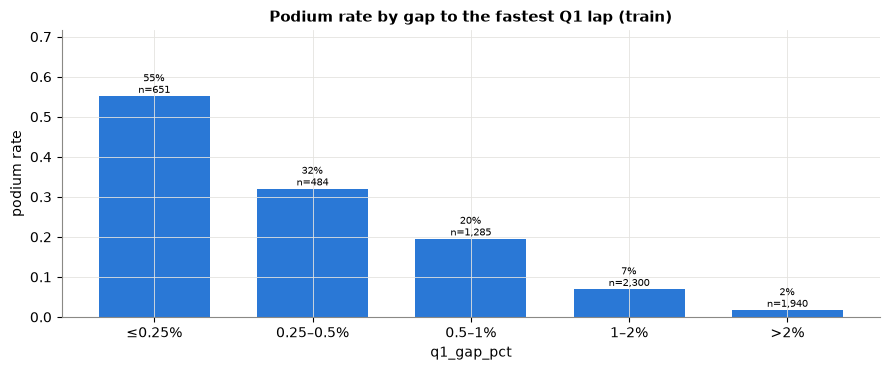

,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
q1_gap_pct,0.982,0.988,0.99,0.831,−,0.842


In [75]:
# Q1 lap times from the qualifying table, and the gap to the fastest Q1 lap of each race (%)
quali_times = pd.read_csv(PROC_DIR / "qualifying.csv")[["raceId", "driverId", "q1", "q2", "q3"]]
print("coverage of the qualifying sessions (2003+ rows):",
      fe[fe["year"] >= 2003].merge(quali_times, on=["raceId", "driverId"], how="left")[["q1", "q2", "q3"]]
      .notna().mean().round(2).to_dict())
fe = fe.merge(quali_times[["raceId", "driverId", "q1"]], on=["raceId", "driverId"], how="left", validate="one_to_one")
fe["q1_gap_pct"] = (fe["q1"] / fe.groupby("raceId")["q1"].transform("min") - 1) * 100

tr = train_view()
fig, ax = plt.subplots(figsize=(9, 3.8))
gap = pd.cut(tr["q1_gap_pct"], [-0.01, 0.25, 0.5, 1, 2, 100], labels=["≤0.25%", "0.25–0.5%", "0.5–1%", "1–2%", ">2%"])
rate_plot(ax, tr, gap, "Podium rate by gap to the fastest Q1 lap (train)", "q1_gap_pct")
fig.tight_layout()
savefig(fig, "p5_q1_gap")
plt.show()
evidence(fe, ["q1_gap_pct"])

**Hints.** Q1 coverage 98% (q2 65%, q3 41%). The podium rate drops sharply as the gap grows; AUC ≈ 0.83, stable on
validation. Limitation: in 2003–05 qualifying was a single lap with race fuel.

### 5.4 Driver form: `drv_podium_rate`, `drv_avg_finish`, `drv_career_starts`

The driver's last N races before this one (`shift(1)` before the window), following `driverId` across teams.
N = 3, 5 or 10, chosen on the training seasons.

N                               3      5      10
feature          period                         
drv_avg_finish   train       0.845  0.866  0.877
                 validation  0.816  0.856  0.878
drv_podium_rate  train       0.823  0.857  0.876
                 validation  0.813  0.836  0.860
team_avg_finish  train       0.869  0.879  0.883
                 validation  0.837  0.862  0.883
team_podium_rate train       0.858  0.874  0.882
                 validation  0.833  0.854  0.868

mean training AUC per window: {3: 0.8488, 5: 0.869, 10: 0.8795} → chosen N_FORM = 10


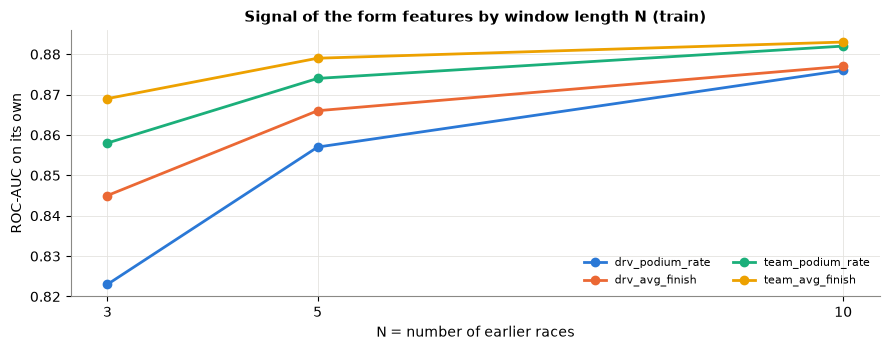

In [76]:
# compare form windows of 3, 5 and 10 races on the training seasons and keep the best (N_FORM)
fe["dnf"] = fe["status_group"].ne("finished").astype(float)
fe["mech_dnf"] = fe["status_group"].eq("mechanical").astype(float)
fe["podium_f"] = fe["podium"].astype(float)

# team-level table (one row per team per race), used for constructor form below
team_race = (fe.groupby(["constructorId", "constructor_stint", "raceId", "date"])
             .agg(team_podium=("podium_f", "mean"), team_finish=("positionOrder", "mean"),
                  team_mech=("mech_dnf", "mean")).reset_index().sort_values(["date", "raceId"]))

window_rows = []
for n in [3, 5, 10]:
    trial = fe[["driverId", "constructorId", "raceId", "period", "podium"]].copy()
    trial["drv_podium_rate"] = past_values(fe, ["driverId"], "podium_f", "rolling", n)
    trial["drv_avg_finish"] = past_values(fe, ["driverId"], "positionOrder", "rolling", n)
    tt = team_race.copy()
    tt["team_podium_rate"] = past_values(tt, ["constructorId", "constructor_stint"], "team_podium", "rolling", n)
    tt["team_avg_finish"] = past_values(tt, ["constructorId", "constructor_stint"], "team_finish", "rolling", n)
    trial = trial.merge(tt[["constructorId", "raceId", "team_podium_rate", "team_avg_finish"]],
                        on=["constructorId", "raceId"], how="left")
    for f in ["drv_podium_rate", "drv_avg_finish", "team_podium_rate", "team_avg_finish"]:
        for p in ["train", "validation"]:
            window_rows.append({"N": n, "feature": f, "period": p, "AUC": signal(trial[trial["period"] == p], f)[0]})
windows = pd.DataFrame(window_rows).pivot_table(index=["feature", "period"], columns="N", values="AUC")
display(windows)

train_mean = windows.xs("train", level="period").mean()
N_FORM = int(train_mean.idxmax())
print("mean training AUC per window:", train_mean.round(4).to_dict(), "→ chosen N_FORM =", N_FORM)

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, f in enumerate(["drv_podium_rate", "drv_avg_finish", "team_podium_rate", "team_avg_finish"]):
    ax.plot([3, 5, 10], windows.loc[(f, "train")], marker="o", markersize=6, color=PALETTE[i], label=f)
ax.set_xticks([3, 5, 10])
ax.set_title("Signal of the form features by window length N (train)")
ax.set_xlabel("N = number of earlier races")
ax.set_ylabel("ROC-AUC on its own")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
savefig(fig, "p5_form_window")
plt.show()

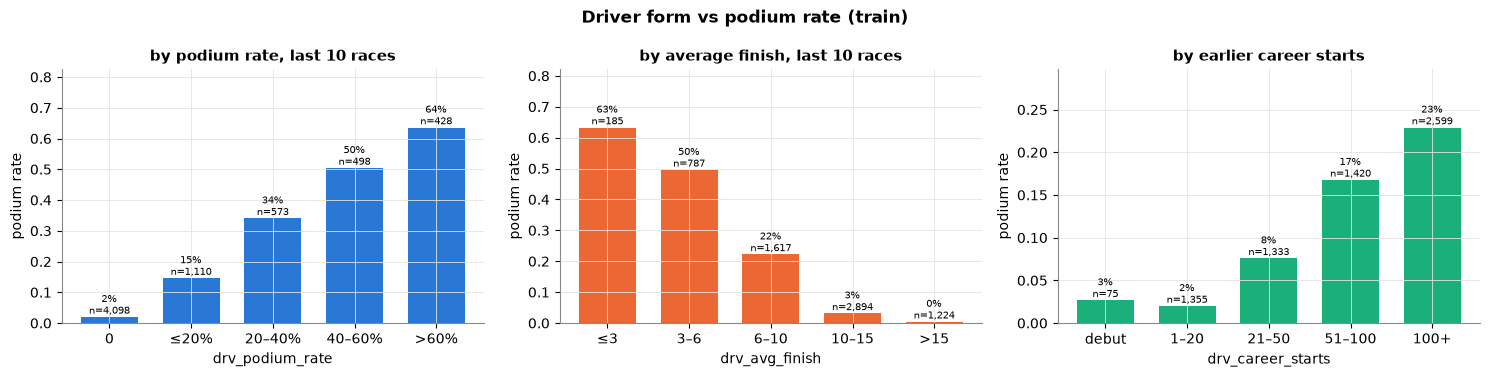

,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
drv_podium_rate,0.989,0.992,0.994,0.876,+,0.860
drv_avg_finish,0.989,0.992,0.994,0.877,−,0.878
drv_career_starts,1.000,1.000,1.000,0.690,+,0.702


In [77]:
# driver form over the last N_FORM races (strictly earlier races only) and career starts
fe["drv_podium_rate"] = past_values(fe, ["driverId"], "podium_f", "rolling", N_FORM)
fe["drv_avg_finish"] = past_values(fe, ["driverId"], "positionOrder", "rolling", N_FORM)
fe["drv_career_starts"] = fe.groupby("driverId").cumcount()                # earlier starts only (0 at debut)

tr = train_view()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
rate_plot(axes[0], tr, pd.cut(tr["drv_podium_rate"], [-0.01, 0, 0.2, 0.4, 0.6, 1.0], labels=["0", "≤20%", "20–40%", "40–60%", ">60%"]),
          f"by podium rate, last {N_FORM} races", "drv_podium_rate")
rate_plot(axes[1], tr, pd.cut(tr["drv_avg_finish"], [0, 3, 6, 10, 15, 40], labels=["≤3", "3–6", "6–10", "10–15", ">15"]),
          f"by average finish, last {N_FORM} races", "drv_avg_finish", PALETTE[1])
rate_plot(axes[2], tr, pd.cut(tr["drv_career_starts"], [-1, 0, 20, 50, 100, 400], labels=["debut", "1–20", "21–50", "51–100", "100+"]),
          "by earlier career starts", "drv_career_starts", PALETTE[2])
fig.suptitle("Driver form vs podium rate (train)", fontweight="bold")
fig.tight_layout()
savefig(fig, "p5_driver_form")
plt.show()
evidence(fe, ["drv_podium_rate", "drv_avg_finish", "drv_career_starts"])

**Hints.** Longer windows are better: N = 10 has the highest training AUC for all four form features (same order on
validation). 10 races ≈ half a season; season-long strength is covered by the standings (5.7). Debutants rarely reach
the podium.

### 5.5 Constructor form: `team_podium_rate`, `team_avg_finish`, `team_form_rank`, `team_races_history`

Team form over its last N races on the team-race table (both cars), per (`constructorId`, `constructor_stint`).
Renamed teams start with no history; `team_races_history` marks new teams. `team_form_rank` ranks the team's form
among the cars in this race.

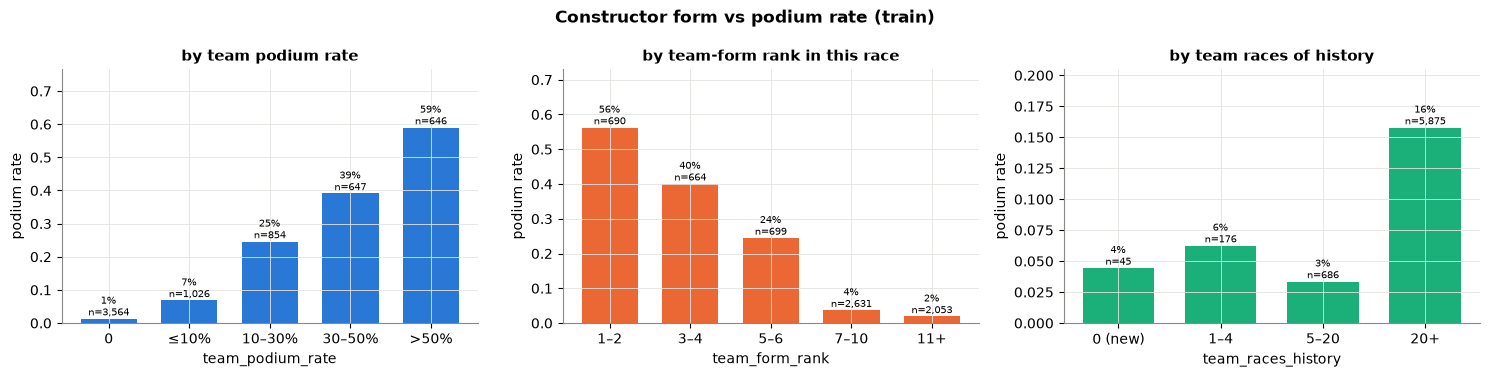

teams with <5 races of history that still reached the podium (2003+):


,,podiums
year,team,
2006,Honda,1
2009,Brawn,7
2010,Mercedes,2
2012,Lotus F1,3


,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
team_podium_rate,0.993,0.992,0.997,0.882,+,0.868
team_avg_finish,0.993,0.992,0.997,0.883,−,0.883
team_form_rank,0.993,0.992,0.997,0.863,−,0.878
team_races_history,1.000,1.000,1.000,0.669,+,0.613


In [78]:
# constructor form per (constructorId, stint) on the team-race table, merged back to every driver row
team_keys = ["constructorId", "constructor_stint"]
team_race["team_podium_rate"] = past_values(team_race, team_keys, "team_podium", "rolling", N_FORM)
team_race["team_avg_finish"] = past_values(team_race, team_keys, "team_finish", "rolling", N_FORM)
team_race["team_mech_dnf_rate"] = past_values(team_race, team_keys, "team_mech", "rolling", 10)   # used in 5.6
team_race["team_races_history"] = team_race.groupby(team_keys).cumcount()
fe = fe.merge(team_race[["constructorId", "raceId", "team_podium_rate", "team_avg_finish", "team_mech_dnf_rate",
                         "team_races_history"]], on=["constructorId", "raceId"], how="left", validate="many_to_one")
fe["team_form_rank"] = fe.groupby("raceId")["team_podium_rate"].rank(ascending=False, method="min")

tr = train_view()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
rate_plot(axes[0], tr, pd.cut(tr["team_podium_rate"], [-0.01, 0, 0.1, 0.3, 0.5, 1.0], labels=["0", "≤10%", "10–30%", "30–50%", ">50%"]),
          "by team podium rate", "team_podium_rate")
rate_plot(axes[1], tr, pd.cut(tr["team_form_rank"], [0, 2, 4, 6, 10, 30], labels=["1–2", "3–4", "5–6", "7–10", "11+"]),
          "by team-form rank in this race", "team_form_rank", PALETTE[1])
rate_plot(axes[2], tr, pd.cut(tr["team_races_history"], [-1, 0, 4, 20, 2000], labels=["0 (new)", "1–4", "5–20", "20+"]),
          "by team races of history", "team_races_history", PALETTE[2])
fig.suptitle("Constructor form vs podium rate (train)", fontweight="bold")
fig.tight_layout()
savefig(fig, "p5_constructor_form")
plt.show()

print("teams with <5 races of history that still reached the podium (2003+):")
new_team_podiums = fe[(fe["year"] >= 2003) & (fe["team_races_history"] < 5) & fe["podium"].eq(1)]
display(new_team_podiums.groupby(["year", "team"]).size().rename("podiums").to_frame())
evidence(fe, ["team_podium_rate", "team_avg_finish", "team_form_rank", "team_races_history"])

**Hints.** About as strong as the grid on its own (AUC ≈ 0.86–0.88). New teams rarely podium, with exceptions (Brawn
2009: 7 podiums with fewer than 5 races of history) → the history count is a separate column.

### 5.6 Reliability: `drv_dnf_rate_expanding`, `team_mech_dnf_rate`

The team's mechanical failures over its last 10 races; the driver's non-finish rate (crashes + failures) over his
whole career (more stable than a 5-race window, see 5.9).

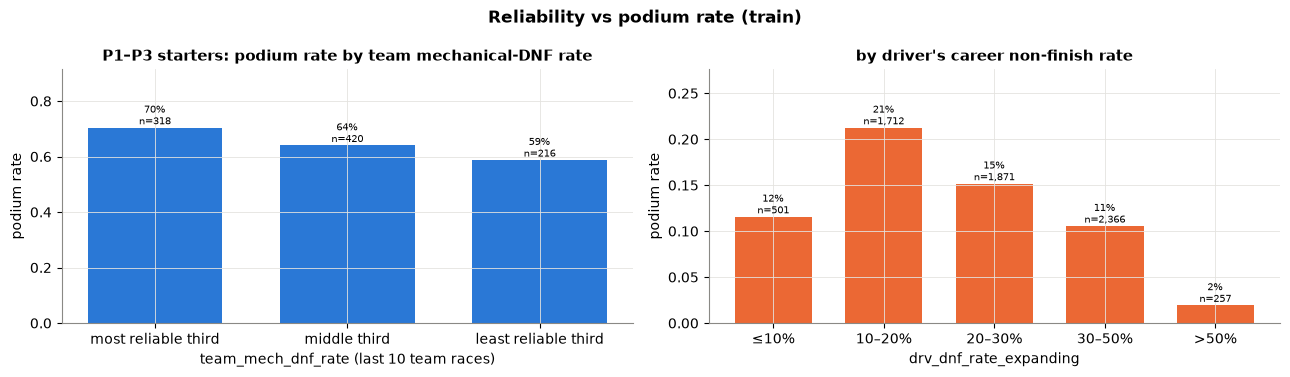

,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
drv_dnf_rate_expanding,0.989,0.992,0.994,0.599,−,0.604
team_mech_dnf_rate,0.993,0.992,0.997,0.652,−,0.564


In [79]:
# reliability: the driver's career non-finish rate and the team's mechanical-DNF rate
fe["drv_dnf_rate_expanding"] = past_values(fe, ["driverId"], "dnf", "expanding")

tr = train_view()
front = tr[tr["grid_pos"] <= 3]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
rate_plot(axes[0], front, pd.qcut(front["team_mech_dnf_rate"], 3, labels=["most reliable third", "middle third", "least reliable third"],
                                  duplicates="drop"),
          "P1–P3 starters: podium rate by team mechanical-DNF rate", "team_mech_dnf_rate (last 10 team races)")
rate_plot(axes[1], tr, pd.cut(tr["drv_dnf_rate_expanding"], [-0.01, 0.1, 0.2, 0.3, 0.5, 1.0], labels=["≤10%", "10–20%", "20–30%", "30–50%", ">50%"]),
          "by driver's career non-finish rate", "drv_dnf_rate_expanding", PALETTE[1])
fig.suptitle("Reliability vs podium rate (train)", fontweight="bold")
fig.tight_layout()
savefig(fig, "p5_reliability")
plt.show()
evidence(fe, ["drv_dnf_rate_expanding", "team_mech_dnf_rate"])

**Hints.** Among P1–P3 starters the least reliable teams convert less (70% → 59%). Drivers who often fail to finish
podium less (not a straight line: the ≤ 10% group is mostly drivers with few starts). Weak signals (AUC 0.60–0.65),
and the team signal weakens on validation → kept on probation for the ablation.

### 5.7 Championship standings before the race: `drv_pts_share`, `drv_champ_pos`, `team_pts_share`, `team_champ_pos`

The standings row of a race already **contains that race's result** (2014 opener check below), so standings are taken
**after the previous round** of the same season (round 1 = missing). Points are used as a **share of the leader's
points**, because the scoring changed.

,driverId,position,points,surname,positionOrder,points scored in this race
0,3,1,25.0,Rosberg,1,25.0
1,825,2,18.0,Magnussen,2,18.0
2,18,3,15.0,Button,3,15.0


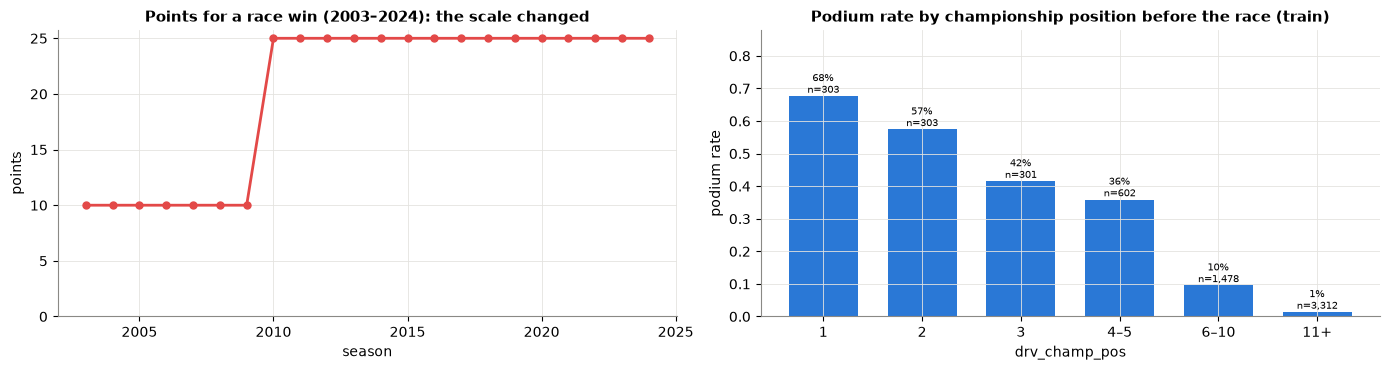

average raw driver points before a race (train): {'2003–09': 16.8, '2010–19': 46.5}


,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
drv_pts_share,0.929,0.945,0.950,0.891,+,0.890
drv_champ_pos,0.929,0.945,0.950,0.893,−,0.891
team_pts_share,0.943,0.948,0.956,0.893,+,0.875
team_champ_pos,0.943,0.948,0.956,0.867,−,0.882


In [80]:
# check first: is the standings row of race R the standings before or after race R? (2014 opener: all start at 0)
races_p = pd.read_csv(PROC_DIR / "races.csv")
standings_raw = pd.read_csv(PROC_DIR / "driver_standings.csv")
opener = races_p.loc[(races_p["year"] == 2014) & (races_p["round"] == 1), "raceId"].item()
display(standings_raw[standings_raw["raceId"] == opener].nsmallest(3, "position")[["driverId", "position", "points"]]
        .merge(fe.loc[fe["raceId"] == opener, ["driverId", "surname", "positionOrder", "points"]]
               .rename(columns={"points": "points scored in this race"}), on="driverId"))

races_p["prev_raceId"] = races_p.sort_values(["year", "round"]).groupby("year")["raceId"].shift(1)
fe = fe.merge(races_p[["raceId", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")

ds = pd.read_csv(PROC_DIR / "driver_standings.csv").rename(columns={"raceId": "prev_raceId"})
ds["drv_pts_share"] = ds["points"] / ds.groupby("prev_raceId")["points"].transform("max")
fe = fe.merge(ds[["prev_raceId", "driverId", "drv_pts_share", "position"]].rename(columns={"position": "drv_champ_pos"}),
              on=["prev_raceId", "driverId"], how="left", validate="many_to_one")
cs = pd.read_csv(PROC_DIR / "constructor_standings.csv").rename(columns={"raceId": "prev_raceId"})
cs["team_pts_share"] = cs["points"] / cs.groupby("prev_raceId")["points"].transform("max")
fe = fe.merge(cs[["prev_raceId", "constructorId", "team_pts_share", "position"]].rename(columns={"position": "team_champ_pos"}),
              on=["prev_raceId", "constructorId"], how="left", validate="many_to_one")

tr = train_view()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
win_pts = fe[(fe["positionOrder"] == 1) & (fe["year"] >= 2003)].groupby("year")["points"].median()
axes[0].plot(win_pts.index, win_pts.values, marker="o", markersize=5, color=PALETTE[7])
axes[0].set_title("Points for a race win (2003–2024): the scale changed")
axes[0].set_xlabel("season")
axes[0].set_ylabel("points")
axes[0].set_ylim(0, None)
rate_plot(axes[1], tr, pd.cut(tr["drv_champ_pos"], [0, 1, 2, 3, 5, 10, 40], labels=["1", "2", "3", "4–5", "6–10", "11+"]),
          "Podium rate by championship position before the race (train)", "drv_champ_pos")
fig.tight_layout()
savefig(fig, "p5_standings")
plt.show()
raw_points = tr.merge(ds[["prev_raceId", "driverId", "points"]].rename(columns={"points": "points_before"}),
                      on=["prev_raceId", "driverId"], how="left")
print("average raw driver points before a race (train):",
      raw_points.groupby(np.where(raw_points["year"] < 2010, "2003–09", "2010–19"))["points_before"].mean().round(1).to_dict())
evidence(fe, ["drv_pts_share", "drv_champ_pos", "team_pts_share", "team_champ_pos"])

**Hints.** A win was worth 10 points until 2009 and 25 after (50 at the 2014 finale) → raw points change meaning
(fails T3); the share and the position do not. The leader podiums most often and the rate falls with the position.
Among the strongest features (AUC ≈ 0.87–0.89). Missing at round 1 and for drivers / teams new in a season.

### 5.8 Circuit history and teammate comparison: `drv_circuit_podium_rate`, `grid_vs_teammate`

* `drv_circuit_podium_rate`: the driver's podium rate in all earlier visits to this circuit (missing on a first
  visit).
* `grid_vs_teammate`: grid slot minus the teammate's slot (negative = ahead; missing if the team does not have exactly
  two cars).

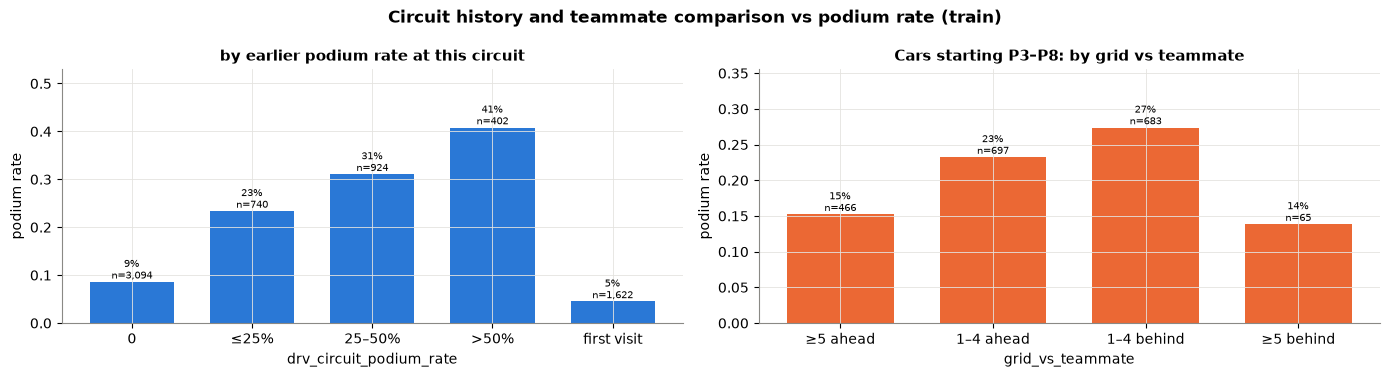

,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation
feature,,,,,,
drv_circuit_podium_rate,0.761,0.719,0.876,0.704,+,0.732
grid_vs_teammate,0.995,0.994,0.994,0.600,−,0.634


In [81]:
# circuit history (earlier visits only) and the grid gap to the team-mate
fe["drv_circuit_podium_rate"] = past_values(fe, ["driverId", "circuitId"], "podium_f", "expanding")
cars = fe.groupby(["raceId", "constructorId"])["grid_pos"].transform("size")
teammate_grid = fe.groupby(["raceId", "constructorId"])["grid_pos"].transform("sum") - fe["grid_pos"]
fe["grid_vs_teammate"] = np.where(cars == 2, fe["grid_pos"] - teammate_grid, np.nan)

tr = train_view()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
circ = pd.cut(tr["drv_circuit_podium_rate"], [-0.01, 0, 0.25, 0.5, 1.0], labels=["0", "≤25%", "25–50%", ">50%"]) \
    .cat.add_categories("first visit").fillna("first visit")
rate_plot(axes[0], tr, circ, "by earlier podium rate at this circuit", "drv_circuit_podium_rate")
team_mid = tr[tr["grid_pos"].between(3, 8)]
rate_plot(axes[1], team_mid, pd.cut(team_mid["grid_vs_teammate"], [-30, -5, -1, 4, 30], labels=["≥5 ahead", "1–4 ahead", "1–4 behind", "≥5 behind"]),
          "Cars starting P3–P8: by grid vs teammate", "grid_vs_teammate", PALETTE[1])
fig.suptitle("Circuit history and teammate comparison vs podium rate (train)", fontweight="bold")
fig.tight_layout()
savefig(fig, "p5_circuit_teammate")
plt.show()
evidence(fe, ["drv_circuit_podium_rate", "grid_vs_teammate"])

**Hints.** Earlier podiums at a circuit → much more likely again; first visits sit near the bottom. The teammate gap
is not linear: P3–P8 starters 1–4 places *behind* their teammate convert most (27%), 5+ places *ahead* only 15% (a
teammate far behind means a slow car). Circuit history has the most missing values → imputer + missing indicator.

### 5.9 Rejected candidates (kept as evidence)

Built the same way; each fails at least one test.

In [82]:
# build the rejected candidates the same way and report the test each one fails
fe["year_feature"] = fe["year"]
nationality_of = pd.read_csv(PROC_DIR / "drivers.csv").set_index("driverId")["nationality"]
country_of = pd.read_csv(PROC_DIR / "circuits.csv").set_index("circuitId")["country"]
fe["home_race"] = [float(c in NATIONALITY_TO_COUNTRIES.get(n, [])) for n, c in
                   zip(fe["driverId"].map(nationality_of), fe["circuitId"].map(country_of))]      # D8, as in Q2
fe["front_row"] = fe["grid_pos"].le(2).astype(float)
fe["pit_lane_start"] = fe["pitlane_start"].astype(float)
fe["reached_q3"] = np.where(fe["year"] >= 2006, fe["quali_position"].le(10), np.nan)
fe["drv_dnf_rate_last5"] = past_values(fe, ["driverId"], "dnf", "rolling", 5)
fe = fe.merge(ds[["prev_raceId", "driverId", "points"]].rename(columns={"points": "drv_points_raw"}),
              on=["prev_raceId", "driverId"], how="left", validate="many_to_one")

REJECTED = {
    "drv_points_raw": "T3 — scoring changed in 2010 (10 → 25 per win): raw points change meaning; replaced by the share",
    "year_feature": "T2 — no signal; T3 — test seasons lie outside the training range",
    "round": "T2 — no signal; round 1 is already covered by missing standings",
    "field_size": "T2 — no signal; field size hardly varies after 2003",
    "home_race": "T2 — no signal on its own (Q2 finds no home effect once the grid is controlled, 4.2)",
    "front_row": "redundant — a cut-off of grid_pos",
    "pit_lane_start": "T2 — no signal on its own; already inside grid_pos (back of the grid); kept in base (D5) only",
    "reached_q3": "T3 — undefined in 2003–05 (no Q3), so coverage differs between train and test",
    "drv_dnf_rate_last5": "T3 — unstable: signal drops on validation; the career rate replaces it",
}
rejected = evidence(fe, list(REJECTED)).assign(reason=pd.Series(REJECTED))
rejected

,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation,reason
feature,,,,,,,
drv_points_raw,0.929,0.945,0.950,0.831,+,0.830,T3 — scoring changed in 2010 (10 → 25 per win)...
year_feature,1.000,1.000,1.000,0.501,+,0.500,T2 — no signal; T3 — test seasons lie outside ...
round,1.000,1.000,1.000,0.501,−,0.500,T2 — no signal; round 1 is already covered by ...
field_size,1.000,1.000,1.000,0.524,−,0.503,T2 — no signal; field size hardly varies after...
home_race,1.000,1.000,1.000,0.503,+,0.506,T2 — no signal on its own (Q2 finds no home ef...
front_row,1.000,1.000,1.000,0.722,+,0.733,redundant — a cut-off of grid_pos
pit_lane_start,1.000,1.000,1.000,0.502,−,0.512,T2 — no signal on its own; already inside grid...
reached_q3,0.847,1.000,1.000,0.785,+,0.769,"T3 — undefined in 2003–05 (no Q3), so coverage..."
drv_dnf_rate_last5,0.989,0.992,0.994,0.627,−,0.541,T3 — unstable: signal drops on validation; the...


### 5.10 Leakage checks

1. **First appearance:** where no earlier race exists (first career race, a team's first race, round 1, first visit
   to a circuit), the history feature must be missing.
2. **Recompute by hand:** 25 random rows recomputed with plain "earlier races only" filters.
3. **No forbidden column:** no current-race outcome column is a feature.

In [83]:
# the 18 selected features, and leakage check 1: no history where no earlier race exists
FEATURES = ["grid_pos", "grid_penalty", "q1_gap_pct",
            "drv_podium_rate", "drv_avg_finish", "drv_career_starts",
            "team_podium_rate", "team_avg_finish", "team_form_rank", "team_races_history",
            "drv_dnf_rate_expanding", "team_mech_dnf_rate",
            "drv_pts_share", "drv_champ_pos", "team_pts_share", "team_champ_pos",
            "drv_circuit_podium_rate", "grid_vs_teammate"]

# check 1: first appearances have no history
first_driver = fe.groupby("driverId").head(1)
first_team = fe.sort_values("date").groupby(["constructorId", "constructor_stint"]).head(1)
first_visit = fe.groupby(["driverId", "circuitId"]).head(1)
round_one = fe[fe["round"] == 1]
checks = {
    "driver's first race → driver form missing": first_driver[["drv_podium_rate", "drv_avg_finish", "drv_dnf_rate_expanding"]].isna().all().all(),
    "driver's first race → 0 career starts": first_driver["drv_career_starts"].eq(0).all(),
    "team's first race → team form missing": first_team[["team_podium_rate", "team_avg_finish", "team_mech_dnf_rate"]].isna().all().all(),
    "round 1 → standings missing": round_one[["drv_pts_share", "drv_champ_pos", "team_pts_share", "team_champ_pos"]].isna().all().all(),
    "first visit to a circuit → circuit history missing": first_visit["drv_circuit_podium_rate"].isna().all(),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

,passed
driver's first race → driver form missing,True
driver's first race → 0 career starts,True
team's first race → team form missing,True
round 1 → standings missing,True
first visit to a circuit → circuit history missing,True


In [84]:
# check 2: recompute 25 random modelling rows with plain filters
sample = fe[fe["year"] >= 2003].sample(25, random_state=SEED)
mismatches = []
for _, row in sample.iterrows():
    before = fe[fe["date"] < row["date"]]
    mine = before[before["driverId"] == row["driverId"]]
    team = team_race[(team_race["constructorId"] == row["constructorId"])
                     & (team_race["constructor_stint"] == row["constructor_stint"]) & (team_race["date"] < row["date"])]
    here = mine[mine["circuitId"] == row["circuitId"]]
    prev_standing = ds[(ds["prev_raceId"] == row["prev_raceId"]) & (ds["driverId"] == row["driverId"])]
    expected = {
        "drv_podium_rate": mine["podium_f"].tail(N_FORM).mean(),
        "drv_avg_finish": mine["positionOrder"].tail(N_FORM).mean(),
        "drv_career_starts": len(mine),
        "drv_dnf_rate_expanding": mine["dnf"].mean(),
        "team_podium_rate": team["team_podium"].tail(N_FORM).mean(),
        "team_mech_dnf_rate": team["team_mech"].tail(10).mean(),
        "drv_circuit_podium_rate": here["podium_f"].mean(),
        "drv_pts_share": prev_standing["drv_pts_share"].iat[0] if len(prev_standing) else np.nan,
    }
    for f, value in expected.items():
        if not np.isclose(value, row[f], equal_nan=True):
            mismatches.append((row["raceId"], row["driverId"], f, value, row[f]))
print(f"recomputed {len(sample)} rows × {len(expected)} features: {len(mismatches)} mismatches")
assert not mismatches, mismatches

# check 3: no current-race outcome among the features
FORBIDDEN = ["positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status", "status_group", "podium"]
assert not set(FEATURES) & set(FORBIDDEN)
print("checks passed: no history feature sees the current race; no outcome column is a feature")

recomputed 25 rows × 8 features: 0 mismatches
checks passed: no history feature sees the current race; no outcome column is a feature


**Hints.** All three checks pass (0 mismatches on 25 rows × 8 features).

### 5.11 The selected features together

The 18 features side by side: evidence (T1–T3), missing values per period, and correlations.

In [85]:
# the 7 feature groups and the evidence table of the selected features
GROUPS = {"grid": ["grid_pos", "grid_penalty"], "qualifying": ["q1_gap_pct"],
          "driver form": ["drv_podium_rate", "drv_avg_finish", "drv_career_starts"],
          "constructor form": ["team_podium_rate", "team_avg_finish", "team_form_rank", "team_races_history"],
          "reliability": ["drv_dnf_rate_expanding", "team_mech_dnf_rate"],
          "standings": ["drv_pts_share", "drv_champ_pos", "team_pts_share", "team_champ_pos"],
          "circuit & teammate": ["drv_circuit_podium_rate", "grid_vs_teammate"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)
feature_group = {f: g for g, fs in GROUPS.items() for f in fs}
selected = evidence(fe, FEATURES).assign(group=pd.Series(feature_group))
selected

,coverage train,coverage validation,coverage test,AUC train,direction,AUC validation,group
feature,,,,,,,
grid_pos,1.000,1.000,1.000,0.909,−,0.910,grid
grid_penalty,0.997,0.999,1.000,0.556,+,0.539,grid
q1_gap_pct,0.982,0.988,0.990,0.831,−,0.842,qualifying
drv_podium_rate,0.989,0.992,0.994,0.876,+,0.860,driver form
drv_avg_finish,0.989,0.992,0.994,0.877,−,0.878,driver form
drv_career_starts,1.000,1.000,1.000,0.690,+,0.702,driver form
team_podium_rate,0.993,0.992,0.997,0.882,+,0.868,constructor form
team_avg_finish,0.993,0.992,0.997,0.883,−,0.883,constructor form
team_form_rank,0.993,0.992,0.997,0.863,−,0.878,constructor form


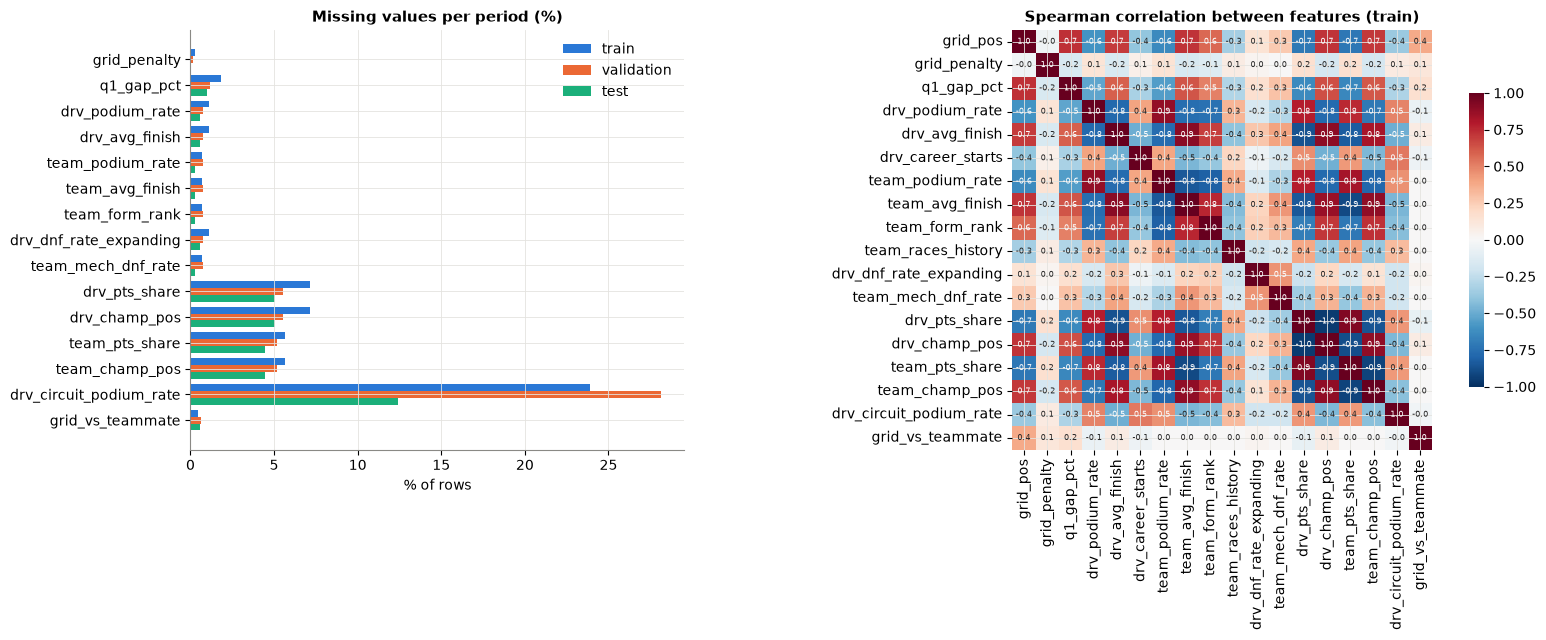

spearman
drv_pts_share   drv_champ_pos    -0.954670
                team_pts_share    0.928978
team_pts_share  team_champ_pos   -0.923943
drv_avg_finish  team_avg_finish   0.901350
team_avg_finish team_pts_share   -0.900810
drv_avg_finish  drv_champ_pos     0.891144
drv_champ_pos   team_pts_share   -0.889758
team_avg_finish team_champ_pos    0.888556
drv_champ_pos   team_champ_pos    0.883563
drv_podium_rate team_podium_rate  0.877646
drv_avg_finish  drv_pts_share    -0.871213
team_avg_finish drv_champ_pos     0.864910
drv_pts_share   team_champ_pos   -0.862657

In [86]:
# missing values per period and the correlation between the selected features (train)
model_rows = fe[fe["year"] >= 2003]
missing = pd.DataFrame({p: model_rows.loc[model_rows["period"] == p, FEATURES].isna().mean() * 100 for p in PERIODS})
corr = model_rows.loc[model_rows["period"] == "train", FEATURES].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.5]})
m = missing[missing.max(axis=1) > 0].iloc[::-1]
y = np.arange(len(m))
for i, p in enumerate(PERIODS):
    axes[0].barh(y + (1 - i) * 0.27, m[p], height=0.27, color=PALETTE[i], label=p)
axes[0].set_yticks(y, m.index)
axes[0].set_title("Missing values per period (%)")
axes[0].set_xlabel("% of rows")
axes[0].legend()
sns.heatmap(corr, ax=axes[1], cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, cbar_kws={"shrink": 0.7},
            annot=True, fmt=".1f", annot_kws={"fontsize": 6})
axes[1].set_title("Spearman correlation between features (train)")
fig.tight_layout()
savefig(fig, "p5_missing_correlation")
plt.show()

strong_pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
display(strong_pairs[strong_pairs.abs() >= 0.85].sort_values(key=abs, ascending=False).rename("spearman").to_frame())

**Hints.**
* Missing values are structural (round 1, first visits, debutants, new team IDs) and similar across periods, except
  circuit history (24% train, 28% validation, 12% test: the 2020–21 COVID calendar had many one-off circuits).
  Imputation is done inside the pipeline (Phase 6).
* Strong correlations (points share vs championship position, team podium rate vs average finish) describe the same
  strength from different angles. Fine for trees; logistic regression is regularised; the ablation (T4) decides.

### 5.12 Save the modelling table

In [87]:
# keep the modelling rows (2003+), the ids, the features and the target; check and save the table
ID_COLUMNS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "period"]
model_table = fe.loc[fe["year"] >= 2003, ID_COLUMNS + FEATURES + ["podium"]].copy()
model_table["podium"] = model_table["podium"].astype(int)
model_table["period"] = model_table["period"].astype(str)

assert not model_table.duplicated(["raceId", "driverId"]).any(), "one row per driver per race"
assert model_table.groupby("raceId")["podium"].sum().eq(3).all(), "three podium rows per race"
model_table.to_csv(PROC_DIR / "model_table.csv", index=False)

summary = model_table.groupby("period", sort=False).agg(rows=("podium", "size"), races=("raceId", "nunique"),
                                                        podium_rate=("podium", "mean")).round(3)
print(f"saved data/processed/model_table.csv: {len(model_table):,} rows × {len(FEATURES)} features")
summary

saved data/processed/model_table.csv: 8,909 rows × 18 features


,rows,races,podium_rate
period,,,
train,6782,321,0.142
validation,775,39,0.151
test,1352,68,0.151


**Result.** 8,909 rows (2003–2024), 18 leakage-checked features in 7 groups, the target `podium`, and `period`
for the split. Podium rate ~15% in every period.

## 6. Time-based split and preprocessing pipelines

How the data is split, and where the preprocessing learns its numbers, decides whether the scores are honest.

### 6.1 Why a time-based split, not a random one

| Set | Seasons | Used for |
|---|---|---|
| train | 2003–2019 | fitting models and preprocessing |
| validation | 2020–2021 | choosing hyperparameters and the decision threshold |
| test | 2022–2024 | one final, unseen evaluation |

A deployed model always predicts a race that happens *after* everything it learned from. A random split would put
cars of the same race on both sides and let later seasons help predict earlier ones (measured below). The test
seasons are also a new technical era (2022 ground-effect cars), which tests era sensitivity honestly.

random split: 100% of the held-out rows come from a race that also has rows in training; 94% of them are older than the newest training rows (the model would learn from the future)


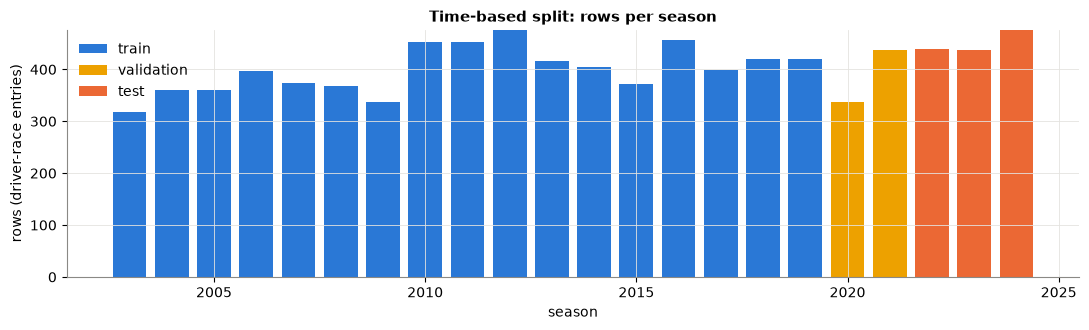

In [88]:
# what a random split would do (same races on both sides, future seasons in training) vs the time split
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

mt = pd.read_csv(PROC_DIR / "model_table.csv", parse_dates=["date"])
assert set(FEATURES) <= set(mt.columns)

# what a random 70/15/15 split would do
rand_train, rand_rest = train_test_split(mt, test_size=0.3, random_state=SEED)
shared = rand_rest["raceId"].isin(rand_train["raceId"]).mean()
later_years = (rand_rest["year"] < rand_train["year"].max()).mean()
print(f"random split: {shared:.0%} of the held-out rows come from a race that also has rows in training; "
      f"{later_years:.0%} of them are older than the newest training rows (the model would learn from the future)")

rows_per_year = mt.groupby(["year", "period"]).size().unstack(fill_value=0)[PERIODS]
fig, ax = plt.subplots(figsize=(11, 3.4))
bottom = np.zeros(len(rows_per_year))
for p, color in zip(PERIODS, [PALETTE[0], PALETTE[3], PALETTE[1]]):
    ax.bar(rows_per_year.index, rows_per_year[p], bottom=bottom, color=color, label=p, width=0.8)
    bottom += rows_per_year[p].values
ax.set_title("Time-based split: rows per season")
ax.set_xlabel("season")
ax.set_ylabel("rows (driver-race entries)")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "p6_time_split")
plt.show()

**Hints.** Random split: 100% of held-out rows share a race with training rows, and 94% are older than the newest
training rows. The time split has neither problem. Validation is small (39 races) but is only used to choose settings.

### 6.2 The three sets

In [89]:
# the three sets, checked to be disjoint in time and in races
sets = {p: mt[mt["period"] == p] for p in PERIODS}
X = {p: d[FEATURES] for p, d in sets.items()}
y = {p: d["podium"] for p, d in sets.items()}

# the sets must be disjoint in time and in races
assert sets["train"]["date"].max() < sets["validation"]["date"].min() <= sets["validation"]["date"].max() < sets["test"]["date"].min()
assert not set(sets["train"]["raceId"]) & set(sets["validation"]["raceId"])
assert not set(sets["validation"]["raceId"]) & set(sets["test"]["raceId"])

split_summary = pd.DataFrame({
    "seasons": {p: f"{d['year'].min()}–{d['year'].max()}" for p, d in sets.items()},
    "races": {p: d["raceId"].nunique() for p, d in sets.items()},
    "rows": {p: len(d) for p, d in sets.items()},
    "podiums": {p: int(d["podium"].sum()) for p, d in sets.items()},
    "podium rate": {p: round(d["podium"].mean(), 3) for p, d in sets.items()},
})
split_summary

,seasons,races,rows,podiums,podium rate
train,2003–2019,321,6782,963,0.142
validation,2020–2021,39,775,117,0.151
test,2022–2024,68,1352,204,0.151


**Hints.** The sets do not overlap in time or races. The podium rate is ~14–15% everywhere, which is also the PR-AUC
of a random model (~0.15).

### 6.3 Missing values: impute, and keep the information that a value was missing

Most gaps are structural (round 1, first visit, debutant). Is missingness itself related to the podium? (training
seasons)

,missing rows,podium rate when missing,podium rate when present
grid_penalty,20,0.000,0.142
q1_gap_pct,122,0.049,0.144
drv_podium_rate,75,0.027,0.143
drv_avg_finish,75,0.027,0.143
team_podium_rate,45,0.044,0.143
team_avg_finish,45,0.044,0.143
team_form_rank,45,0.044,0.143
drv_dnf_rate_expanding,75,0.027,0.143
team_mech_dnf_rate,45,0.044,0.143
drv_pts_share,483,0.118,0.144


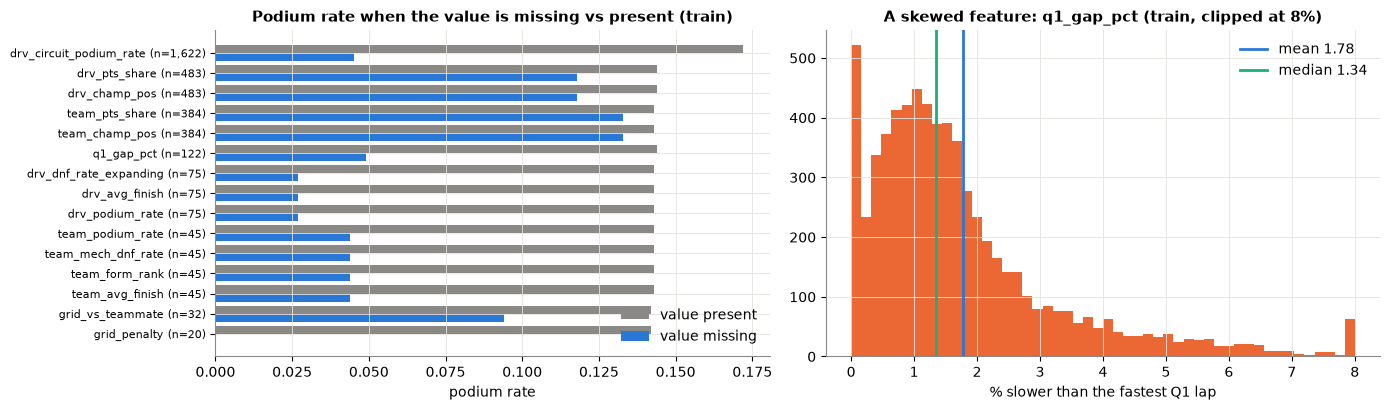

,grid_penalty,q1_gap_pct,drv_podium_rate,team_mech_dnf_rate,drv_circuit_podium_rate,team_podium_rate
skewness (train),4.77,4.13,1.7,1.65,1.6,1.57


In [90]:
# is a missing value informative? podium rate when missing vs present (train), and the skew of the features
miss_cols = [f for f in FEATURES if X["train"][f].isna().any()]
informative = pd.DataFrame({
    "missing rows": X["train"][miss_cols].isna().sum(),
    "podium rate when missing": {f: y["train"][X["train"][f].isna()].mean() for f in miss_cols},
    "podium rate when present": {f: y["train"][X["train"][f].notna()].mean() for f in miss_cols},
}).round(3)
display(informative)

skew = X["train"].skew().round(2).rename("skewness (train)")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
t = informative.sort_values("missing rows")
yy = np.arange(len(t))
axes[0].barh(yy + 0.2, t["podium rate when present"], height=0.4, color=GREY, label="value present")
axes[0].barh(yy - 0.2, t["podium rate when missing"], height=0.4, color=PALETTE[0], label="value missing")
axes[0].set_yticks(yy, [f"{f} (n={int(n):,})" for f, n in zip(t.index, t["missing rows"])], fontsize=8)
axes[0].set_title("Podium rate when the value is missing vs present (train)")
axes[0].set_xlabel("podium rate")
axes[0].legend(loc="lower right")
gap_train = X["train"]["q1_gap_pct"].dropna()
axes[1].hist(gap_train.clip(upper=8), bins=50, color=PALETTE[1])
axes[1].axvline(gap_train.mean(), color=PALETTE[0], linewidth=2, label=f"mean {gap_train.mean():.2f}")
axes[1].axvline(gap_train.median(), color=PALETTE[2], linewidth=2, label=f"median {gap_train.median():.2f}")
axes[1].set_title("A skewed feature: q1_gap_pct (train, clipped at 8%)")
axes[1].set_xlabel("% slower than the fastest Q1 lap")
axes[1].legend()
fig.tight_layout()
savefig(fig, "p6_missingness_skew")
plt.show()
skew.sort_values(key=abs, ascending=False).head(6).to_frame().T

**Hints.** The podium rate differs between missing and present rows (e.g. first visit 4.5% vs 17.2%) → keep a *was
missing* flag. Several features are strongly skewed (`grid_penalty`, `q1_gap_pct`: skewness above 4).

**Pipeline:** median imputation (robust to skew) + `add_indicator=True` (a 0/1 *was missing* column for every feature
with gaps in training).

### 6.4 Scaling and encoding

* `StandardScaler` for the **logistic regression** (equal regularisation of all weights, faster solver) and the
  **neural network** (gradient descent); trees do not need it.
* No encoder: every feature is numeric. `driverId` / `constructorId` are not one-hot encoded (the model would memorise
  names and fail on new drivers and teams, shown below).

In [91]:
# the preprocessing pipeline (median imputation + missing indicators [+ scaling]), and drivers/teams unseen in training
def make_preprocessor(scale):
    """Imputation (+ missing indicators), optionally followed by standard scaling. Fitted inside each model pipeline."""
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps)


# evidence against one-hot IDs: how many drivers / teams in later seasons never appear in training?
unseen = pd.DataFrame({
    p: {"drivers not in train": len(set(sets[p]["driverId"]) - set(sets["train"]["driverId"])),
        "constructorIds not in train": len(set(sets[p]["constructorId"]) - set(sets["train"]["constructorId"])),
        "rows affected": int((~sets[p]["driverId"].isin(sets["train"]["driverId"])
                              | ~sets[p]["constructorId"].isin(sets["train"]["constructorId"])).sum())}
    for p in ["validation", "test"]})
unseen

,validation,test
drivers not in train,6,11
constructorIds not in train,3,4
rows affected,250,611


**Hints.** 11 drivers and 4 constructor IDs of the test seasons never appear in training: 611 of the 1,352 test rows
(45%).

### 6.5 Fitted on the training seasons only

Inside a `Pipeline`, `fit` sees only the training rows; validation and test rows are only transformed with the
training numbers (order experiment 2 in Phase 8 measures the alternative).

In [92]:
# fit the pipelines on train only, check the learned numbers, and look at the scaled values per set
prep_linear = make_preprocessor(scale=True).fit(X["train"])
prep_tree = make_preprocessor(scale=False).fit(X["train"])
out_names = prep_linear.get_feature_names_out()
indicators = [c for c in out_names if c.startswith("missingindicator_")]
print(f"inputs: {len(FEATURES)} features → outputs: {len(out_names)} columns ({len(indicators)} missing indicators)")
print("indicator columns:", [c.replace("missingindicator_", "") for c in indicators])

# check: the learned numbers are the training numbers
imputer = prep_linear.named_steps["impute"]
assert np.allclose(imputer.statistics_, X["train"].median(), equal_nan=True)
Z = {p: pd.DataFrame(prep_linear.transform(X[p]), columns=out_names, index=X[p].index) for p in PERIODS}
assert all(not Z[p].isna().any().any() for p in PERIODS), "no missing values after preprocessing"

scaled_stats = pd.DataFrame({p: Z[p][FEATURES].mean() for p in PERIODS}).round(2)
scaled_stats.columns = [f"mean after scaling: {p}" for p in PERIODS]
scaled_stats["std after scaling: train"] = Z["train"][FEATURES].std().round(2)
display(scaled_stats.head(8))
print("imputation medians learned on train (first 6):",
      {f: round(float(v), 3) for f, v in zip(FEATURES[:6], imputer.statistics_[:6])})

inputs: 18 features → outputs: 33 columns (15 missing indicators)
indicator columns: ['grid_penalty', 'q1_gap_pct', 'drv_podium_rate', 'drv_avg_finish', 'team_podium_rate', 'team_avg_finish', 'team_form_rank', 'drv_dnf_rate_expanding', 'team_mech_dnf_rate', 'drv_pts_share', 'drv_champ_pos', 'team_pts_share', 'team_champ_pos', 'drv_circuit_podium_rate', 'grid_vs_teammate']


,mean after scaling: train,mean after scaling: validation,mean after scaling: test,std after scaling: train
grid_pos,-0.0,-0.10,-0.11,1.0
grid_penalty,0.0,0.04,0.01,1.0
q1_gap_pct,0.0,-0.20,-0.39,1.0
drv_podium_rate,0.0,0.04,0.04,1.0
drv_avg_finish,0.0,-0.14,-0.17,1.0
drv_career_starts,0.0,0.35,0.67,1.0
team_podium_rate,-0.0,0.01,0.04,1.0
team_avg_finish,0.0,-0.14,-0.16,1.0


imputation medians learned on train (first 6): {'grid_pos': 11.0, 'grid_penalty': 0.0, 'q1_gap_pct': 1.342, 'drv_podium_rate': 0.0, 'drv_avg_finish': 11.4, 'drv_career_starts': 70.0}


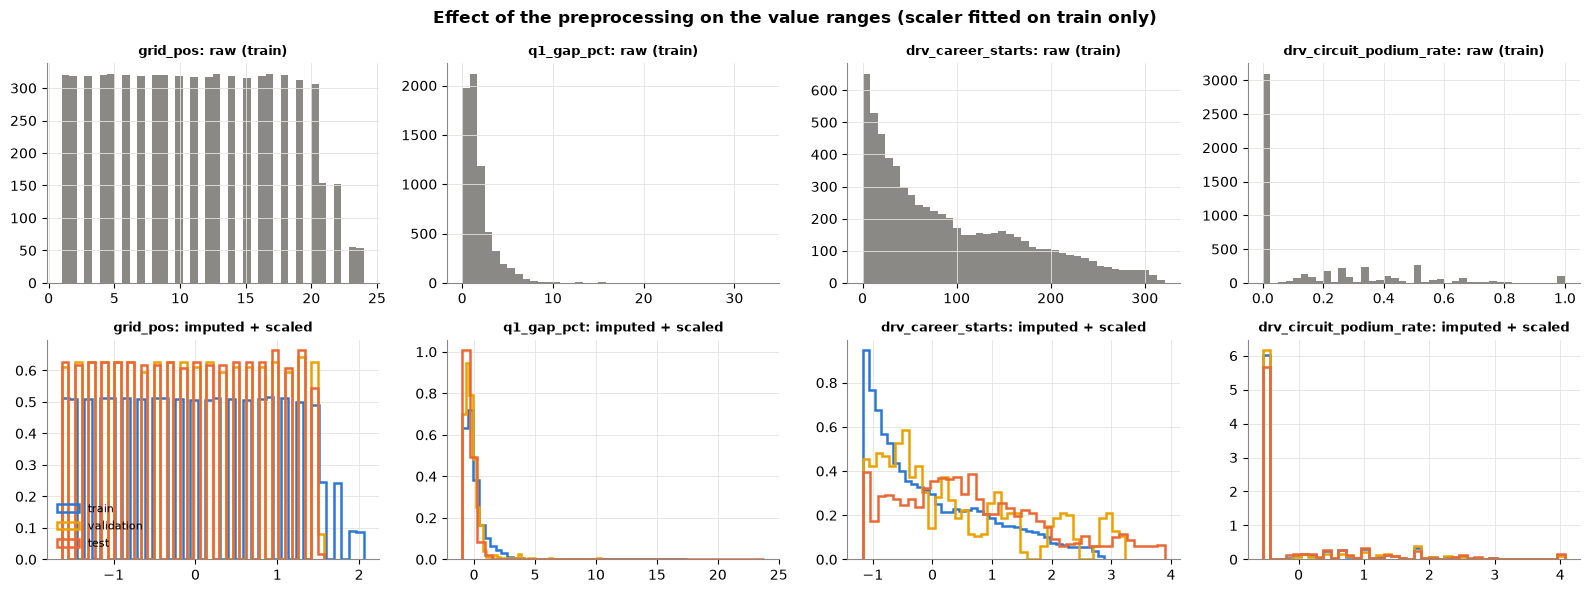

In [93]:
# effect of the preprocessing on the value ranges (raw vs imputed + scaled)
show_features = ["grid_pos", "q1_gap_pct", "drv_career_starts", "drv_circuit_podium_rate"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, f in enumerate(show_features):
    axes[0, j].hist(X["train"][f].dropna(), bins=40, color=GREY)
    axes[0, j].set_title(f"{f}: raw (train)", fontsize=9)
    for p, color in zip(PERIODS, [PALETTE[0], PALETTE[3], PALETTE[1]]):
        axes[1, j].hist(Z[p][f], bins=40, histtype="step", density=True, linewidth=1.8, color=color, label=p)
    axes[1, j].set_title(f"{f}: imputed + scaled", fontsize=9)
axes[1, 0].legend(fontsize=8)
fig.suptitle("Effect of the preprocessing on the value ranges (scaler fitted on train only)", fontweight="bold")
fig.tight_layout()
savefig(fig, "p6_preprocessing_effect")
plt.show()

**Hints.**
* 18 features → 33 columns (15 missing indicators); no NaN left in any set.
* Train: mean 0, std 1. Validation and test means differ because they use the training numbers: the test grid is more
  experienced (`drv_career_starts` +0.67 SD) and closer in qualifying (`q1_gap_pct` −0.39 SD).
* Scaling changes the range, not the shape (the skew and the spike of imputed medians stay).

Each model is `Pipeline([("prep", make_preprocessor(...)), ("model", ...)])`, fitted on `X["train"]`; settings and
threshold are chosen on `X["validation"]`; `X["test"]` is used once (7.6).

## 7. Models

Same rows (train 2003–2019) and same 18 features for every model; each model is a `Pipeline(preprocessing → model)`.

### 7.0 Metrics and evaluation rules

| Metric | What it measures | Role |
|---|---|---|
| **PR-AUC** (average precision) | how well podium finishers are ranked above the rest, focusing on the positive class | **primary** |
| **ROC-AUC** | how well the two classes are separated overall | **secondary** |
| F1, precision, recall | quality of the yes/no decision at a chosen probability threshold | reported for every model |

**PR-AUC first:** podiums are rare (~15%), and ROC-AUC also rewards ranking the many easy negatives (a car starting
18th), so it looks high even for mediocre models. A random model scores PR-AUC ≈ 0.15 but ROC-AUC 0.5.
**ROC-AUC second:** threshold-free, shows the overall separation.

*Brief:* the metric table lists three metrics but the deliverables ask for "all five" → **precision and recall** (the
two parts of F1) are added.

**Rules:**
* hyperparameters chosen by **validation PR-AUC**;
* threshold = best **F1 on validation**;
* each attempt shows train and validation only; test is computed once (7.6); no refit on train + validation.

In [94]:
# metrics, threshold rule (best F1 on validation), a register of all attempts and a tuning helper
import copy
import torch
from torch import nn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import ParameterGrid

torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)


def best_f1_threshold(y_true, proba):
    """Threshold that maximises F1 (used on validation only)."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])


def metrics(y_true, proba, threshold):
    decision = proba >= threshold
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "F1": f1_score(y_true, decision), "precision": precision_score(y_true, decision, zero_division=0),
            "recall": recall_score(y_true, decision)}


ATTEMPTS = {}   # name -> probabilities per set, threshold, fitted model


def register(name, predict_proba, model=None, threshold=None):
    """Score a model on every set; the threshold comes from validation. Shows train + validation only."""
    proba = {p: np.asarray(predict_proba(X[p])) for p in PERIODS}
    if threshold is None:
        threshold = best_f1_threshold(y["validation"], proba["validation"])
    table = pd.DataFrame({p: metrics(y[p], proba[p], threshold) for p in PERIODS}).T
    ATTEMPTS[name] = {"proba": proba, "threshold": threshold, "model": model, "table": table}
    print(f"{name}  (threshold {threshold:.3f}, chosen on validation)")
    return table.loc[["train", "validation"]].round(3)


def tune(build, grid):
    """Fit one pipeline per setting on train; rank the settings by validation PR-AUC."""
    rows = []
    for params in ParameterGrid(grid):
        model = build(**params).fit(X["train"], y["train"])
        rows.append({**params,
                     "PR-AUC train": average_precision_score(y["train"], model.predict_proba(X["train"])[:, 1]),
                     "PR-AUC validation": average_precision_score(y["validation"], model.predict_proba(X["validation"])[:, 1])})
    table = pd.DataFrame(rows).sort_values("PR-AUC validation", ascending=False).reset_index(drop=True)
    best = {k: (None if pd.isna(v) else v) for k, v in table.iloc[0][list(grid)].items()}
    return table.round(4), best

### 7.1 Reference rule: "predict a podium if `grid ≤ 3`"

The simplest rule; every model has to beat it. Score = `1 / grid_pos`, threshold fixed at grid 3.

In [95]:
# the reference rule: predict a podium for the three cars at the front of the grid
register("rule: grid ≤ 3", lambda d: 1 / d["grid_pos"], threshold=1 / 3)

rule: grid ≤ 3  (threshold 0.333, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.909,0.628,0.648,0.649,0.646
validation,0.910,0.648,0.695,0.698,0.692


**Hints.** The front three reach the podium ~2/3 of the time (precision) and take ~2/3 of all podiums (recall);
ROC-AUC 0.91 from the grid alone.

### 7.2 Logistic regression — the baseline model

**How it works.** One weight per input column; the weighted sum goes through the logistic function to give a
probability. Uses the scaled pipeline.

**Limitations.** Linear boundary only: no interactions such as "fast car *and* good slot" unless engineered;
correlated inputs make individual weights hard to interpret.

**Attempt 1 — default settings** (`C = 1`, no class weighting).

In [96]:
# attempt 1: logistic regression with default settings, fitted on train
logreg_default = Pipeline([("prep", make_preprocessor(scale=True)),
                           ("model", LogisticRegression(max_iter=5000, random_state=SEED))]).fit(X["train"], y["train"])
register("A1 logistic regression (default)", lambda d: logreg_default.predict_proba(d)[:, 1], logreg_default)

A1 logistic regression (default)  (threshold 0.287, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.931,0.687,0.677,0.586,0.801
validation,0.933,0.732,0.715,0.682,0.752


**Attempt 2 — tuned:** regularisation strength `C` and class weighting (`balanced`); best validation PR-AUC.

In [97]:
# attempt 2: tune C and class weighting on validation PR-AUC
def build_logreg(C, class_weight):
    return Pipeline([("prep", make_preprocessor(scale=True)),
                     ("model", LogisticRegression(C=C, class_weight=class_weight, max_iter=5000, random_state=SEED))])


logreg_grid, logreg_best = tune(build_logreg, {"C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3], "class_weight": [None, "balanced"]})
display(logreg_grid.head(6))
logreg_tuned = build_logreg(**logreg_best).fit(X["train"], y["train"])
register("A2 logistic regression (tuned)", lambda d: logreg_tuned.predict_proba(d)[:, 1], logreg_tuned)

,C,class_weight,PR-AUC train,PR-AUC validation
0,1.0,NaN,0.6868,0.7317
1,3.0,NaN,0.6869,0.7310
2,0.3,NaN,0.6855,0.7306
3,0.1,NaN,0.6833,0.7286
4,1.0,balanced,0.6745,0.7207
5,3.0,balanced,0.6747,0.7206


A2 logistic regression (tuned)  (threshold 0.287, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.931,0.687,0.677,0.586,0.801
validation,0.933,0.732,0.715,0.682,0.752


**Hints.** The default (`C = 1`, no weighting) is already the best: `C` from 0.1 to 3 is within 0.003, `balanced` is
~0.01 worse, strong regularisation (`C` ≤ 0.03) is clearly worse. Class weighting shifts the probabilities, not the
ranking.

### 7.3 Random forest

**How it works.** Many decision trees, each on a bootstrap sample with a random subset of columns per split; the
probability is the average vote. Captures non-linear effects; no scaling needed.

**Limitations.** Unrestricted trees memorise the training rows; probabilities are poorly calibrated; harder to
explain.

**Attempt 3a — default settings** (fully grown trees).

In [98]:
# attempt 3a: random forest with fully grown trees
forest_default = Pipeline([("prep", make_preprocessor(scale=False)),
                           ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]).fit(X["train"], y["train"])
register("A3a random forest (default)", lambda d: forest_default.predict_proba(d)[:, 1], forest_default)

A3a random forest (default)  (threshold 0.387, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,1.000,1.000,0.999,0.999,1.000
validation,0.915,0.665,0.698,0.704,0.692


**Attempt 3b — tuned:** `max_depth`, `min_samples_leaf`, `max_features`; best validation PR-AUC.

In [99]:
# attempt 3b: limit tree depth, leaf size and columns per split, tuned on validation PR-AUC
def build_forest(max_depth, min_samples_leaf, max_features):
    return Pipeline([("prep", make_preprocessor(scale=False)),
                     ("model", RandomForestClassifier(n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                                      max_features=max_features, random_state=SEED, n_jobs=-1))])


forest_grid, forest_best = tune(build_forest, {"max_depth": [None, 6, 10], "min_samples_leaf": [1, 10, 30],
                                               "max_features": ["sqrt", 0.5]})
forest_best = {k: (int(v) if isinstance(v, float) and k != "max_features" else v) for k, v in forest_best.items()}
display(forest_grid.head(6))
forest_tuned = build_forest(**forest_best).fit(X["train"], y["train"])
register("A3b random forest (tuned)", lambda d: forest_tuned.predict_proba(d)[:, 1], forest_tuned)

,max_depth,max_features,min_samples_leaf,PR-AUC train,PR-AUC validation
0,NaN,0.5,30,0.7728,0.7172
1,6.0,0.5,30,0.7579,0.7166
2,10.0,0.5,30,0.7731,0.7146
3,6.0,0.5,10,0.7886,0.7138
4,NaN,0.5,10,0.8706,0.7088
5,10.0,0.5,10,0.8619,0.7082


A3b random forest (tuned)  (threshold 0.257, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.955,0.773,0.701,0.592,0.860
validation,0.932,0.717,0.718,0.655,0.795


**Hints.** Default forest: train 1.000 vs validation 0.665 (memorised). Restricting the trees (leaves of at least 30
rows, half the columns per split) shrinks the gap and improves validation (0.717).

### 7.4 Gradient boosting

**How it works.** Small trees added one after another, each correcting the errors of the previous ones; the learning
rate sets the step size. Histogram-based version. Built-in early stopping is **off** (it would use a random split,
breaking the time order); the number of trees is tuned on the time-based validation set.

**Limitations.** Many interacting settings; overfits with many large steps; not directly interpretable.

**Attempt 4 — tuned.**

In [100]:
# attempt 4: histogram gradient boosting tuned on validation PR-AUC (built-in early stopping off)
def build_boosting(learning_rate, max_leaf_nodes, max_iter, l2_regularization):
    return Pipeline([("prep", make_preprocessor(scale=False)),
                     ("model", HistGradientBoostingClassifier(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                                                              max_iter=max_iter, l2_regularization=l2_regularization,
                                                              early_stopping=False, random_state=SEED))])


boosting_grid, boosting_best = tune(build_boosting, {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15, 31],
                                                     "max_iter": [100, 300], "l2_regularization": [0.0, 1.0]})
boosting_best = {k: (int(v) if k in ("max_leaf_nodes", "max_iter") else float(v)) for k, v in boosting_best.items()}
display(boosting_grid.head(6))
boosting_tuned = build_boosting(**boosting_best).fit(X["train"], y["train"])
register("A4 gradient boosting (tuned)", lambda d: boosting_tuned.predict_proba(d)[:, 1], boosting_tuned)

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,PR-AUC train,PR-AUC validation
0,1.0,0.03,100,15,0.7755,0.7243
1,1.0,0.10,100,7,0.7942,0.7223
2,0.0,0.03,100,7,0.7328,0.7210
3,1.0,0.03,100,7,0.7309,0.7183
4,0.0,0.03,100,15,0.7799,0.7091
5,1.0,0.10,300,7,0.8981,0.7083


A4 gradient boosting (tuned)  (threshold 0.300, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.955,0.775,0.729,0.645,0.838
validation,0.931,0.724,0.713,0.677,0.752


**Hints.** Best setting: learning rate 0.03, 100 trees of 15 leaves, L2 1.0 (PR-AUC train 0.78 / validation 0.72).
Aggressive settings (0.1, 300 trees) reach ≈ 0.90 on train but only ≈ 0.71 on validation.

### 7.5 Shallow neural network (PyTorch)

**How it works.** 33 inputs → 1 or 2 hidden layers of ReLU units → one sigmoid output. Adam on binary cross-entropy;
dropout and weight decay; **early stopping** keeps the epoch with the lowest validation loss (patience 25). Wrapped as
a scikit-learn estimator, so it uses the same pipeline, XAI tools and inference function.

**Limitations.** No structural advantage on ~6,800 tabular rows; depends on the initialisation (seed fixed); the least
interpretable model.

In [101]:
# attempt 5: shallow PyTorch network (1 or 2 hidden layers) with early stopping on validation loss
class TorchMLP(BaseEstimator, ClassifierMixin):
    """Shallow feed-forward network with early stopping on a separate (time-based) validation set."""

    def __init__(self, hidden=(32,), dropout=0.2, lr=1e-3, weight_decay=1e-4, batch_size=256,
                 max_epochs=400, patience=25, val_data=None, seed=SEED):
        self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
        self.batch_size, self.max_epochs, self.patience, self.val_data, self.seed = batch_size, max_epochs, patience, val_data, seed

    def _build(self, n_inputs):
        layers, width = [], n_inputs
        for h in self.hidden:
            layers += [nn.Linear(width, h), nn.ReLU(), nn.Dropout(self.dropout)]
            width = h
        layers.append(nn.Linear(width, 1))
        return nn.Sequential(*layers)

    def fit(self, X_, y_):
        torch.manual_seed(self.seed)
        Xt = torch.tensor(np.asarray(X_, dtype=np.float32))
        yt = torch.tensor(np.asarray(y_, dtype=np.float32)).unsqueeze(1)
        Xv = torch.tensor(np.asarray(self.val_data[0], dtype=np.float32))
        yv = torch.tensor(np.asarray(self.val_data[1], dtype=np.float32)).unsqueeze(1)
        self.net_ = self._build(Xt.shape[1])
        optimiser = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.BCEWithLogitsLoss()
        generator = torch.Generator().manual_seed(self.seed)
        best_loss, best_state, waited, history = np.inf, None, 0, []
        for epoch in range(1, self.max_epochs + 1):
            self.net_.train()
            for idx in torch.randperm(len(Xt), generator=generator).split(self.batch_size):
                optimiser.zero_grad()
                loss = loss_fn(self.net_(Xt[idx]), yt[idx])
                loss.backward()
                optimiser.step()
            self.net_.eval()
            with torch.no_grad():
                train_loss = loss_fn(self.net_(Xt), yt).item()
                val_logits = self.net_(Xv)
                val_loss = loss_fn(val_logits, yv).item()
            history.append({"epoch": epoch, "train loss": train_loss, "validation loss": val_loss,
                            "validation PR-AUC": average_precision_score(yv.numpy().ravel(), val_logits.numpy().ravel())})
            if val_loss < best_loss - 1e-5:
                best_loss, best_state, waited, self.best_epoch_ = val_loss, copy.deepcopy(self.net_.state_dict()), 0, epoch
            else:
                waited += 1
                if waited >= self.patience:
                    break
        self.net_.load_state_dict(best_state)
        self.history_ = pd.DataFrame(history)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X_):
        self.net_.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net_(torch.tensor(np.asarray(X_, dtype=np.float32)))).numpy().ravel()
        return np.column_stack([1 - p, p])


prep_nn = make_preprocessor(scale=True).fit(X["train"])           # fitted on train only
Z_train, Z_val = prep_nn.transform(X["train"]), prep_nn.transform(X["validation"])

nn_runs = {}
for name, hidden in [("A5a neural network (1 hidden layer: 32)", (32,)), ("A5b neural network (2 hidden layers: 64-32)", (64, 32))]:
    mlp = TorchMLP(hidden=hidden, val_data=(Z_val, y["validation"])).fit(Z_train, y["train"])
    nn_runs[name] = Pipeline([("prep", prep_nn), ("model", mlp)])
    display(register(name, lambda d, m=nn_runs[name]: m.predict_proba(d)[:, 1], nn_runs[name]))
    print(f"   stopped after {len(mlp.history_)} epochs, best epoch {mlp.best_epoch_}")

A5a neural network (1 hidden layer: 32)  (threshold 0.302, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.943,0.724,0.693,0.607,0.807
validation,0.929,0.732,0.707,0.674,0.744


   stopped after 154 epochs, best epoch 129


A5b neural network (2 hidden layers: 64-32)  (threshold 0.301, chosen on validation)


,ROC-AUC,PR-AUC,F1,precision,recall
train,0.942,0.724,0.686,0.594,0.812
validation,0.926,0.722,0.715,0.682,0.752


   stopped after 59 epochs, best epoch 34


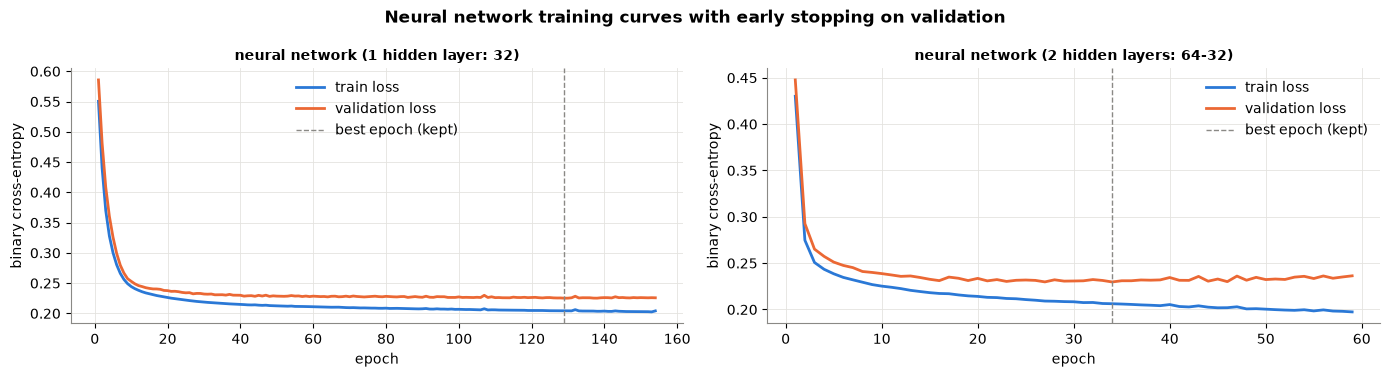

In [102]:
# training curves of the two networks, with the epoch kept by early stopping
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (name, pipe) in zip(axes, nn_runs.items()):
    h = pipe.named_steps["model"].history_
    ax.plot(h["epoch"], h["train loss"], color=PALETTE[0], label="train loss")
    ax.plot(h["epoch"], h["validation loss"], color=PALETTE[1], label="validation loss")
    ax.axvline(pipe.named_steps["model"].best_epoch_, color=GREY, linestyle="--", linewidth=1, label="best epoch (kept)")
    ax.set_title(name.split(" ", 1)[1], fontsize=10)
    ax.set_xlabel("epoch")
    ax.set_ylabel("binary cross-entropy")
    ax.legend()
fig.suptitle("Neural network training curves with early stopping on validation", fontweight="bold")
fig.tight_layout()
savefig(fig, "p7_nn_training_curves")
plt.show()

**Hints.** The validation loss bottoms out early while the training loss keeps falling; early stopping keeps the best
epoch (dashed line). 1 and 2 hidden layers score similarly.

### 7.6 Final comparison

Finalist per family = the attempt with the best validation PR-AUC. Test scores are shown now for every attempt; no
choice changes after seeing them.

In [103]:
# pick one finalist per family by validation PR-AUC, then show every attempt on train / validation / test
FAMILIES = {"rule": "rule: grid ≤ 3", "logistic regression": ["A1 logistic regression (default)", "A2 logistic regression (tuned)"],
            "random forest": ["A3a random forest (default)", "A3b random forest (tuned)"],
            "gradient boosting": ["A4 gradient boosting (tuned)"],
            "neural network": ["A5a neural network (1 hidden layer: 32)", "A5b neural network (2 hidden layers: 64-32)"]}
val_pr = {n: a["table"].loc["validation", "PR-AUC"] for n, a in ATTEMPTS.items()}
FINALISTS = {fam: (names if isinstance(names, str) else max(names, key=val_pr.get)) for fam, names in FAMILIES.items()}

comparison = pd.concat({n: a["table"] for n, a in ATTEMPTS.items()}, names=["model", "set"]).round(3)
comparison["threshold"] = [ATTEMPTS[n]["threshold"] for n, _ in comparison.index]
comparison["finalist"] = [n in FINALISTS.values() for n, _ in comparison.index]
display(comparison.round(3))

final_table = comparison.loc[list(FINALISTS.values())].drop(columns="finalist").reset_index()
final_table.insert(0, "family", final_table["model"].map({v: k for k, v in FINALISTS.items()}))
final_table = final_table.set_index(["family", "model", "set"])
print("Finalists (one per family, chosen on validation PR-AUC):")
final_table.round(3)

ROC-AUC  PR-AUC     F1  precision  recall  threshold  finalist
model                                       set                                                                       
rule: grid ≤ 3                              train         0.909   0.628  0.648      0.649   0.646      0.333      True
                                            validation    0.910   0.648  0.695      0.698   0.692      0.333      True
                                            test          0.913   0.647  0.649      0.650   0.647      0.333      True
A1 logistic regression (default)            train         0.931   0.687  0.677      0.586   0.801      0.287      True
                                            validation    0.933   0.732  0.715      0.682   0.752      0.287      True
                                            test          0.936   0.709  0.674      0.590   0.784      0.287      True
A2 logistic regression (tuned)              train         0.931   0.687  0.677      0.586   0.801      0.287     False
                                            validation    0.933   0.732  0.715      0.682   0.752      0.287     False
                                            test          0.936   0.709  0.674      0.590   0.784      0.287     False
A3a random forest (default)                 train         1.000   1.000  0.999      0.999   1.000      0.387     False
                                            validation    0.915   0.665  0.698      0.704   0.692      0.387     False
                                            test          0.932   0.705  0.664      0.630   0.701      0.387     False
A3b random forest (tuned)                   train         0.955   0.773  0.701      0.592   0.860      0.257      True
                                            validation    0.932   0.717  0.718      0.655   0.795      0.257      True
                                            test          0.936   0.716  0.672      0.558   0.843      0.257      True
A4 gradient boosting (tuned)                train         0.955   0.775  0.729      0.645   0.838      0.300      True
                                            validation    0.931   0.724  0.713      0.677   0.752      0.300      True
                                            test          0.937   0.723  0.685      0.612   0.779      0.300      True
A5a neural network (1 hidden layer: 32)     train         0.943   0.724  0.693      0.607   0.807      0.302      True
                                            validation    0.929   0.732  0.707      0.674   0.744      0.302      True
                                            test          0.935   0.692  0.661      0.603   0.730      0.302      True
A5b neural network (2 hidden layers: 64-32) train         0.942   0.724  0.686      0.594   0.812      0.301     False
                                            validation    0.926   0.722  0.715      0.682   0.752      0.301     False
                                            test          0.930   0.687  0.639      0.574   0.721      0.301     False

Finalists (one per family, chosen on validation PR-AUC):


ROC-AUC  PR-AUC     F1  precision  recall  threshold
family              model                                   set                                                             
rule                rule: grid ≤ 3                          train         0.909   0.628  0.648      0.649   0.646      0.333
                                                            validation    0.910   0.648  0.695      0.698   0.692      0.333
                                                            test          0.913   0.647  0.649      0.650   0.647      0.333
logistic regression A1 logistic regression (default)        train         0.931   0.687  0.677      0.586   0.801      0.287
                                                            validation    0.933   0.732  0.715      0.682   0.752      0.287
                                                            test          0.936   0.709  0.674      0.590   0.784      0.287
random forest       A3b random forest (tuned)               train         0.955   0.773  0.701      0.592   0.860      0.257
                                                            validation    0.932   0.717  0.718      0.655   0.795      0.257
                                                            test          0.936   0.716  0.672      0.558   0.843      0.257
gradient boosting   A4 gradient boosting (tuned)            train         0.955   0.775  0.729      0.645   0.838      0.300
                                                            validation    0.931   0.724  0.713      0.677   0.752      0.300
                                                            test          0.937   0.723  0.685      0.612   0.779      0.300
neural network      A5a neural network (1 hidden layer: 32) train         0.943   0.724  0.693      0.607   0.807      0.302
                                                            validation    0.929   0.732  0.707      0.674   0.744      0.302
                                                            test          0.935   0.692  0.661      0.603   0.730      0.302

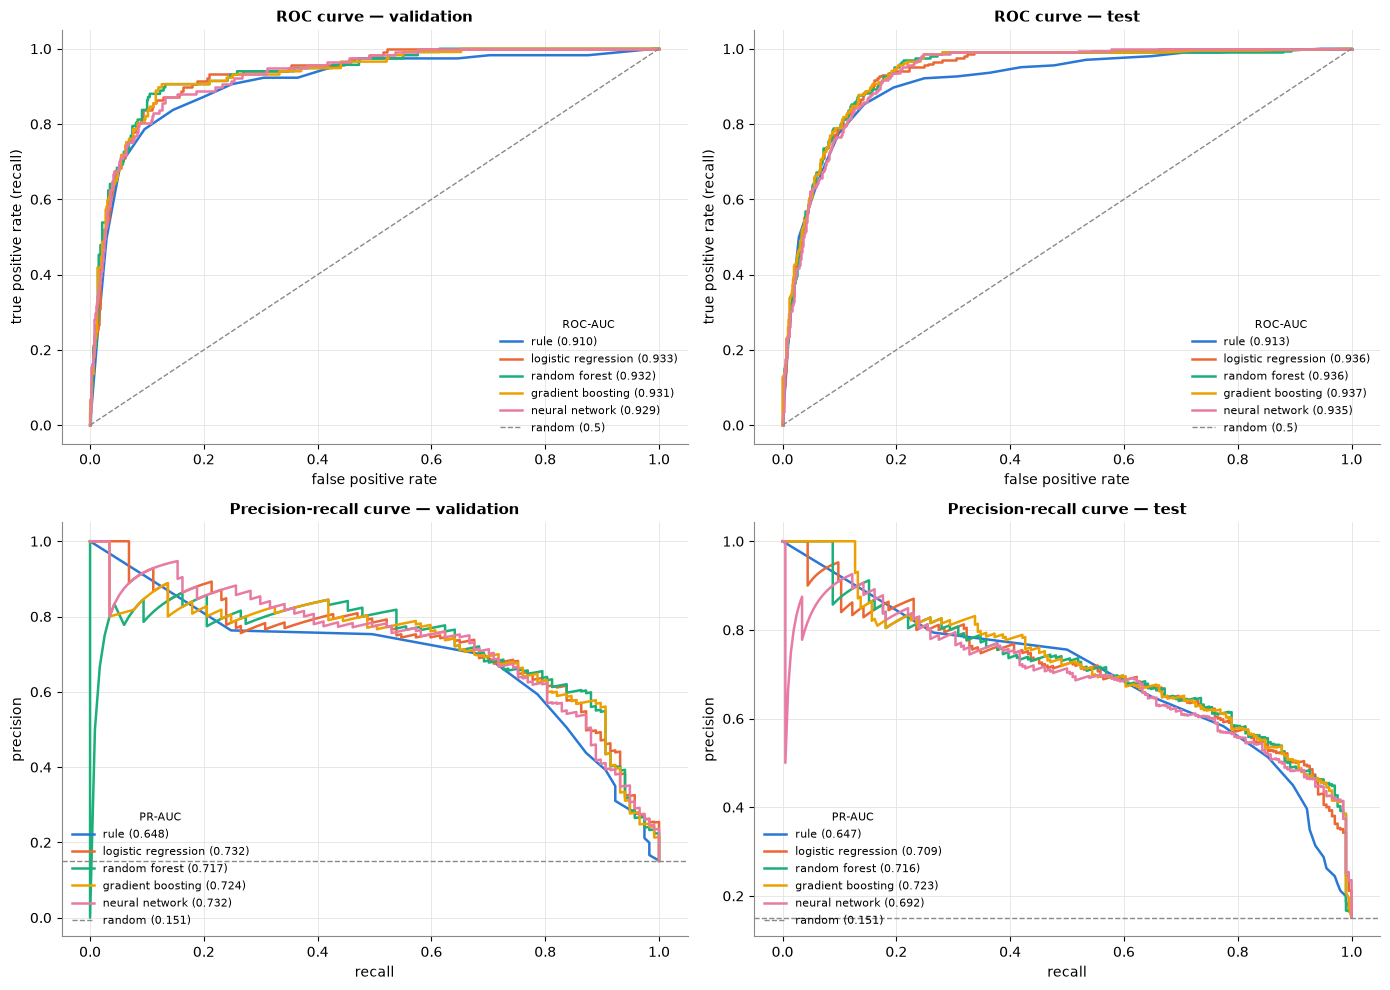

In [104]:
# ROC and precision-recall curves of the finalists, on validation and test
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, p in enumerate(["validation", "test"]):
    prevalence = y[p].mean()
    for i, (family, name) in enumerate(FINALISTS.items()):
        proba = ATTEMPTS[name]["proba"][p]
        fpr, tpr, _ = roc_curve(y[p], proba)
        prec, rec, _ = precision_recall_curve(y[p], proba)
        auc_roc, auc_pr = roc_auc_score(y[p], proba), average_precision_score(y[p], proba)
        axes[0, col].plot(fpr, tpr, color=PALETTE[i], linewidth=1.8, label=f"{family} ({auc_roc:.3f})")
        axes[1, col].plot(rec, prec, color=PALETTE[i], linewidth=1.8, label=f"{family} ({auc_pr:.3f})")
    axes[0, col].plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="random (0.5)")
    axes[1, col].axhline(prevalence, color=GREY, linestyle="--", linewidth=1, label=f"random ({prevalence:.3f})")
    axes[0, col].set_title(f"ROC curve — {p}")
    axes[0, col].set_xlabel("false positive rate")
    axes[0, col].set_ylabel("true positive rate (recall)")
    axes[1, col].set_title(f"Precision-recall curve — {p}")
    axes[1, col].set_xlabel("recall")
    axes[1, col].set_ylabel("precision")
    axes[0, col].legend(loc="lower right", fontsize=8, title="ROC-AUC", title_fontsize=8)
    axes[1, col].legend(loc="lower left", fontsize=8, title="PR-AUC", title_fontsize=8)
fig.tight_layout()
savefig(fig, "p7_roc_pr_curves")
plt.show()

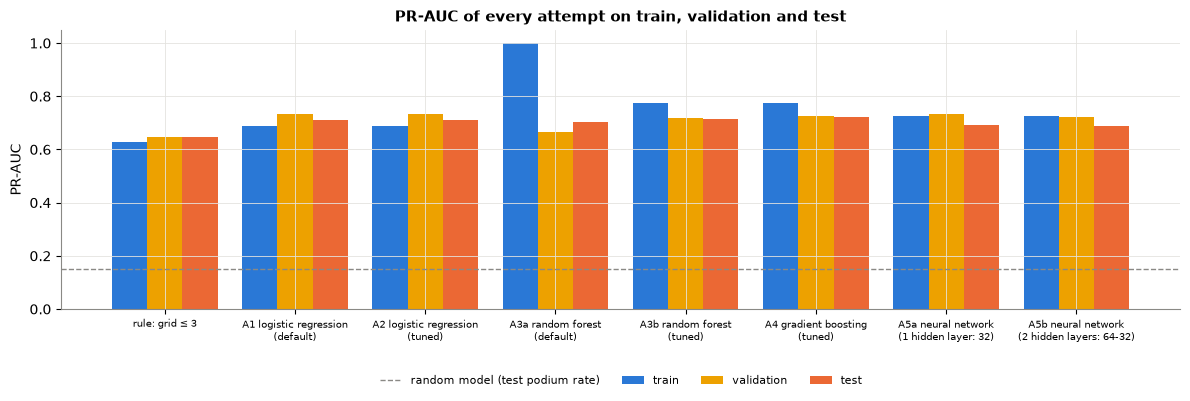

In [105]:
# PR-AUC of every attempt on the three sets (overfitting = high train, lower validation)
attempt_names = list(ATTEMPTS)
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(attempt_names))
for k, (p, color) in enumerate(zip(PERIODS, [PALETTE[0], PALETTE[3], PALETTE[1]])):
    ax.bar(x + (k - 1) * 0.27, [ATTEMPTS[n]["table"].loc[p, "PR-AUC"] for n in attempt_names], width=0.27, color=color, label=p)
ax.axhline(y["test"].mean(), color=GREY, linestyle="--", linewidth=1, label="random model (test podium rate)")
ax.set_xticks(x, [n.replace(" (", "\n(") for n in attempt_names], fontsize=7)
ax.set_ylim(0, 1.05)
ax.set_title("PR-AUC of every attempt on train, validation and test")
ax.set_ylabel("PR-AUC")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
fig.tight_layout()
savefig(fig, "p7_attempts_pr_auc")
plt.show()

**Hints.**
* Every model beats the rule on test PR-AUC (0.69–0.72 vs 0.65): form, standings and pace add information.
* The models are close: validation LR 0.7317, NN 0.7315, GB 0.724, RF 0.717; test GB 0.723, RF 0.716, LR 0.709,
  NN 0.692. Differences of this size are within noise for 39 validation races.
* Overfitting shows where train is highest (default forest 1.000 vs 0.665).
* No collapse on the new era: test ≈ validation for every model.
* The thresholds favour recall (73–84% of podiums caught on test) over precision (56–61%); test F1 0.66–0.69.

**Selected: logistic regression** (best validation PR-AUC, by 0.0002 over the network; the simplest to explain).
Picking gradient boosting because it is best on test would be choosing on test. The tuned random forest is also
explained in Phase 9.

## 8. Experiments

Each experiment changes **one thing** (rows, settings and threshold rule stay fixed), retrains and compares.

| Experiment | What changes | What it justifies |
|---|---|---|
| 8.1 Feature-group ablation | one group of features is removed | the feature choice (test T4 of Phase 5) |
| 8.2 Order experiment 1 | impute → scale vs scale → impute | the order of the preprocessing steps |
| 8.3 Order experiment 2 | preprocessing fitted on train only vs on all seasons | fitting on the training seasons only (leakage) |

Thresholds are chosen on validation (best F1); conclusions are drawn on validation, test is shown alongside.

In [106]:
# helpers for the experiments, and a check that they reproduce the Phase 7 models exactly
def scores_from_proba(proba):
    """All five metrics per set, with the threshold chosen on validation."""
    threshold = best_f1_threshold(y["validation"], proba["validation"])
    return pd.DataFrame({p: metrics(y[p], proba[p], threshold) for p in PERIODS}).T


def fit_and_score(features, build_model, scale):
    """Retrain a pipeline on a subset of features (train only) and score it on every set."""
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", build_model())]).fit(X["train"][features], y["train"])
    return scores_from_proba({p: pipe.predict_proba(X[p][features])[:, 1] for p in PERIODS})


ABLATION_MODELS = {
    "logistic regression": (lambda: LogisticRegression(max_iter=5000, random_state=SEED), True),
    "random forest": (lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, **forest_best), False),
}

# sanity check: the helper reproduces the section-9 models exactly
full_scores = {name: fit_and_score(FEATURES, build, scale) for name, (build, scale) in ABLATION_MODELS.items()}
assert np.allclose(full_scores["logistic regression"].values, ATTEMPTS["A1 logistic regression (default)"]["table"].values)
assert np.allclose(full_scores["random forest"].values, ATTEMPTS["A3b random forest (tuned)"]["table"].values)
print("helper reproduces the logistic regression (A1) and the tuned random forest (A3b) exactly")

helper reproduces the logistic regression (A1) and the tuned random forest (A3b) exactly


### 8.1 Feature-group ablation

Remove one of the 7 groups, retrain, and compute **drop = full model − model without the group**:
* large positive → the group carries information no other group has;
* ≈ 0 → useless *or* redundant with another group;
* negative → the model is better without it.

Driver form + constructor form + standings are also removed **together** once (strongly correlated, 5.11). Run on the
logistic regression and the tuned random forest.

In [107]:
# one combined ablation: the three groups that all measure "how strong is this driver / car" (correlated, see 5.11)
COMBINED = {"form + standings (3 groups together)": GROUPS["driver form"] + GROUPS["constructor form"] + GROUPS["standings"]}
ABLATED = {**GROUPS, **COMBINED}

ablation_rows = []
for model_name, (build, scale) in ABLATION_MODELS.items():
    full = full_scores[model_name]
    for group, group_features in ABLATED.items():
        kept = [f for f in FEATURES if f not in group_features]
        reduced = fit_and_score(kept, build, scale)
        for p in PERIODS:
            ablation_rows.append({"model": model_name, "group removed": group, "features removed": len(group_features),
                                  "set": p, **(full.loc[p] - reduced.loc[p]).to_dict()})
ablation = pd.DataFrame(ablation_rows)

show_cols = ["PR-AUC", "ROC-AUC", "F1", "precision", "recall"]
ablation_table = (ablation[ablation["set"].isin(["validation", "test"])]
                  .pivot_table(index=["model", "group removed"], columns="set", values=show_cols)
                  .reindex(columns=pd.MultiIndex.from_product([show_cols, ["validation", "test"]])))
print("drop in each metric when the group is removed (positive = the group helps)")
ablation_table.round(4)

drop in each metric when the group is removed (positive = the group helps)


PR-AUC            ROC-AUC                 F1          precision             recall        
                                                         validation    test validation    test validation    test validation    test validation    test
model               group removed                                                                                                                      
logistic regression circuit & teammate                       0.0163 -0.0061     0.0009  0.0001     0.0109  0.0057     0.0495  0.0395    -0.0427 -0.0637
                    constructor form                        -0.0076 -0.0007    -0.0007 -0.0001     0.0006  0.0159     0.0383  0.0512    -0.0513 -0.0588
                    driver form                             -0.0028 -0.0040     0.0002 -0.0010     0.0012 -0.0021    -0.0203 -0.0421     0.0256  0.0588
                    form + standings (3 groups together)     0.0179  0.0238     0.0026  0.0123    -0.0017  0.0099     0.0105 -0.0112    -0.0171  0.0441
                    grid                                     0.0911  0.0622     0.0289  0.0229     0.0216  0.0745     0.0181  0.0645     0.0256  0.0882
                    qualifying                               0.0081  0.0032     0.0045  0.0000     0.0053  0.0205     0.0658  0.0667    -0.0855 -0.0833
                    reliability                             -0.0005  0.0000    -0.0002 -0.0001     0.0037  0.0181     0.0724  0.0653    -0.1026 -0.0882
                    standings                                0.0011 -0.0029    -0.0002  0.0005    -0.0088 -0.0075    -0.0162 -0.0238     0.0000  0.0196
random forest       circuit & teammate                       0.0022 -0.0023    -0.0004  0.0002     0.0017  0.0150     0.0192  0.0318    -0.0256 -0.0294
                    constructor form                         0.0038  0.0007     0.0017 -0.0016     0.0131  0.0112     0.0462  0.0356    -0.0427 -0.0539
                    driver form                              0.0036 -0.0029     0.0017 -0.0015    -0.0022 -0.0067     0.0022 -0.0116    -0.0085  0.0049
                    form + standings (3 groups together)     0.0217  0.0126     0.0092  0.0044     0.0132  0.0052    -0.0222 -0.0693     0.0598  0.1324
                    grid                                     0.0585  0.0606     0.0223  0.0190     0.0133  0.0551    -0.0723 -0.0308     0.1111  0.1961
                    qualifying                              -0.0065  0.0091     0.0019  0.0021    -0.0022  0.0221     0.0022  0.0197    -0.0085  0.0245
                    reliability                              0.0046 -0.0022     0.0012 -0.0002    -0.0021  0.0242     0.0455  0.0501    -0.0855 -0.0490
                    standings                                0.0058  0.0088     0.0015  0.0009    -0.0139  0.0141    -0.0005  0.0212    -0.0342 -0.0049

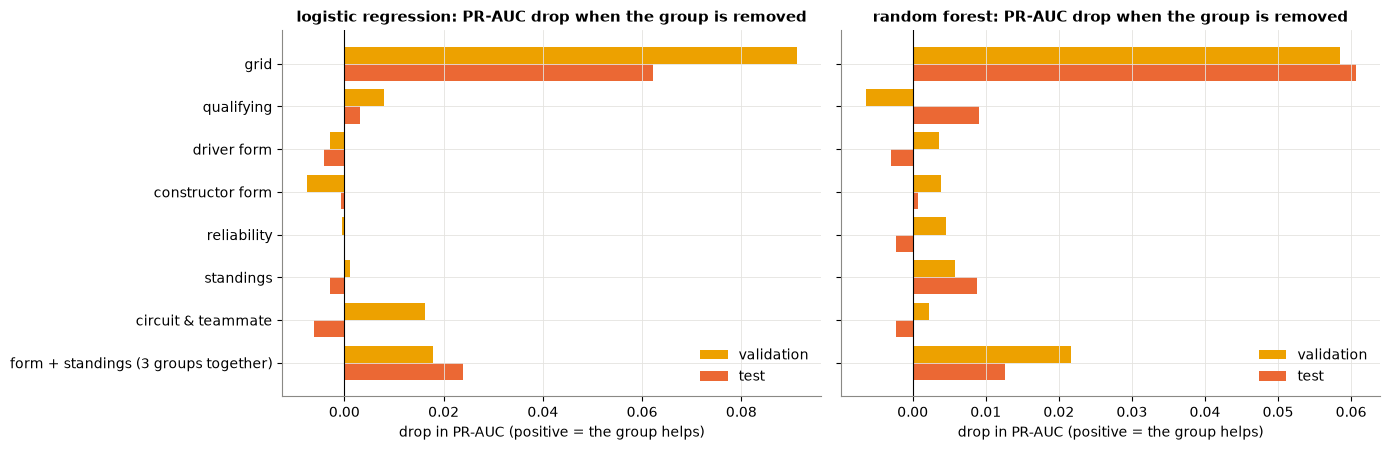

In [108]:
# plot the PR-AUC drop per removed group, for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
order = list(ABLATED)[::-1]
for ax, model_name in zip(axes, ABLATION_MODELS):
    d = ablation[(ablation["model"] == model_name)].pivot(index="group removed", columns="set", values="PR-AUC").loc[order]
    yy = np.arange(len(order))
    ax.barh(yy + 0.2, d["validation"], height=0.4, color=PALETTE[3], label="validation")
    ax.barh(yy - 0.2, d["test"], height=0.4, color=PALETTE[1], label="test")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_yticks(yy, order)
    ax.set_title(f"{model_name}: PR-AUC drop when the group is removed")
    ax.set_xlabel("drop in PR-AUC (positive = the group helps)")
    ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "p8_ablation")
plt.show()

**Hints.**
* **Grid** is the only group the models cannot do without: drop 0.09 / 0.06 PR-AUC (LR, validation / test) and
  0.06 / 0.06 (RF).
* Every other single group moves PR-AUC by less than ±0.017 (noise level). Removing the three correlated strength
  groups **together** costs 0.018 / 0.024 (LR) and 0.022 / 0.013 (RF): they stand in for each other.
* No group makes both models clearly worse on validation → **all 18 features are kept**.
* A small drop means "not needed given the others", not "unrelated to podiums" (see Phase 9).

### 8.2 Order experiment 1: impute → scale vs scale → impute

Imputing first puts identical medians into a column, which lowers its standard deviation before scaling (most for
`drv_circuit_podium_rate`, 24% missing). Scaling first uses only the real values. Only for scale-sensitive models:
logistic regression and neural network.

In [109]:
# order A (impute -> scale) vs order B (scale -> impute): learned numbers and scores of two scale-sensitive models
def make_preprocessor_scale_first():
    """Order B: standardise first (scikit-learn's scaler ignores NaN when fitting), then impute + indicators."""
    return Pipeline([("scale", StandardScaler()), ("impute", SimpleImputer(strategy="median", add_indicator=True))])


prep_a = make_preprocessor(scale=True).fit(X["train"])            # order A: impute -> scale (ours)
prep_b = make_preprocessor_scale_first().fit(X["train"])           # order B: scale -> impute
assert list(prep_a.get_feature_names_out()) == list(prep_b.get_feature_names_out())

most_missing = X["train"].isna().mean().sort_values(ascending=False).head(5).index
learned = pd.DataFrame({
    "% missing (train)": (X["train"][most_missing].isna().mean() * 100).round(1),
    "std used, A: impute → scale": pd.Series(prep_a.named_steps["scale"].scale_[:len(FEATURES)], index=FEATURES)[most_missing],
    "std used, B: scale → impute": pd.Series(prep_b.named_steps["scale"].scale_, index=FEATURES)[most_missing],
}).round(4)
display(learned)


def nn_with(prep):
    mlp = TorchMLP(hidden=(32,), val_data=(prep.transform(X["validation"]), y["validation"])).fit(prep.transform(X["train"]), y["train"])
    return scores_from_proba({p: mlp.predict_proba(prep.transform(X[p]))[:, 1] for p in PERIODS})


def logreg_with(prep):
    model = LogisticRegression(max_iter=5000, random_state=SEED).fit(prep.transform(X["train"]), y["train"])
    return scores_from_proba({p: model.predict_proba(prep.transform(X[p]))[:, 1] for p in PERIODS})


order_results = {}
for model_name, run in [("logistic regression", logreg_with), ("neural network", nn_with)]:
    order_results[(model_name, "A: impute → scale")] = run(prep_a)
    order_results[(model_name, "B: scale → impute")] = run(prep_b)
assert np.allclose(order_results[("neural network", "A: impute → scale")].values,
                   ATTEMPTS["A5a neural network (1 hidden layer: 32)"]["table"].values), "order A reproduces A5a"

order1 = pd.concat(order_results, names=["model", "order", "set"])
order1 = order1[order1.index.get_level_values("set").isin(["validation", "test"])]
display(order1.round(4))
order1_diff = (order1.xs("B: scale → impute", level="order") - order1.xs("A: impute → scale", level="order")).round(4)
print("difference B − A:")
order1_diff

,% missing (train),"std used, A: impute → scale","std used, B: scale → impute"
drv_circuit_podium_rate,23.9,0.2165,0.2363
drv_champ_pos,7.1,6.2231,6.4569
drv_pts_share,7.1,0.2945,0.3035
team_pts_share,5.7,0.3281,0.3357
team_champ_pos,5.7,3.0188,3.1078


ROC-AUC  PR-AUC      F1  precision  recall
model               order             set                                                   
logistic regression A: impute → scale validation   0.9332  0.7317  0.7154     0.6822  0.7521
                                      test         0.9360  0.7094  0.6737     0.5904  0.7843
                    B: scale → impute validation   0.9324  0.7291  0.7116     0.6333  0.8120
                                      test         0.9361  0.7081  0.6629     0.5421  0.8529
neural network      A: impute → scale validation   0.9294  0.7315  0.7073     0.6744  0.7436
                                      test         0.9351  0.6918  0.6608     0.6032  0.7304
                    B: scale → impute validation   0.9270  0.7174  0.7194     0.6691  0.7778
                                      test         0.9347  0.6991  0.6624     0.5900  0.7549

difference B − A:


ROC-AUC  PR-AUC      F1  precision  recall
model               set                                                   
logistic regression validation  -0.0009 -0.0026 -0.0038    -0.0488  0.0598
                    test         0.0001 -0.0012 -0.0108    -0.0483  0.0686
neural network      validation  -0.0024 -0.0142  0.0121    -0.0053  0.0342
                    test        -0.0004  0.0073  0.0016    -0.0132  0.0245

**Hints.**
* The learned standard deviations differ as expected (`drv_circuit_podium_rate`: 0.216 vs 0.236).
* Logistic regression: practically no difference (−0.003 / −0.001 PR-AUC).
* Network: scale → impute is −0.014 on validation but +0.007 on test: more sensitive, not stable.
* → **impute → scale** is kept (at least as good on validation; the scaler sees the values the model receives).

### 8.3 Order experiment 2: preprocessing fitted on train only vs on all seasons (leakage)

Fitting the imputer and scaler on all seasons lets 2020–24 statistics into training (forbidden by the brief). Done
here on purpose to measure the effect.

In [110]:
# preprocessing fitted on train only vs on all seasons (the leak): learned numbers and scores
X_all = pd.concat([X[p] for p in PERIODS])
prep_train_only = make_preprocessor(scale=True).fit(X["train"])
prep_all_seasons = make_preprocessor(scale=True).fit(X_all)        # the leak: validation + test values are seen

stats = pd.DataFrame({
    "median, train only": prep_train_only.named_steps["impute"].statistics_,
    "median, all seasons": prep_all_seasons.named_steps["impute"].statistics_,
    "mean, train only": prep_train_only.named_steps["scale"].mean_[:len(FEATURES)],
    "mean, all seasons": prep_all_seasons.named_steps["scale"].mean_[:len(FEATURES)],
}, index=FEATURES)
stats["mean shift (in train std)"] = (stats["mean, all seasons"] - stats["mean, train only"]) / prep_train_only.named_steps["scale"].scale_[:len(FEATURES)]
display(stats.reindex(stats["mean shift (in train std)"].abs().sort_values(ascending=False).index).head(6).round(3))

leak_results = {}
for model_name, run in [("logistic regression", logreg_with), ("neural network", nn_with)]:
    leak_results[(model_name, "train only (correct)")] = run(prep_train_only)
    leak_results[(model_name, "all seasons (leak)")] = run(prep_all_seasons)
order2 = pd.concat(leak_results, names=["model", "fit on", "set"])
order2 = order2[order2.index.get_level_values("set").isin(["validation", "test"])]
display(order2.round(4))
order2_diff = (order2.xs("all seasons (leak)", level="fit on") - order2.xs("train only (correct)", level="fit on")).round(4)
print("difference leak − correct:")
order2_diff

,"median, train only","median, all seasons","mean, train only","mean, all seasons",mean shift (in train std)
drv_dnf_rate_expanding,0.251,0.215,0.271,0.245,-0.184
team_mech_dnf_rate,0.100,0.100,0.127,0.112,-0.134
drv_career_starts,70.000,82.000,92.904,103.358,0.132
team_races_history,124.000,133.000,258.776,282.565,0.084
q1_gap_pct,1.342,1.223,1.772,1.631,-0.078
drv_avg_finish,11.400,11.300,11.079,10.917,-0.038


ROC-AUC  PR-AUC      F1  precision  recall
model               fit on               set                                                   
logistic regression train only (correct) validation   0.9332  0.7317  0.7154     0.6822  0.7521
                                         test         0.9360  0.7094  0.6737     0.5904  0.7843
                    all seasons (leak)   validation   0.9332  0.7320  0.7154     0.6822  0.7521
                                         test         0.9359  0.7086  0.6737     0.5904  0.7843
neural network      train only (correct) validation   0.9294  0.7315  0.7073     0.6744  0.7436
                                         test         0.9351  0.6918  0.6608     0.6032  0.7304
                    all seasons (leak)   validation   0.9297  0.7313  0.7177     0.6794  0.7607
                                         test         0.9361  0.7002  0.6652     0.6040  0.7402

difference leak − correct:


ROC-AUC  PR-AUC      F1  precision  recall
model               set                                                   
logistic regression validation  -0.0001  0.0003  0.0000     0.0000  0.0000
                    test        -0.0000 -0.0008  0.0000     0.0000  0.0000
neural network      validation   0.0003 -0.0002  0.0104     0.0050  0.0171
                    test         0.0011  0.0084  0.0044     0.0008  0.0098

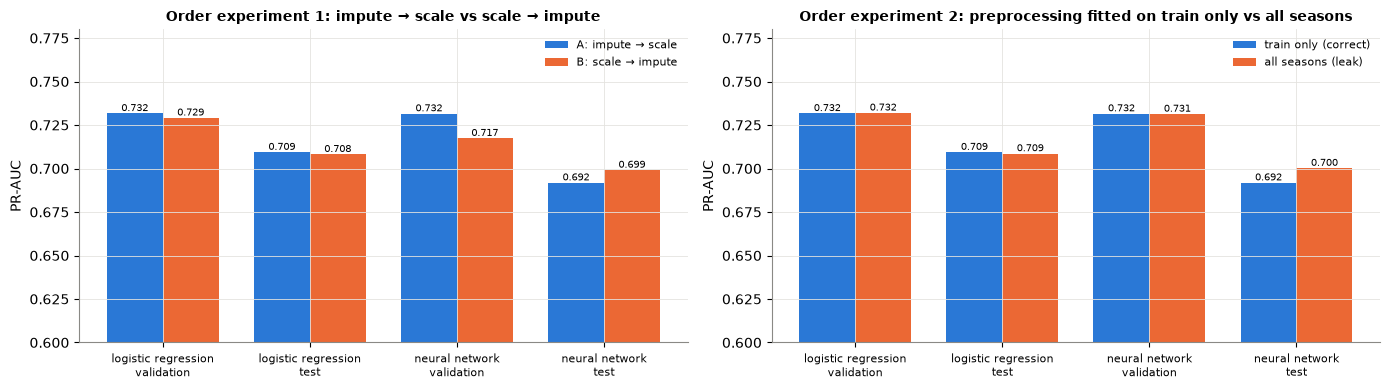

In [111]:
# PR-AUC of both order experiments, for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (table, level, title) in zip(axes, [(order1, "order", "Order experiment 1: impute → scale vs scale → impute"),
                                            (order2, "fit on", "Order experiment 2: preprocessing fitted on train only vs all seasons")]):
    variants = table.index.get_level_values(level).unique()
    labels = [f"{m}\n{s}" for m in ["logistic regression", "neural network"] for s in ["validation", "test"]]
    x = np.arange(len(labels))
    for k, (variant, color) in enumerate(zip(variants, [PALETTE[0], PALETTE[1]])):
        values = [table.loc[(m, variant, s), "PR-AUC"] for m in ["logistic regression", "neural network"] for s in ["validation", "test"]]
        ax.bar(x + (k - 0.5) * 0.38, values, width=0.38, color=color, label=variant)
        for xi, v in zip(x + (k - 0.5) * 0.38, values):
            ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set_ylim(0.6, 0.78)
    ax.set_ylabel("PR-AUC")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "p8_order_experiments")
plt.show()

**Hints.**
* The leak moves the learned numbers towards 2020–24 (`drv_dnf_rate_expanding` mean −0.18 SD, `drv_career_starts`
  +0.13 SD).
* Logistic regression: PR-AUC and ROC-AUC change by ≤ 0.001 and the decisions are identical (a linear model
  compensates).
* Network: test PR-AUC +0.008, F1 +0.010 / +0.004: it looks better on the seasons whose statistics it saw.
* Still invalid (with label-based steps it would inflate scores directly) → every step is fitted on train only,
  inside the pipeline.

## 9. Explainability (XAI)

What the model relies on, overall and for single predictions.

| Method | Scope | Question it answers |
|---|---|---|
| Permutation importance | global | how much does the score drop if this feature's values are shuffled (its information destroyed)? |
| SHAP (global) | global | on average, how much does each feature push predictions up or down, and in which direction? |
| SHAP waterfall | local | for **one** row, how does each feature move the prediction away from the average? |
| LIME | local | for **one** row, which simple rules describe the model's behaviour around that row? |

> **Importance is not causation.** Every result below describes **how the model uses the features to predict**, not
> what *causes* a podium. A feature can be important because it is correlated with the real cause (e.g. championship
> points reflect a fast car; they do not make the car fast), and correlated features share or steal importance from
> each other. None of these plots says "changing X would change the race result".

### 9.1 Which models and which data

* **Logistic regression**: the selected model (7.6).
* **Random forest (tuned)**: the strongest tree model, as a non-linear comparison.

Computed on the **test seasons (2022–2024)**; nothing is tuned or changed afterwards.

In [112]:
# the two models to explain, scored on the test seasons
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance

XAI_SET = "test"
Xe, ye = X[XAI_SET], y[XAI_SET]
EXPLAINED = {"logistic regression": logreg_default, "random forest": forest_tuned}
for name, pipe in EXPLAINED.items():
    print(f"{name}: PR-AUC on {XAI_SET} = {average_precision_score(ye, pipe.predict_proba(Xe)[:, 1]):.3f}")

C:\Users\Dell\Desktop\F1-podium\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


logistic regression: PR-AUC on test = 0.709
random forest: PR-AUC on test = 0.716


### 9.2 Permutation importance

Shuffle one feature across the test rows, measure the drop in PR-AUC, 20 repeats. Works on the 18 original features
(a feature's missing indicator is shuffled with it).

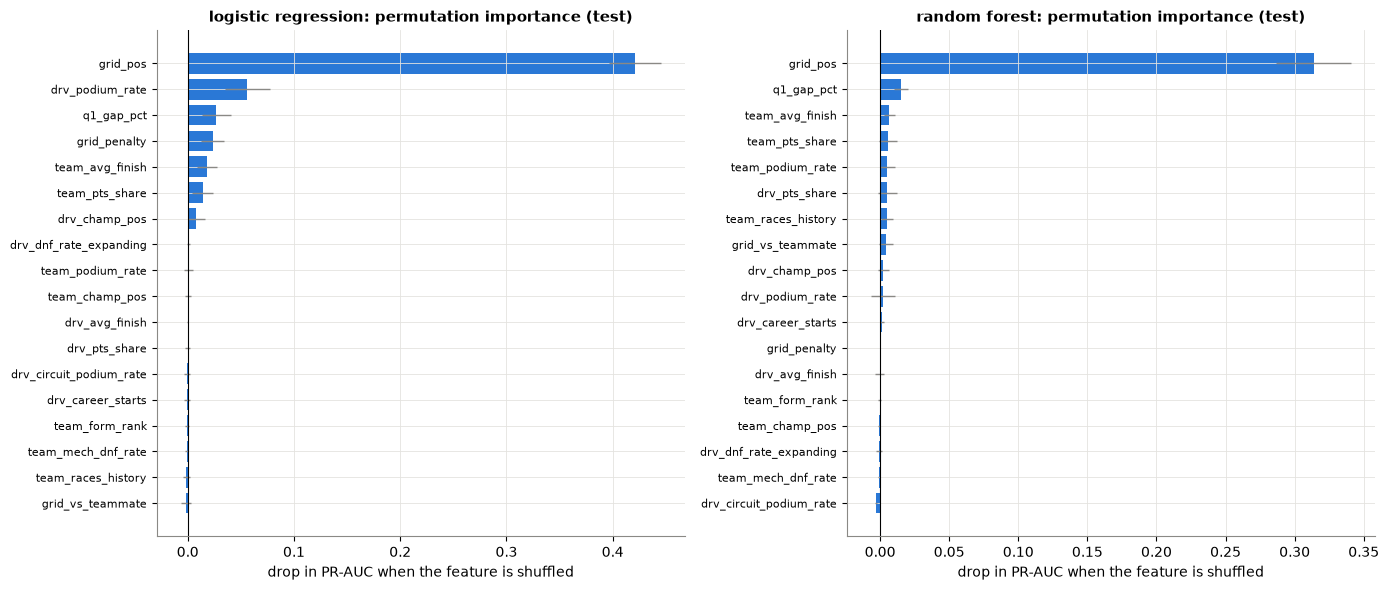

logistic regression         random forest        
                                  mean drop     std     mean drop     std
grid_pos                             0.4209  0.0246        0.3138  0.0270
drv_podium_rate                      0.0561  0.0211        0.0020  0.0089
q1_gap_pct                           0.0269  0.0135        0.0151  0.0049
grid_penalty                         0.0234  0.0108       -0.0000  0.0000
team_avg_finish                      0.0184  0.0094        0.0066  0.0041
team_pts_share                       0.0140  0.0099        0.0057  0.0064
drv_champ_pos                        0.0081  0.0082        0.0023  0.0041
drv_dnf_rate_expanding               0.0006  0.0016       -0.0009  0.0021
team_podium_rate                     0.0003  0.0043        0.0053  0.0054
drv_avg_finish                       0.0002  0.0006       -0.0001  0.0032
team_champ_pos                       0.0002  0.0031       -0.0008  0.0005
drv_pts_share                       -0.0001  0.0027        0.0053  0.0071
drv_circuit_podium_rate             -0.0005  0.0025       -0.0028  0.0009
drv_career_starts                   -0.0006  0.0026        0.0015  0.0016
team_mech_dnf_rate                  -0.0008  0.0014       -0.0011  0.0006
team_form_rank                      -0.0008  0.0017       -0.0003  0.0013
team_races_history                  -0.0012  0.0029        0.0047  0.0044
grid_vs_teammate                    -0.0016  0.0051        0.0040  0.0051

In [113]:
# permutation importance (drop in PR-AUC when one feature is shuffled, 20 repeats) for both models
perm = {}
for name, pipe in EXPLAINED.items():
    r = permutation_importance(pipe, Xe, ye, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=1)
    perm[name] = pd.DataFrame({"mean drop": r.importances_mean, "std": r.importances_std}, index=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
for ax, (name, table) in zip(axes, perm.items()):
    t = table.sort_values("mean drop")
    ax.barh(t.index, t["mean drop"], xerr=t["std"], color=PALETTE[0], error_kw={"elinewidth": 1, "ecolor": GREY})
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{name}: permutation importance ({XAI_SET})")
    ax.set_xlabel("drop in PR-AUC when the feature is shuffled")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
savefig(fig, "p9_permutation_importance")
plt.show()
pd.concat(perm, axis=1).round(4).sort_values(("logistic regression", "mean drop"), ascending=False)

**Hints.**
* `grid_pos` dominates: −0.42 PR-AUC (LR), −0.31 (RF), more than all other features together (agrees with the
  ablation).
* LR also uses driver form (`drv_podium_rate` 0.056), the Q1 gap (0.027), the grid penalty (0.023) and team strength
  (`team_avg_finish` 0.018, `team_pts_share` 0.014).
* RF: Q1 gap (0.015), team strength and standings (~0.005 each); it does not use `grid_penalty`.
* ≈ 0 does not mean useless: correlated partners still carry the same information.

### 9.3 SHAP (global)

prediction = average prediction + one contribution per feature (positive → towards a podium).
* LR: `LinearExplainer` (exact for a linear model), in log-odds, training seasons as background.
* RF: `TreeExplainer` (exact for trees), in probability.

Each missing indicator's contribution is added to its feature, so the plots show the 18 original features.

In [114]:
# SHAP values (LinearExplainer / TreeExplainer), indicators added to their feature, additivity checked
def group_to_features(values, column_names):
    """Add each missing-indicator column's SHAP value to its feature -> one column per original feature."""
    df = pd.DataFrame(values, columns=[c.replace("missingindicator_", "") for c in column_names])
    return df.T.groupby(level=0).sum().T[FEATURES]


# logistic regression
lr_prep, lr_model = logreg_default.named_steps["prep"], logreg_default.named_steps["model"]
lr_columns = lr_prep.get_feature_names_out()
lr_explainer = shap.LinearExplainer(lr_model, shap.maskers.Independent(lr_prep.transform(X["train"]), max_samples=1000))
lr_explanation = lr_explainer(lr_prep.transform(Xe))
lr_shap = group_to_features(lr_explanation.values, lr_columns)
lr_base = float(np.ravel(lr_explanation.base_values)[0])

# random forest
rf_prep, rf_model = forest_tuned.named_steps["prep"], forest_tuned.named_steps["model"]
rf_columns = rf_prep.get_feature_names_out()
rf_explainer = shap.TreeExplainer(rf_model)
rf_values = rf_explainer.shap_values(rf_prep.transform(Xe), check_additivity=False)
rf_values = rf_values[1] if isinstance(rf_values, list) else (rf_values[:, :, 1] if rf_values.ndim == 3 else rf_values)
rf_shap = group_to_features(rf_values, rf_columns)
rf_base = float(np.ravel(rf_explainer.expected_value)[-1])

# check: contributions add up to the model output (log-odds for LR, probability for RF)
lr_logit = lr_model.decision_function(lr_prep.transform(Xe))
assert np.allclose(lr_base + lr_shap.sum(axis=1), lr_logit, atol=1e-6)
assert np.allclose(rf_base + rf_shap.sum(axis=1), forest_tuned.predict_proba(Xe)[:, 1], atol=1e-4)
print(f"additivity checked | average prediction: LR {lr_base:.3f} log-odds (= {1 / (1 + np.exp(-lr_base)):.3f}), RF {rf_base:.3f}")

Background dataset has 6782 samples but max_samples=1000. Subsampling to 1000 samples for SHAP value computation. To use all samples, set max_samples=6782 when initializing the masker.


additivity checked | average prediction: LR -3.699 log-odds (= 0.024), RF 0.142


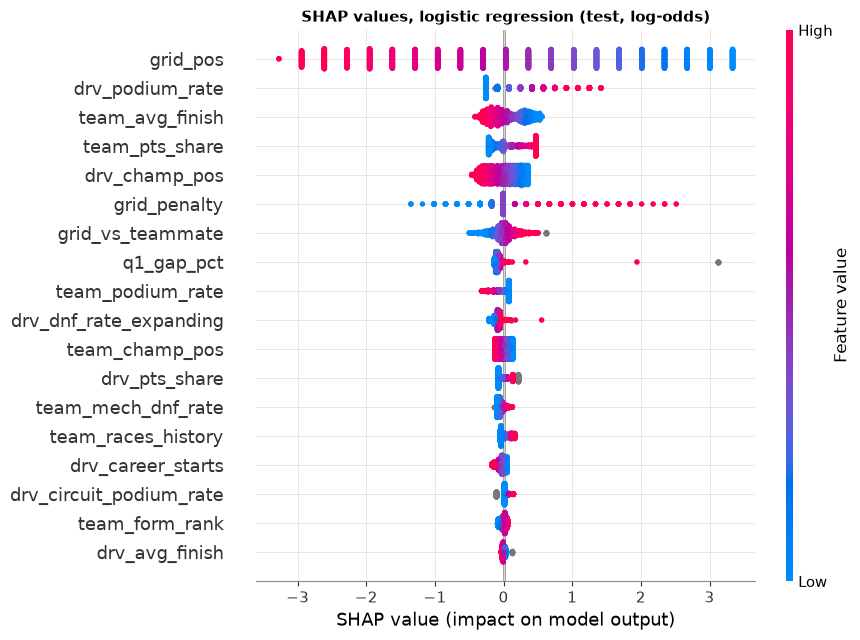

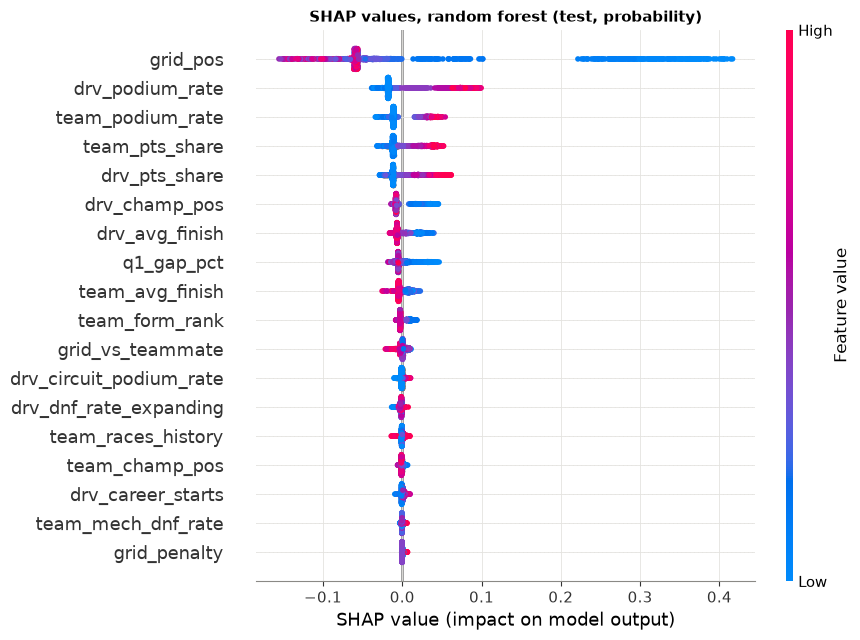

In [115]:
# SHAP beeswarm plots for both models
for name, values in [("logistic regression", lr_shap), ("random forest", rf_shap)]:
    plt.figure()
    shap.summary_plot(values.values, Xe[FEATURES], feature_names=FEATURES, max_display=18, show=False, plot_size=(9, 6.5))
    unit = "log-odds" if name == "logistic regression" else "probability"
    plt.title(f"SHAP values, {name} ({XAI_SET}, {unit})", fontweight="bold", fontsize=11)
    plt.tight_layout()
    savefig(plt.gcf(), f"p9_shap_beeswarm_{name.replace(' ', '_')}")
    plt.show()

**Reading a beeswarm:** one dot per test row; x = SHAP value (right = towards a podium); colour = the feature's value
(red high, blue low, grey missing); features sorted by mean |SHAP|.

**Hints.**
* `grid_pos` is first in both models: up to ±3.3 log-odds in the LR; +0.2 to +0.4 probability for a top-3 slot in
  the RF.
* The directions make sense: a high recent podium rate, a high points share, a good championship position and a small
  Q1 gap push towards a podium. A grid penalty pushes *up* given the slot (5.2).
* Correlated features can flip sign in the LR: `team_podium_rate` gets a small negative contribution (its partners
  already carry the "fast car" effect); the RF gives it the expected positive sign → importance ≠ causal effect.
* Grey points far right on `q1_gap_pct` (LR) = rows without a Q1 time (see Phase 10, demonstration 3).
* `E[f(x)]`: LR −3.7 log-odds (≈ 0.02) = the prediction for an average background row; RF 0.14 = the average
  predicted probability.

### 9.4 Comparing the methods

In [116]:
# rank the features by each method (permutation, SHAP) for both models
mean_abs = pd.DataFrame({"LR mean |SHAP| (log-odds)": lr_shap.abs().mean(), "RF mean |SHAP| (probability)": rf_shap.abs().mean()})
ranks = pd.DataFrame({
    "LR permutation": perm["logistic regression"]["mean drop"].rank(ascending=False),
    "LR SHAP": mean_abs.iloc[:, 0].rank(ascending=False),
    "RF permutation": perm["random forest"]["mean drop"].rank(ascending=False),
    "RF SHAP": mean_abs.iloc[:, 1].rank(ascending=False),
}).astype(int)
ranks["group"] = pd.Series(feature_group)
comparison_xai = pd.concat([mean_abs.round(3), ranks], axis=1).sort_values("LR SHAP")
comparison_xai

,LR mean |SHAP| (log-odds),RF mean |SHAP| (probability),LR permutation,LR SHAP,RF permutation,RF SHAP,group
grid_pos,1.655,0.099,1,1,1,1,grid
drv_podium_rate,0.321,0.029,2,2,10,2,driver form
team_avg_finish,0.215,0.006,5,3,3,9,constructor form
team_pts_share,0.196,0.018,6,4,4,4,standings
drv_champ_pos,0.195,0.012,7,5,9,6,standings
grid_penalty,0.131,0.000,4,6,12,18,grid
grid_vs_teammate,0.122,0.003,18,7,8,11,circuit & teammate
q1_gap_pct,0.117,0.009,3,8,2,8,qualifying
team_podium_rate,0.091,0.019,9,9,5,3,constructor form
drv_dnf_rate_expanding,0.086,0.002,8,10,16,13,reliability


**Hints.** All four rankings put `grid_pos` first; driver form, the standings and qualifying pace are in the upper
half for both models. They differ on the correlated strength features (e.g. `team_avg_finish` 3rd by LR SHAP, 9th by
RF SHAP). Agreement on the top features is what matters.

### 9.5 Local explanations: one prediction

**2024 São Paulo GP, Max Verstappen:** qualified 12th, five-place engine penalty, started **17th**, and won: the slot
and the driver/team strength point in opposite directions. For contrast: the test row with the highest predicted
probability.

In [117]:
# the two rows explained locally: Verstappen 2024 Sao Paulo (started 17th) and the highest predicted probability
row_ids = sets[XAI_SET][["raceId", "driverId", "year"]]
case = {"Verstappen, 2024 São Paulo GP (started 17th)": Xe.index.get_loc(row_ids.index[(row_ids["raceId"] == 1141) & (row_ids["driverId"] == 830)][0])}
lr_proba_test = logreg_default.predict_proba(Xe)[:, 1]
top = int(np.argmax(lr_proba_test))
top_row = sets[XAI_SET].iloc[top]
top_name = pd.read_csv(PROC_DIR / "drivers.csv").set_index("driverId").loc[top_row["driverId"], "surname"]
top_race = pd.read_csv(PROC_DIR / "races.csv").set_index("raceId").loc[top_row["raceId"], "name"]
case[f"{top_name}, {int(top_row['year'])} {top_race} (highest predicted probability)"] = top

for label, pos in case.items():
    print(f"{label}: P(podium) LR = {lr_proba_test[pos]:.3f}, RF = {forest_tuned.predict_proba(Xe.iloc[[pos]])[0, 1]:.3f} | "
          f"actual podium: {bool(ye.iloc[pos])} | LR decision at threshold {ATTEMPTS['A1 logistic regression (default)']['threshold']:.3f}: "
          f"{lr_proba_test[pos] >= ATTEMPTS['A1 logistic regression (default)']['threshold']}")
display(Xe.iloc[list(case.values())].T.round(3).set_axis(list(case), axis=1))

Verstappen, 2024 São Paulo GP (started 17th): P(podium) LR = 0.036, RF = 0.243 | actual podium: True | LR decision at threshold 0.287: False
Verstappen, 2023 Dutch Grand Prix (highest predicted probability): P(podium) LR = 0.881, RF = 0.846 | actual podium: True | LR decision at threshold 0.287: True


,"Verstappen, 2024 São Paulo GP (started 17th)","Verstappen, 2023 Dutch Grand Prix (highest predicted probability)"
grid_pos,17.000,1.000
grid_penalty,5.000,0.000
q1_gap_pct,0.000,0.032
drv_podium_rate,0.400,1.000
drv_avg_finish,4.000,1.100
drv_career_starts,205.000,175.000
team_podium_rate,0.200,0.750
team_avg_finish,7.150,2.950
team_form_rank,7.000,1.000
team_races_history,389.000,359.000


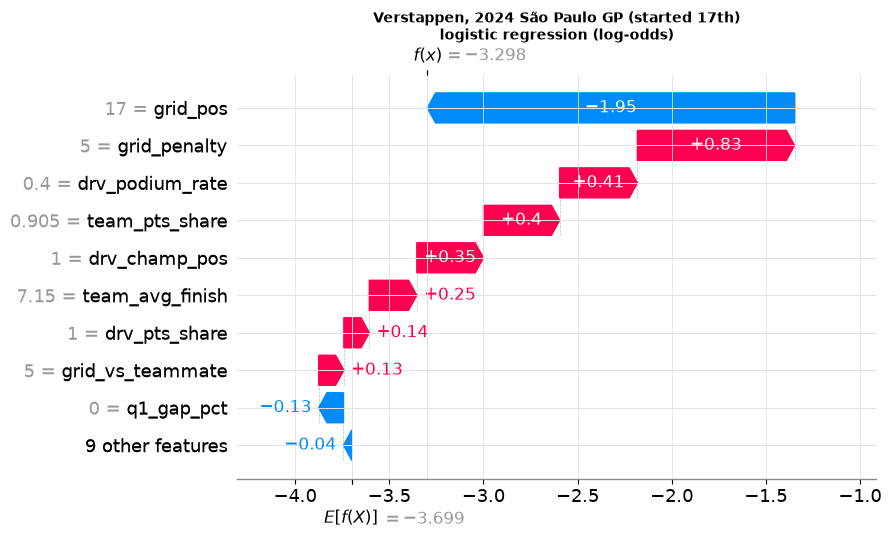

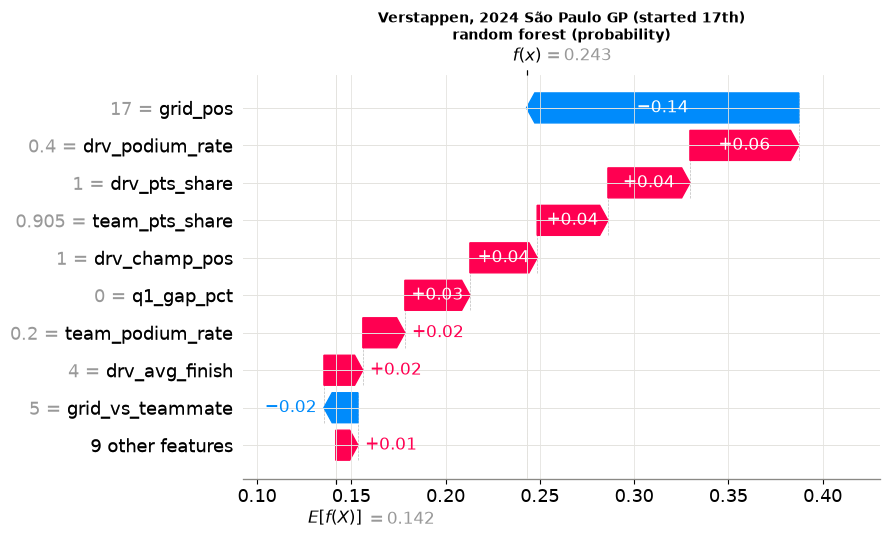

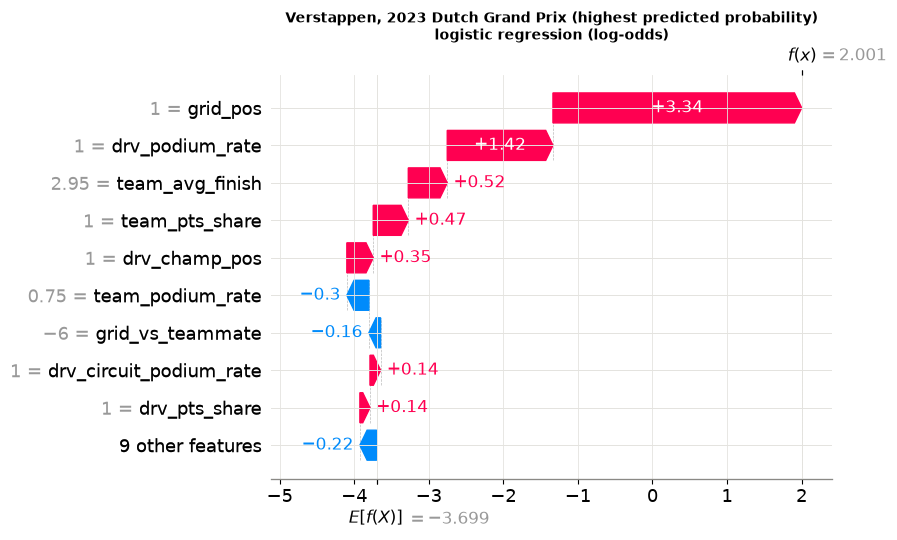

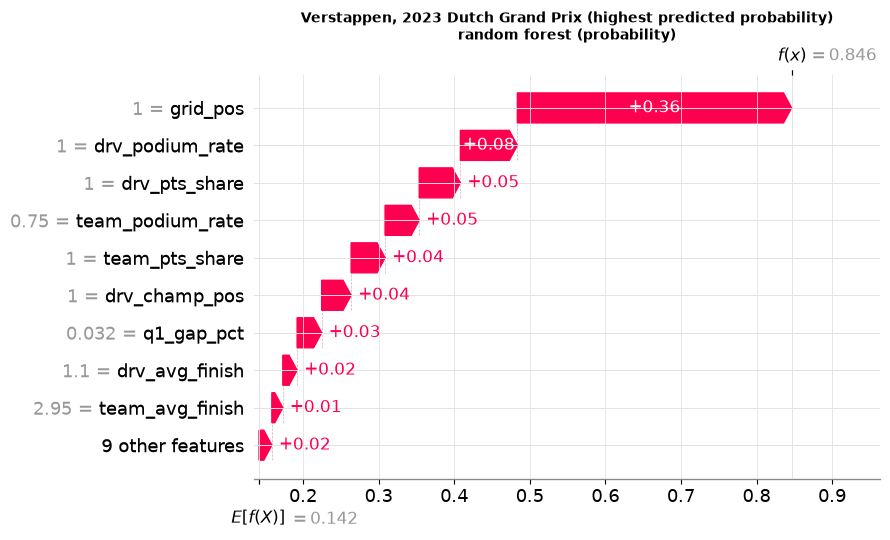

In [118]:
# SHAP waterfall of each explained row, for both models
for k, (label, pos) in enumerate(case.items()):
    for name, values, base in [("logistic regression", lr_shap, lr_base), ("random forest", rf_shap, rf_base)]:
        explanation = shap.Explanation(values=values.iloc[pos].values, base_values=base,
                                       data=Xe.iloc[pos].round(3).values, feature_names=FEATURES)
        plt.figure()
        shap.plots.waterfall(explanation, max_display=10, show=False)
        unit = "log-odds" if name == "logistic regression" else "probability"
        plt.title(f"{label}\n{name} ({unit})", fontsize=10, fontweight="bold")
        plt.gcf().set_size_inches(9, 5.5)
        plt.tight_layout()
        savefig(plt.gcf(), f"p9_shap_waterfall_case{k + 1}_{name.replace(' ', '_')}")
        plt.show()

**Reading a waterfall:** starts at the average output `E[f(x)]` and adds one feature per bar (red up, blue down)
until this row's output `f(x)`.

**Hints.**
* **São Paulo 2024**
  - LR: `grid_pos = 17` −1.95 log-odds; penalty +0.83, recent podium rate +0.41, team points share +0.40, championship
    lead +0.35 → **P = 0.036**, no podium (threshold 0.287). Additive: it cannot express "the slot matters less for a
    dominant driver".
  - RF: slot −0.14; form +0.06, points share and championship position +0.04 each, Q1 pace +0.035 → **P = 0.243**,
    just below its threshold (0.257); ~7× the LR probability (trees partly capture the interaction).
* **Dutch GP 2023 (P = 0.881):** pole +3.3 log-odds, a podium in each of his last 10 races +1.42, best team form,
  championship lead. The small negative bars are correlated-feature corrections.
* These explain the **model's** estimate, not why Verstappen won.

**LIME:** fits a small linear model to the selected model's predictions on thousands of perturbed copies of one row,
and reports which feature *ranges* drive it. Missing values are filled with the training median.

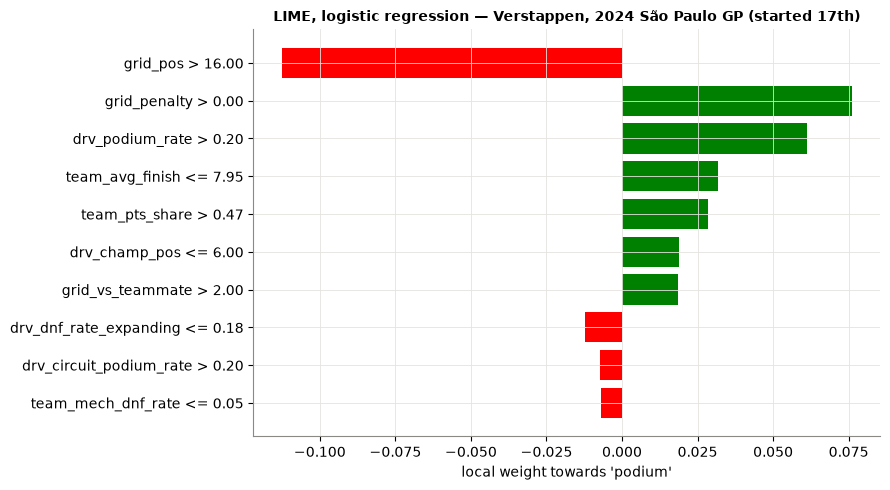

LIME local model: intercept 0.077, local prediction 0.172, model prediction 0.036, local fit R² 0.24 | actual podium: True


,rule (around this row),weight
0,grid_pos > 16.00,-0.113
1,grid_penalty > 0.00,0.076
2,drv_podium_rate > 0.20,0.061
3,team_avg_finish <= 7.95,0.032
4,team_pts_share > 0.47,0.028
5,drv_champ_pos <= 6.00,0.019
6,grid_vs_teammate > 2.00,0.019
7,drv_dnf_rate_expanding <= 0.18,-0.012
8,drv_circuit_podium_rate > 0.20,-0.007
9,team_mech_dnf_rate <= 0.05,-0.007


In [119]:
# this cell uses the data and the models created in Phases 6-9: run the notebook from the top (Run All) first
missing = [name for name in ["X", "FEATURES", "logreg_default", "case", "lr_proba_test"] if name not in globals()]
if missing:
    raise RuntimeError(f"{missing} not defined - run all cells above this one first (Phases 6-9)")

train_filled = X["train"].fillna(X["train"].median())
lime_explainer = LimeTabularExplainer(train_filled.values, feature_names=FEATURES, class_names=["no podium", "podium"],
                                      mode="classification", discretize_continuous=True, random_state=SEED)
predict_fn = lambda arr: logreg_default.predict_proba(pd.DataFrame(arr, columns=FEATURES))


def explain_with_lime(pos, label, figure_name):
    """LIME explanation of the logistic regression for one test row (missing inputs filled with training medians)."""
    explanation = lime_explainer.explain_instance(Xe.iloc[pos].fillna(X["train"].median()).values, predict_fn,
                                                  num_features=10, num_samples=5000)
    fig = explanation.as_pyplot_figure(label=1)
    fig.set_size_inches(9, 5)
    plt.title(f"LIME, logistic regression — {label}", fontsize=10, fontweight="bold")
    plt.xlabel("local weight towards 'podium'")
    plt.tight_layout()
    savefig(fig, figure_name)
    plt.show()
    print(f"LIME local model: intercept {explanation.intercept[1]:.3f}, local prediction {explanation.local_pred[0]:.3f}, "
          f"model prediction {lr_proba_test[pos]:.3f}, local fit R² {explanation.score:.2f} | actual podium: {bool(ye.iloc[pos])}")
    return pd.DataFrame(explanation.as_list(label=1), columns=["rule (around this row)", "weight"]).round(3)


verstappen_label, verstappen_pos = list(case.items())[0]
explain_with_lime(verstappen_pos, verstappen_label, "p9_lime_verstappen_2024")

**Hints.** Same forces as SHAP (`grid_pos > 16` is the strongest push away; the penalty, a podium rate above 20% and a
strong team push towards). Poor local fit (R² 0.24; local prediction 0.17 vs the model's 0.036): a rare row at the
edge of the data → SHAP (exact for the LR) is the reference explanation.

**LIME for a podium:** the test row with the highest predicted probability (the second case above), to compare with its
SHAP waterfall.

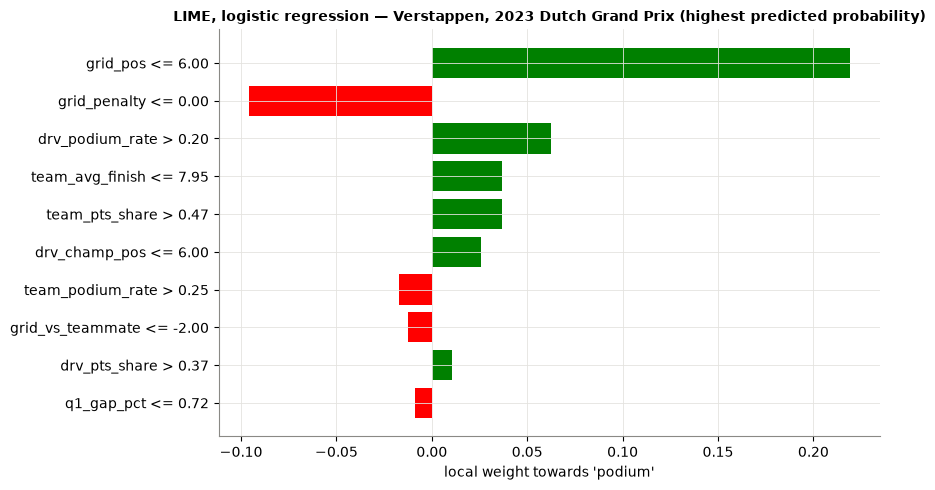

LIME local model: intercept 0.082, local prediction 0.339, model prediction 0.881, local fit R² 0.69 | actual podium: True


,rule (around this row),weight
0,grid_pos <= 6.00,0.219
1,grid_penalty <= 0.00,-0.096
2,drv_podium_rate > 0.20,0.062
3,team_avg_finish <= 7.95,0.037
4,team_pts_share > 0.47,0.037
5,drv_champ_pos <= 6.00,0.026
6,team_podium_rate > 0.25,-0.017
7,grid_vs_teammate <= -2.00,-0.012
8,drv_pts_share > 0.37,0.011
9,q1_gap_pct <= 0.72,-0.009


In [120]:
# LIME for the row with the highest predicted probability (an actual podium)
podium_label, podium_pos = list(case.items())[1]
assert ye.iloc[podium_pos] == 1, "this row is an actual podium"
explain_with_lime(podium_pos, podium_label, "p9_lime_podium_case")

**Hints.** Strongest rule `grid_pos ≤ 6` (+0.22), then a podium rate above 20% (+0.06), a strong team (+0.04 each)
and a top-6 championship position (+0.03): same order as SHAP. `grid_penalty ≤ 0` counts slightly against (no penalty
= the slot is all there is). Better fit (R² 0.69), but the coarse ranges under-estimate the probability (0.34 vs
0.88).

## 10. Inference function

One pre-race record → podium probability, using the fitted pipeline of the selected model (same medians, indicators
and scaling as in training).

* Input: a `dict` of the 18 features; missing or `None` fields → NaN → training median, missing indicator on.
* Rejects post-race fields (leakage) and unknown field names; **warns** if `grid_pos` or `q1_gap_pct` is missing
  (both are known after qualifying).
* Output: the probability; the validation threshold is available separately for a yes/no decision.

In [121]:
# the inference function: one pre-race record -> podium probability, using the selected fitted pipeline
import warnings

FINAL_MODEL = logreg_default
FINAL_THRESHOLD = ATTEMPTS["A1 logistic regression (default)"]["threshold"]
KNOWN_AFTER_QUALIFYING = ["grid_pos", "q1_gap_pct"]          # always available at the prediction cutoff


def predict_podium(record: dict) -> float:
    """Probability that a driver finishes on the podium, from pre-race features only.

    `record` maps feature names (see FEATURES) to values; missing or None fields are imputed by the fitted pipeline.
    """
    leaked = set(record) & set(FORBIDDEN)
    if leaked:
        raise ValueError(f"post-race fields are not allowed as input (leakage): {sorted(leaked)}")
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"unknown fields: {sorted(unknown)}; expected a subset of {FEATURES}")
    row = pd.DataFrame([{f: record.get(f) for f in FEATURES}]).astype(float)   # None / absent -> NaN
    missing_core = [f for f in KNOWN_AFTER_QUALIFYING if row[f].isna().iat[0]]
    if missing_core:
        warnings.warn(f"{missing_core} missing: these are known after qualifying; without them the model "
                      f"extrapolates (see demonstration 3)", stacklevel=2)
    return float(FINAL_MODEL.predict_proba(row)[0, 1])


print("final model:", FINAL_MODEL.named_steps["model"].__class__.__name__, "| decision threshold (from validation):",
      round(FINAL_THRESHOLD, 3))

final model: LogisticRegression | decision threshold (from validation): 0.287


**Demonstration 1 — a complete record:** a real test row with all 18 features.

In [122]:
# demonstration 1: a complete real test record
complete_pos = int(np.flatnonzero(Xe.notna().all(axis=1).values & (ye.values == 1))[0])
complete_ids = sets[XAI_SET].iloc[complete_pos]
complete_record = {f: float(v) for f, v in Xe.iloc[complete_pos].items()}
p_complete = predict_podium(complete_record)

assert np.isclose(p_complete, lr_proba_test[complete_pos]), "the function reproduces the pipeline"
print(f"raceId {int(complete_ids['raceId'])}, driverId {int(complete_ids['driverId'])}, {int(complete_ids['year'])} | "
      f"P(podium) = {p_complete:.3f} | decision: {'podium' if p_complete >= FINAL_THRESHOLD else 'no podium'} | "
      f"actual: {'podium' if complete_ids['podium'] else 'no podium'}")
pd.Series(complete_record, name="value").round(3).to_frame().T

raceId 1075, driverId 830, 2022 | P(podium) = 0.291 | decision: podium | actual: podium


,grid_pos,grid_penalty,q1_gap_pct,drv_podium_rate,drv_avg_finish,drv_career_starts,team_podium_rate,team_avg_finish,team_form_rank,team_races_history,drv_dnf_rate_expanding,team_mech_dnf_rate,drv_pts_share,drv_champ_pos,team_pts_share,team_champ_pos,drv_circuit_podium_rate,grid_vs_teammate
value,4.0,0.0,0.082,0.8,5.0,142.0,0.55,6.55,3.0,326.0,0.211,0.15,0.0,19.0,0.0,10.0,1.0,3.0


**Demonstration 2 — a partially missing record:** the same driver and race as it would look at a season opener at a
new circuit (no standings, no circuit history: 5 fields missing). Grid and qualifying are kept.

In [123]:
# demonstration 2: the same record as at the first race of a season at a new circuit (5 fields missing)
removed = ["drv_pts_share", "drv_champ_pos", "team_pts_share", "team_champ_pos", "drv_circuit_podium_rate"]
partial_record = {f: v for f, v in complete_record.items() if f not in removed}
partial_record["drv_circuit_podium_rate"] = None                     # "explicitly unknown" works as well as absent
p_partial = predict_podium(partial_record)

row = pd.DataFrame([{f: partial_record.get(f) for f in FEATURES}]).astype(float)
filled = pd.Series(FINAL_MODEL.named_steps["prep"].named_steps["impute"].transform(row)[0][:len(FEATURES)], index=FEATURES)
print(f"P(podium) with the full record: {p_complete:.3f} | with {len(removed)} fields missing: {p_partial:.3f}")
pd.DataFrame({"given": pd.Series(partial_record).reindex(removed), "imputed (training median)": filled[removed],
              "full record": pd.Series(complete_record)[removed]}).round(3)

P(podium) with the full record: 0.291 | with 5 fields missing: 0.533


,given,imputed (training median),full record
drv_pts_share,NaN,0.121,0.0
drv_champ_pos,NaN,11.000,19.0
team_pts_share,NaN,0.145,0.0
team_champ_pos,NaN,6.000,10.0
drv_circuit_podium_rate,NaN,0.000,1.0


**Demonstration 3 — limitation, Q1 time missing:** the same complete record without `q1_gap_pct`. The table shows the
LR contribution (weight × scaled input, in log-odds) of the columns that change.

In [124]:
# demonstration 3: the same complete record without the Q1 gap (a limitation)
no_q1_record = {**complete_record, "q1_gap_pct": None}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    p_no_q1 = predict_podium(no_q1_record)
print(f"P(podium) full record: {p_complete:.3f} | without the Q1 gap: {p_no_q1:.3f}")
print("warning raised:", caught[0].message if caught else None)

prep_final, model_final = FINAL_MODEL.named_steps["prep"], FINAL_MODEL.named_steps["model"]
columns_final = prep_final.get_feature_names_out()
z_full = prep_final.transform(pd.DataFrame([complete_record]).astype(float)[FEATURES])[0]
z_no_q1 = prep_final.transform(pd.DataFrame([{f: no_q1_record.get(f) for f in FEATURES}]).astype(float))[0]
contribution = pd.DataFrame({"weight": model_final.coef_[0], "scaled input, full": z_full, "scaled input, no Q1": z_no_q1},
                            index=columns_final)
contribution["change in log-odds"] = contribution["weight"] * (contribution["scaled input, no Q1"] - contribution["scaled input, full"])
print("share of training rows without a Q1 time:", round(X["train"]["q1_gap_pct"].isna().mean(), 3))
contribution[contribution["change in log-odds"].abs() > 1e-9].round(3)

P(podium) full record: 0.291 | without the Q1 gap: 0.913
warning raised: ['q1_gap_pct'] missing: these are known after qualifying; without them the model extrapolates (see demonstration 3)
share of training rows without a Q1 time: 0.018


,weight,"scaled input, full","scaled input, no Q1",change in log-odds
q1_gap_pct,0.084,-0.936,-0.238,0.058
missingindicator_q1_gap_pct,0.424,-0.135,7.389,3.189


**Demonstration 4 — edge cases:** only the grid slot; a debutant at the back of the grid; a record with a post-race
field.

In [125]:
# demonstration 4: a minimal record, a debutant at the back, and a record with a post-race field
edge_cases = {
    "only grid_pos = 1 (everything else missing)": {"grid_pos": 1},
    "debutant starting 18th, new team": {"grid_pos": 18, "grid_penalty": 0, "q1_gap_pct": 2.5, "drv_career_starts": 0,
                                         "team_races_history": 0},
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")              # the warning was shown in demonstration 3
    display(pd.Series({k: round(predict_podium(r), 3) for k, r in edge_cases.items()}, name="P(podium)").to_frame())

try:
    predict_podium({"grid_pos": 1, "positionOrder": 1})
except ValueError as error:
    print("rejected:", error)

,P(podium)
only grid_pos = 1 (everything else missing),0.607
"debutant starting 18th, new team",0.005


rejected: post-race fields are not allowed as input (leakage): ['positionOrder']


**Hints.**
* Complete record: P = 0.291 → podium at the threshold 0.287; actual: podium. Matches the pipeline's output exactly.
* Partial record: P = 0.533. The real record said "0 points, 19th" (he retired in the opener); missing standings are
  replaced by a typical driver → a missing value is not neutral.
* Q1 missing: P = 0.913, almost entirely through the rare missing indicator (1.8% of training rows → ~7 SD once
  scaled); "no Q1 time but a top-5 grid slot" never occurs in training, so the model extrapolates → hence the warning.
  Possible fix: leave the indicators unscaled, or drop this one.
* Edge cases: only grid 1 → 0.607 (extreme extrapolation, not trustworthy); debutant starting 18th → 0.005; post-race
  field → rejected.

## 11. Summary and limitations

### Cleaning and modelling choices

| Step | What was done | Evidence |
|---|---|---|
| scope | all seasons 1950–2024 kept for the audit, EDA and data-engineering questions | 2.1 |
| labels | `United States` → `USA`, `'Argentinian '` → `Argentine`, `&amp;` → `&` | 1.6, 3.1 |
| Indianapolis 500 | removed (11 races, 405 rows) | 2.4, 3.2 |
| non-starters | removed with the four-condition rule (1,717 rows, no podium); empty grid slots stay empty | 2.5, 3.3 |
| pit-lane starters | grid = last slot + 1, plus `pitlane_start` (72 rows, kept in `base`, not a model feature) | 2.6, 3.4, 5.9 |
| shared drives | one row per car, credited to the driver who started it (starter rules 9/9 correct on documented cases) | 2.7, 3.5–3.7 |
| finishing order | renumbered 1…N (18 values in 3 races, no podium changed) | 3.8 |
| target | `podium = positionOrder <= 3`, defined once on the cleaned table | 3.9 |
| grid ties | kept as recorded and documented (4 races since 2003) | 3.10 |
| Phase 4 definitions | front row = grid 1–2; home = nationality country = circuit country; status groups and team lineages | Phase 4 |
| modelling window | rows from 2003 (complete qualifying); history features use all earlier races | 2.2 |
| split | by season: train 2003–2019, validation 2020–2021, test 2022–2024 | 6.1 |
| features | 18 features in 7 groups, form window N = 10 races, leakage-checked | Phase 5 |
| preprocessing | median imputation + missing indicators (+ scaling for the linear and network models), fitted on train only | 6.3–6.5, 8.2–8.3 |
| selection | hyperparameters by validation PR-AUC; threshold = best F1 on validation; no refit on train + validation | 7.0 |

### Key results

* **Cleaned table:** 24,554 rows (one row per driver who started a race), 1,114 races, exactly 3 podiums per race.
  **Modelling table:** 8,909 rows (train 6,782 / validation 775 / test 1,352), podium rate 14–15% in every set.
* **Data-engineering questions:** the front row converts far more often since 2014 (56% → 76%) and the circuit ranking
  changes almost completely (rank correlation −0.08); there is no home advantage once the grid is controlled
  (observed / expected podiums 0.95, interval 0.86–1.06); the Enstone team (Lotus / Renault / Alpine) has the highest
  mechanical-retirement rate in both periods, and failures fell from 9.8% to 5.9% of starts.
* **Models (test seasons, never used for a choice):**

| Model | PR-AUC (primary) | ROC-AUC | F1 | precision | recall |
|---|---|---|---|---|---|
| rule `grid ≤ 3` | 0.647 | 0.913 | 0.649 | 0.650 | 0.647 |
| **logistic regression (selected)** | 0.709 | 0.936 | 0.674 | 0.590 | 0.784 |
| random forest (tuned) | 0.716 | 0.936 | 0.672 | 0.558 | 0.843 |
| gradient boosting (tuned) | 0.723 | 0.937 | 0.685 | 0.612 | 0.779 |
| neural network (1 hidden layer) | 0.692 | 0.935 | 0.661 | 0.603 | 0.730 |

  Every model beats the starting-grid rule; the models differ by at most 0.03 PR-AUC, which is within the noise of a
  39-race validation set. The logistic regression was selected by the rule fixed in advance (validation PR-AUC, a tie
  with the network by 0.0002).
* **Experiments:** the grid is the only feature group the models cannot do without; driver form, constructor form and
  standings are worth ~0.02 PR-AUC together but replace each other individually. Impute → scale is at least as good as
  scale → impute; fitting the preprocessing on all seasons barely changes the logistic regression but changes the
  network, which is why everything is fitted on the training seasons only.
* **Explainability:** permutation importance and SHAP agree that the starting slot dominates, followed by recent driver
  form, team strength, the standings and qualifying pace. **These are statements about how the model predicts, not
  about what causes a podium.**

### Limitations

* **Qualifying-coverage drift:** qualifying data is missing before 1994 and patchy until 2002, so the models only learn
  from 2003 onwards; qualifying-based features cannot be used for older seasons.
* **Era sensitivity:** the test seasons are a new technical era with a more experienced grid (`drv_career_starts` +0.67
  training standard deviations) and a closer field (`q1_gap_pct` −0.39). Scores held up, but relationships such as
  "a P1–P3 start converts ~67% of the time" have changed before (≈45% in the 1960s–80s) and can change again.
* **Renamed and re-used constructors:** a renamed team starts with no history (Brawn 2009 won with none), and re-used
  IDs are split into stints by a rule (a season without races), not by ownership.
* **Small samples:** circuits have 14–26 front-row starts since 2014 (Q1), and the validation set has 39 races, so the
  order of models or circuits that are close is uncertain.
* **Data issues kept:** 27 shared cars rely on file order to identify the starter, and 19 podium credits of 1950–1964
  are removed (counts differ slightly from official records); the 1983 Brazilian GP target follows `positionOrder`;
  grid ties are kept as recorded; a few 0-lap "Retired" rows may be non-starters.
* **Model behaviour:** a record without a Q1 time is extrapolated (Phase 10, demonstration 3); at the chosen threshold
  the selected model flags about 4 cars per race, so its precision is ~0.59; LIME fits poorly for unusual rows, so SHAP
  is the reference explanation.
* **Brief:** the metric table lists three metrics but the deliverables ask for five; we report ROC-AUC, PR-AUC, F1,
  precision and recall for every model and set.